# MLP＋反向傳播（1986）

- **核心原理**：鏈鎖律計算梯度、非線性激活函數
- **變體**：各種激活函數（Sigmoid、Tanh、ReLU）、初始化（Xavier、He）
- **推薦資料集**：MNIST（60,000 訓練／10,000 測試，28×28 灰階手寫數字，10 類）

本章依照 README 的「每章標準流程」：EDA → Baseline → 手寫模型 → 套件實作 → 調參 → 測試集評估 → 診斷 → 本章小結。

和第一章的差別：

| | 第一章 | 本章 |
| --- | --- | --- |
| 手寫模型 | NumPy | NumPy（**層層模組化**：每一層都有 `forward`／`backward`，跟 PyTorch 的設計一樣） |
| 套件實作 | sklearn | **PyTorch**（autograd 自動算梯度 → 跟手寫的反向傳播逐位比對） |
| 驗證方式 | 5-fold CV | **固定的驗證集**（從 60,000 筆切 10,000 筆）—— 理由見 TODO 2 (1) |
| 訓練 | 一次 `fit` 到收斂 | **mini-batch SGD**、epoch、學習曲線、early stopping |

本章的核心是第 3 節：把反向傳播拆成「每一層只管自己的局部梯度」，再用鏈鎖律串起來。
寫完之後，第 4 節 PyTorch 的 `loss.backward()` 就不再是黑盒子。

---
## 1. 資料與探索性資料分析（EDA）

觀察直接寫在每格程式最上面的註解（`# 觀察：`）。每格附了一兩個引導問題，回答完就可以把問題刪掉。

In [127]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from ml_dl_llm.data import load_mnist

train_ds, test_ds = load_mnist(flatten=True)

# torchvision 的 Dataset 每取一筆就跑一次 transform（慢）。
# 整批運算時直接取底層的 uint8 張量，再自己做同樣的前處理（本節最後一格會核對兩者一致）。
X_full_u8 = train_ds.data.numpy().reshape(
    len(train_ds), -1
)  # (60000, 784)，0–255 的整數
y_full = train_ds.targets.numpy()  # (60000,)，0–9
X_test_u8 = test_ds.data.numpy().reshape(len(test_ds), -1)  # (10000, 784)
y_test = test_ds.targets.numpy()

print("train / test：", X_full_u8.shape, X_test_u8.shape, " dtype：", X_full_u8.dtype)
print("像素範圍：", X_full_u8.min(), "～", X_full_u8.max())

train / test： (60000, 784) (10000, 784)  dtype： uint8
像素範圍： 0 ～ 255


In [128]:
# 觀察：
#   - 10 類各佔多少？最多和最少的類別差幾倍？
#     10類大約都各佔9~11%左右，最多（1：11.24%）與最少（5：9.04%）的類別差了0.1124/0.0904 = 1.2倍
#   - 「永遠猜最多的那一類」的 accuracy 大約多少？
#     永遠猜最多的那一類（1），正確率大約只有11.24%（測試集 11.35%）
counts = pd.DataFrame(
    {
        "train": pd.Series(y_full).value_counts().sort_index(),
        "test": pd.Series(y_test).value_counts().sort_index(),
    }
)
counts["train_ratio"] = (counts["train"] / counts["train"].sum()).round(4)
counts["test_ratio"] = (counts["test"] / counts["test"].sum()).round(4)
display(counts)

,train,test,train_ratio,test_ratio
0,5923,980,0.0987,0.0980
1,6742,1135,0.1124,0.1135
2,5958,1032,0.0993,0.1032
3,6131,1010,0.1022,0.1010
4,5842,982,0.0974,0.0982
5,5421,892,0.0904,0.0892
6,5918,958,0.0986,0.0958
7,6265,1028,0.1044,0.1028
8,5851,974,0.0975,0.0974
9,5949,1009,0.0992,0.1009


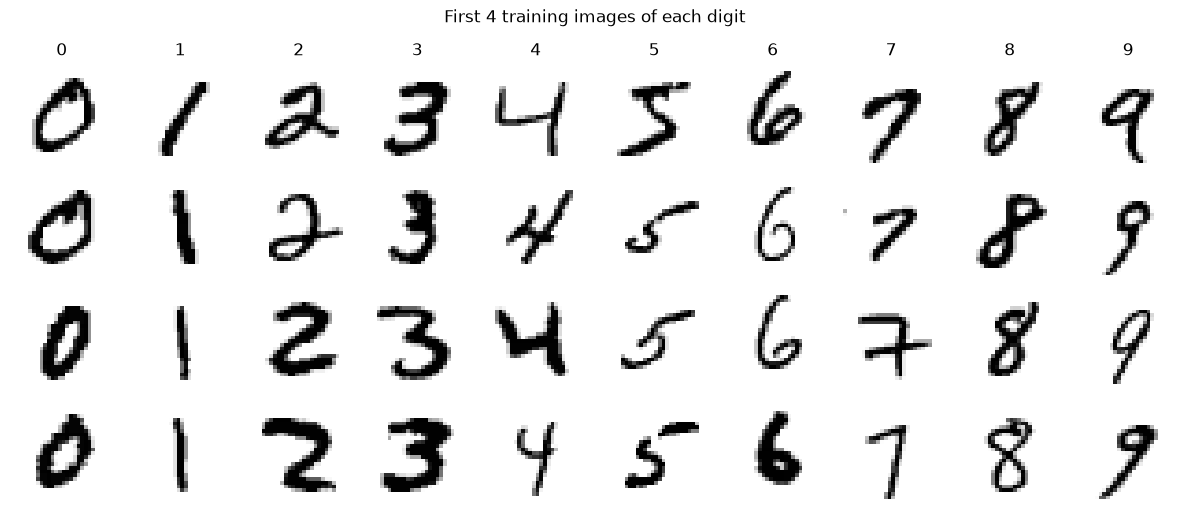

In [129]:
# 觀察：
#   - 同一個數字的寫法差異有多大（粗細、傾斜、大小、位置）？哪些數字看起來容易互相混淆？
#     7, 9相像、5, 8相像，應該是傾斜角度很像
#     修正：容易混淆的主因是「共用筆畫結構」，不是傾斜角度：
#       4–9 只差上方是開口還是封閉的圈；7–9 共用上方的橫線／圈與往左下的斜線；3–5–8 共用右下半的弧。
#       傾斜是「同一個數字內」差異最大的來源之一，會讓不同數字的筆畫位置重疊得更多，屬於加劇因素。
#     補充（寫法差異）：MNIST 已做過大小與位置的正規化 —— 每個數字縮放進 20×20 的框（保持長寬比），
#       再依質心放到 28×28 的中央。實測墨水高度：中位數 20、5–95% 分位數 18–20；寬度 8–20（「1」很窄）。
#       → 大小、位置的變化很小；剩下的差異主要是傾斜、筆畫粗細與寫法（7 有沒有橫槓、4 開口或封口等）。
fig, axes = plt.subplots(4, 10, figsize=(12, 5.2))
for digit in range(10):
    idx = np.flatnonzero(y_full == digit)[:4]
    for row, i in enumerate(idx):
        axes[row, digit].imshow(X_full_u8[i].reshape(28, 28), cmap="gray_r")
        axes[row, digit].axis("off")
    axes[0, digit].set_title(str(digit))
fig.suptitle("First 4 training images of each digit")
fig.tight_layout()
plt.show()

像素值 = 0 的比例：0.809   像素值 ≥ 250 的比例：0.074
全部影像都是 0 的像素位置：67 / 784
整體平均 / 標準差（0–1 尺度）：0.1307 / 0.3081


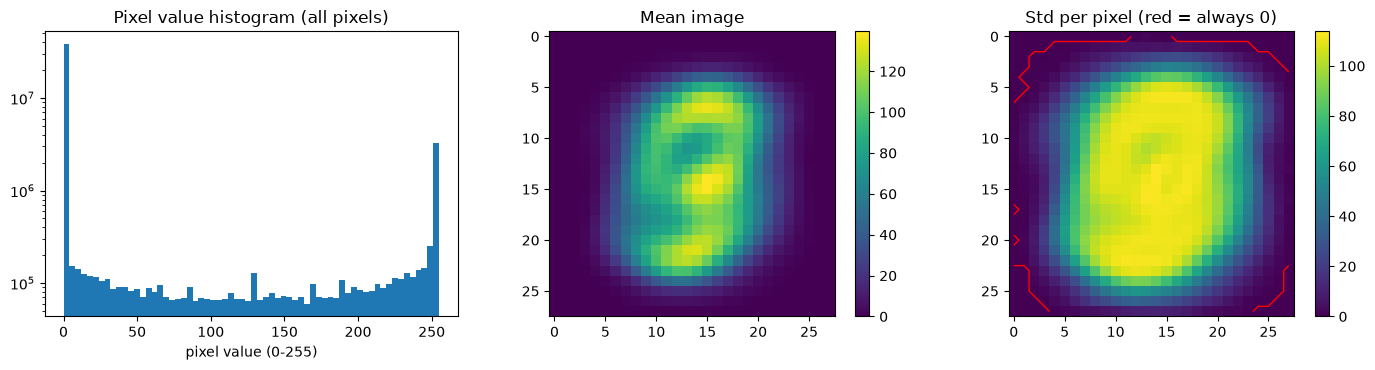

In [130]:
# 像素值的分布與每個位置的統計量
# 觀察：
#   - 像素值的分布長什麼樣（看左圖，y 軸是 log 尺度）？有多少比例的像素值是 0？
#     分布在0以及255最多，有80.9%的比例像素值是0
#     補充：兩極化（bimodal）—— 80.9% 是 0（背景）、7.4% ≥ 250（筆畫中心），中間值只佔約 11.8%，
#       是筆畫邊緣的反鋸齒（anti-aliasing）灰階。→ 很接近黑白二值影像，資訊集中在「哪裡有墨水」。
#   - 有幾個像素位置在 60,000 張訓練影像中「全部是 0」？它們在影像的哪裡（看中、右圖）？
#     有大約67個位置的像素全部都是0，分布在影像的邊緣
#     修正：剛好 67 個（不是大約）。不是平均分布在四邊，而是集中在最上、最下幾列與四個角落：
#       第 0 列 28 格中有 24 格、第 27 列有 8 格；左右兩邊的中段幾乎都偶爾有墨水（寬的數字、傾斜的筆畫會碰到）。
vals = X_full_u8.ravel()
always_zero = (X_full_u8 == 0).all(axis=0)  # (784,) 布林：這個位置在所有訓練影像都是 0
print(
    f"像素值 = 0 的比例：{(vals == 0).mean():.3f}   像素值 ≥ 250 的比例：{(vals >= 250).mean():.3f}"
)
print(f"全部影像都是 0 的像素位置：{always_zero.sum()} / 784")
print(
    f"整體平均 / 標準差（0–1 尺度）：{vals.mean() / 255:.4f} / {vals.std() / 255:.4f}"
)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].hist(vals, bins=64)
axes[0].set_yscale("log")
axes[0].set_xlabel("pixel value (0-255)")
axes[0].set_title("Pixel value histogram (all pixels)")
im = axes[1].imshow(X_full_u8.mean(axis=0).reshape(28, 28), cmap="viridis")
axes[1].set_title("Mean image")
fig.colorbar(im, ax=axes[1])
im = axes[2].imshow(X_full_u8.std(axis=0).reshape(28, 28), cmap="viridis")
axes[2].contour(always_zero.reshape(28, 28), levels=[0.5], colors="r", linewidths=1)
axes[2].set_title("Std per pixel (red = always 0)")
fig.colorbar(im, ax=axes[2])
fig.tight_layout()
plt.show()

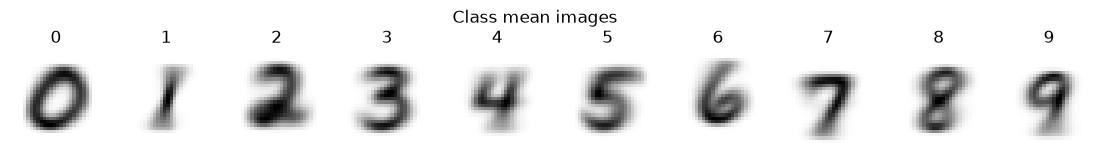

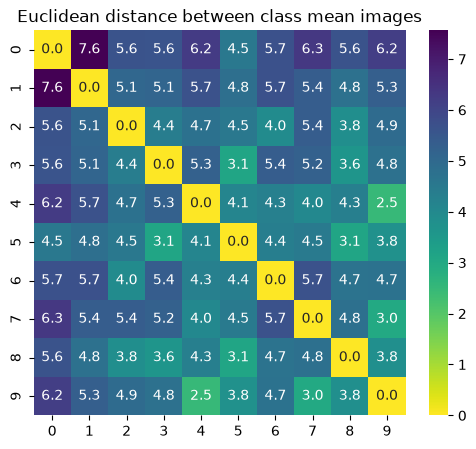

最接近的 5 對： {'4-9': 2.48, '7-9': 2.99, '5-8': 3.1, '3-5': 3.12, '3-8': 3.63}


In [131]:
# 每一類的平均影像，以及類別平均影像之間的距離
# 觀察：
#   - 哪幾對數字的平均影像最接近（距離最小）？猜猜看最後模型最常把哪些數字搞混。
#     (4, 9), (7, 9), (5, 8)這三組平均影像最接近，應該是4, 7, 9會很常搞混
#     補充：接著是 3–5（3.12）、3–8（3.63），所以 3、5、8 是另一個可能互相混淆的群。
#       平均影像只是粗略的線索：它把每一類的所有寫法平均掉了，看不到「少數寫法很像另一類」的情況（第 7 節驗證）。
class_means = np.stack(
    [X_full_u8[y_full == k].mean(axis=0) / 255 for k in range(10)]
)  # (10, 784)

fig, axes = plt.subplots(1, 10, figsize=(14, 1.8))
for k, ax in enumerate(axes):
    ax.imshow(class_means[k].reshape(28, 28), cmap="gray_r")
    ax.set_title(str(k))
    ax.axis("off")
fig.suptitle("Class mean images")
plt.show()

D = np.sqrt(
    ((class_means[:, None, :] - class_means[None, :, :]) ** 2).sum(-1)
)  # (10, 10)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(D, annot=True, fmt=".1f", cmap="viridis_r", ax=ax)
ax.set_title("Euclidean distance between class mean images")
plt.show()
pairs = pd.Series(
    D[np.triu_indices(10, k=1)],
    index=[f"{i}-{j}" for i, j in zip(*np.triu_indices(10, k=1))],
)
print("最接近的 5 對：", pairs.nsmallest(5).round(2).to_dict())

### 前處理與資料切分

- **前處理**：跟 `load_mnist(normalize="dataset")` 一樣，所有像素共用**一組**平均與標準差：$x \leftarrow (x/255 - 0.1307)/0.3081$。
- **切分**：60,000 筆訓練資料分成 **train 50,000／validation 10,000**（分層、固定 seed）。
  調參、選模型、early stopping 都只看 validation；測試集到第 6 節才用一次。

In [132]:
from sklearn.model_selection import train_test_split

MNIST_MEAN, MNIST_STD = 0.1307, 0.3081  # 與 ml_dl_llm.data.vision.STATS["mnist"] 相同


def preprocess(X_u8: np.ndarray) -> np.ndarray:
    """uint8 影像 (n, 784) → 標準化後的 float32 (n, 784)。全部像素共用一組 mean／std。"""
    return ((X_u8 / 255.0 - MNIST_MEAN) / MNIST_STD).astype(np.float32)


X_full = preprocess(X_full_u8)
X_test = preprocess(X_test_u8)
X_tr, X_va, y_tr, y_va = train_test_split(
    X_full, y_full, test_size=10_000, stratify=y_full, random_state=42
)
print("train / val / test：", X_tr.shape, X_va.shape, X_test.shape)
print(
    f"標準化後：mean = {X_tr.mean():.4f}、std = {X_tr.std():.4f}；"
    f"原本是 0 的像素變成 {preprocess(np.zeros((1, 1), np.uint8))[0, 0]:.4f}"
)

train / val / test： (50000, 784) (10000, 784) (10000, 784)
標準化後：mean = 0.0002、std = 1.0004；原本是 0 的像素變成 -0.4242


In [133]:
# 核對：自己做的前處理 = load_mnist 的 transform
x0, label0 = train_ds[
    0
]  # 走 torchvision 的 transform（ToImage → ToDtype → Normalize → Flatten）
print(
    "✅ 與 load_mnist transform 的最大差異：",
    np.abs(X_full[0] - x0.numpy()).max(),
    "（應 < 1e-6）",
)

✅ 與 load_mnist transform 的最大差異： 4.7683716e-07 （應 < 1e-6）


### TODO 1（問答）EDA 小結

> **(1)** 10 類的比例大約多少？「永遠猜最多的那一類」的 accuracy 是多少？accuracy 適合當這份資料的主要指標嗎？（對照第一章第三節的 Breast Cancer：良性 62.6%、惡性 37.4%，永遠猜良性就有 0.626，而且漏掉惡性的代價遠比誤判良性嚴重）

10 類各佔 9.0%（數字 5）～ 11.2%（數字 1），最多與最少只差 1.24 倍，幾乎平衡。永遠猜「1」的 accuracy = 0.1124（validation 用分層切分，也是 0.1124）。

accuracy 適合當主要指標：

- 類別平衡 → accuracy 的起點約 0.1，不會像 Breast Cancer（起點 0.626）那樣被多數類撐高。
- 每一種錯誤的代價相同（把 4 認成 9 不比把 3 認成 8 嚴重），不像 Breast Cancer「漏掉惡性」遠比誤判良性嚴重、必須另看惡性 recall。
- 輔助指標：log loss（機率品質，也是訓練的目標函數）與混淆矩陣（錯在哪幾類）。


> **(2)** 「永遠是 0」的像素位置，對 MLP 的學習有什麼影響？
>
> **(a)** 從上面的輸出讀：有幾個位置在所有訓練影像中都是 0？標準化之後，這些位置的值變成多少（還是 0 嗎）？
>
> **(b)** 3A 會推導：第一層 $z = xW + b$ 的權重梯度是 $\partial L/\partial W_{jk} = \sum_i x_{ij}\,\delta_{ik}$（$\delta_{ik} = \partial L/\partial z_{ik}$：loss 對第一層輸出 $z$ 的梯度，也就是 3A 的上游梯度 `dout`；下標 $i$ = batch 中第幾筆樣本、$j$ = 第幾個輸入像素、$k$ = 第幾個隱藏單元）。如果某個輸入 $x_j$ 對每一筆樣本都是 0，$W$ 的第 $j$ 列的梯度是多少？這一列權重在訓練中會怎麼變化？
>
> **(c)** 如果 $x_j$ 對每一筆都是同一個非 0 常數 $c$（標準化後的情況），第 $j$ 列的梯度變成什麼？跟 bias 的梯度 $\partial L/\partial b_k = \sum_i \delta_{ik}$ 比較，這一列權重實際上在扮演什麼角色？對測試影像會有影響嗎？

**(a)** 67 個。標準化後變成 $(0 - 0.1307)/0.3081 = -0.4242$，**不是 0**。

**(b)** $x_{ij} = 0$ 對所有樣本成立 → $\partial L/\partial W_{jk} = \sum_i 0 \cdot \delta_{ik} = 0$，整列梯度永遠是 0：

- 這一列權重停在初始值，永遠不動（加 weight decay 時只會被 $\lambda W$ 慢慢拉向 0）。
- 對輸出也沒有影響（$x_j W_{jk} = 0$）→ 沒用，但無害。

**(c)** $\partial L/\partial W_{jk} = \sum_i c\,\delta_{ik} = c \cdot \partial L/\partial b_k$：第 $j$ 列的梯度永遠是 bias 梯度的 $c$ 倍。

- **角色**：它對每一筆樣本都貢獻同一個常數 $c\,W_{jk}$，跟 $b_k$ 的作用完全一樣、分不開 → 等於多了 67 個「多餘的 bias」。真正有意義的只有總和 $b_k^{\text{eff}} = b_k + c\sum_{j} W_{jk}$（跟第一章 softmax 參數不可識別是同一類現象）。
- **副作用**：每一步 $\Delta b_k = -\text{lr}\cdot g$、$\Delta W_{jk} = -\text{lr}\cdot c\,g$，所以有效 bias 每步移動 $-\text{lr}\cdot g\,(1 + 67c^2) \approx -\text{lr}\cdot g \times 13$ → 第一層 bias 的有效學習率被放大約 13 倍。（不會壞事，但說明「常數輸入」不是完全中性的。）
- **測試影像**：實測測試集只有 1 張影像、在其中 2 個位置有墨水，其餘全是 $-0.4242$ → 跟訓練時一樣當 bias 用，沒有影響。那 1 張影像在這 2 個位置的值會乘上「當 bias 學出來」的權重，產生一個沒有根據的偏移；只有 1 張，影響可以忽略。


> **(3)** 這裡用「全部像素共用一組」mean／std，而不是 sklearn `StandardScaler` 的「每個像素各自標準化」。
>
> **(a)** 一個 99.9% 的影像都是 0、偶爾是 1（0–1 尺度）的邊緣像素：逐像素標準化之後，偶爾出現的那個值大約變成幾個標準差？（提示：0/1 變數、比例 $p$ 的標準差是 $\sqrt{p(1-p)}$）
>
> **(b)** 對照第一章 KNN 的 TODO 11（那裡發現：Digits 用 `StandardScaler` 逐像素標準化之後，KNN 反而變差）：逐像素標準化放大了哪一類像素的份量？
>
> **(c)** MLP 和 KNN 不同，它會「學」每個像素的權重，理論上可以自己把雜訊像素的權重學小。那全域標準化對 MLP 還有什麼好處？（提示：想想一個很少出現、一出現就是 30 的輸入，對那一列權重的梯度大小和更新穩定度有什麼影響）

**(a)** $p = 0.001$：平均 $= 0.001$，標準差 $= \sqrt{0.001 \times 0.999} \approx 0.0316$ → 出現 1 時變成 $(1 - 0.001)/0.0316 \approx 31.6$ 個標準差（一般式 $\approx\sqrt{(1-p)/p}$，越稀有越極端）。

實測 MNIST 逐像素標準化：最大值達 **245**（某個像素 60,000 張中只有 1 張非 0，$\approx\sqrt{60000}$），有 177 個像素可能出現超過 30 個標準差的值；全域標準化的範圍只有 $-0.42$ ～ $2.82$。

**(b)** 放大的是**低變異、幾乎都是 0 的邊緣像素**。它們偶爾出現的墨水多半是雜訊（筆畫邊角、偏移），標準化後在 KNN 距離中的份量跟中央攜帶字形資訊的像素一樣大，雜訊被放大 → KNN 變差。

**(c)** MLP 雖然可以把雜訊像素的權重學小，但逐像素標準化仍會造成：

- **梯度與更新不穩定**：$\partial L/\partial W_{jk} = \sum_i x_{ij}\delta_{ik} \propto x_j$。這一列平常的輸入接近 0（約 $-0.03$），梯度很小；偶爾出現 30 時，梯度一次放大約 1,000 倍，這一列權重被猛推一大步。同時那筆樣本的 $z_k$ 多了 $30\,W_{jk}$，隱藏單元可能被推到飽和或 ReLU 的「死區」。
- **條件數變差**（第一章第二節）：各輸入的尺度從 $10^{-2}$ 到 $10^{2}$，同一個學習率對常見像素太小、對稀有大值像素太大；學習率的上限由最極端的輸入決定 → 只能用小學習率，整體學得慢。
- **過擬合**：稀有像素只在少數幾筆出現，學到的權重主要在擬合這幾筆的雜訊。

全域標準化只做一次平移和縮放，**保留像素之間原本的相對尺度**（墨水就是墨水，不論在哪個位置），所有輸入都落在 $[-0.42, 2.82]$：數值性質良好，又不放大雜訊。


> **(4)** 依類別平均影像的距離，你預測最容易互相混淆的是哪幾對？（第 7 節的混淆矩陣會驗證）

依平均影像距離：**4–9**（2.48）最可能，接著 **7–9**（2.99）、**5–8**（3.10）、**3–5**（3.12）、**3–8**（3.63）。預測錯誤最多的是 4↔9，其次 7↔9，以及 3、5、8 三者之間。

---
## 2. Baseline

先用兩個不需要神經網路的模型當參照點，都在 validation set 上評估：

- **Dummy prior**：不看影像，永遠輸出訓練集的類別比例。
- **Softmax 邏輯回歸**（第一章第三節）：一層線性 + softmax。這正是「**沒有隱藏層**的 MLP」，
  之後 MLP 多出來的分數，就是「隱藏層＋非線性」帶來的。

指標：**accuracy**（類別大致平衡，主要指標）與 **log loss**（機率品質、也是訓練時最小化的目標）。

In [134]:
import time

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss


def val_scores(prob: np.ndarray, y: np.ndarray = y_va) -> dict[str, float]:
    """prob (n, 10) 是預測機率。回傳 {"accuracy": ..., "log_loss": ...}。"""
    return {
        "accuracy": round(accuracy_score(y, prob.argmax(axis=1)), 4),
        "log_loss": round(log_loss(y, prob, labels=np.arange(10)), 4),
    }


dummy = DummyClassifier(strategy="prior").fit(X_tr, y_tr)

import warnings
from sklearn.exceptions import ConvergenceWarning

t0 = time.perf_counter()
with warnings.catch_warnings():  # 300 次迭代還沒完全收斂，但 accuracy 已經穩定；當參照點夠用了
    warnings.simplefilter("ignore", ConvergenceWarning)
    softmax_lr = LogisticRegression(max_iter=300).fit(X_tr, y_tr)  # 50,000 × 784，約 30 秒
print(f"softmax 邏輯回歸 fit：{time.perf_counter() - t0:.1f} 秒")

val_table = pd.DataFrame({
    "Dummy prior": val_scores(dummy.predict_proba(X_va)),
    "Softmax LogReg (sklearn)": val_scores(softmax_lr.predict_proba(X_va)),
}).T
display(val_table)

softmax 邏輯回歸 fit：3.0 秒


,accuracy,log_loss
Dummy prior,0.1124,2.3012
Softmax LogReg (sklearn),0.9139,0.3207


C=0.001 的 val accuracy： 0.9136


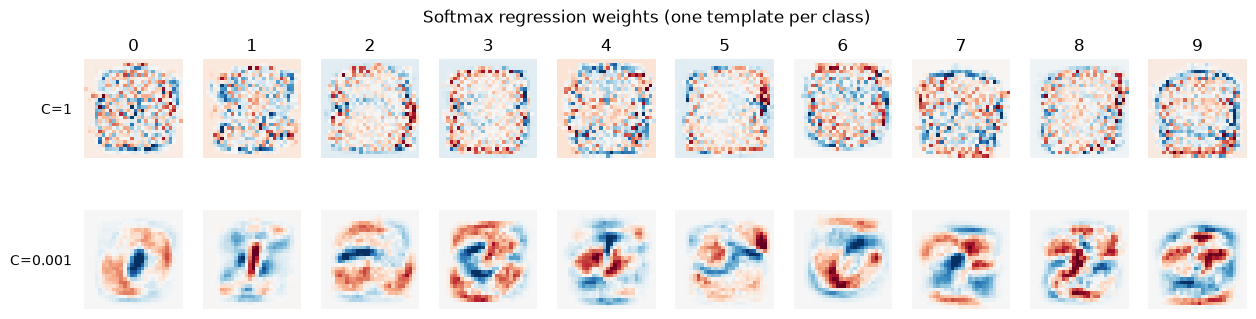

In [135]:
# softmax 邏輯回歸的權重：每一類一個 784 維的向量 → 畫回 28×28，就是這一類的「模板」
# 紅 = 正權重（這裡有墨水 → 分數加分）、藍 = 負權重（這裡有墨水 → 扣分）
# 上排：baseline（C=1）。很少有墨水的邊緣像素拿到很大、很雜亂的權重（TODO 1 (3) 的稀有像素問題），模板幾乎看不出形狀。
# 下排：只為了視覺化，另外 fit 一個正則化很強的版本（C=0.001），雜訊權重被壓掉，模板的形狀才清楚。
# 色階用每張圖 |w| 的 99 百分位數，避免少數極端值把其他像素都壓成白色。
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    softmax_lr_smooth = LogisticRegression(C=0.001, max_iter=300).fit(X_tr, y_tr)
print("C=0.001 的 val accuracy：", val_scores(softmax_lr_smooth.predict_proba(X_va))["accuracy"])

fig, axes = plt.subplots(2, 10, figsize=(15, 3.6))
for row, (model, name) in enumerate([(softmax_lr, "C=1"), (softmax_lr_smooth, "C=0.001")]):
    for k in range(10):
        w = model.coef_[k]
        lim = np.percentile(np.abs(w), 99)
        axes[row, k].imshow(w.reshape(28, 28), cmap="RdBu_r", vmin=-lim, vmax=lim)
        axes[row, k].axis("off")
        axes[0, k].set_title(str(k))
    axes[row, 0].text(-4, 14, name, ha="right", va="center")
fig.suptitle("Softmax regression weights (one template per class)")
plt.show()

### TODO 2（問答）

> **(1)** 為什麼這一章改用「固定的 validation set」而不是 5-fold CV？
>
> **(a)** accuracy 的標準誤差（standard error：如果換一批同樣大小的驗證資料，accuracy 會差多少的典型幅度）約為 $\sqrt{p(1-p)/n}$，$p$ = accuracy、$n$ = 驗證集筆數。用 validation 的 $n = 10{,}000$，算出 $p = 0.92$ 和 $p = 0.98$ 時的標準誤差。對照第一章：Breast Cancer 一個 fold 只有約 91 筆，accuracy 的最小變化單位是 1/91 ≈ 1.1%。
>
> **(b)** 假設之後有兩個模型（例如兩種 MLP 設定）在 validation 上的 accuracy 是 0.981 與 0.983，算得上「真的比較好」嗎？差距大概要多大才值得相信？
>
> **(c)** 上面 softmax 邏輯回歸 fit 一次花了多久？之後的 MLP 每個設定要訓練好幾個 epoch。用 (a)(b) 和成本兩方面說明：資料夠大時，為什麼深度學習習慣用一個固定的 validation set？它在 README 的「資料切分原則」裡扮演的是哪個角色？

這邊用固定的 validation set 是因為前面做標準化的時候就已經看到全部資訊了，做 5-fold CV 的時候會有資訊洩漏的問題。

**修正**：這不是原因。

- 全域標準化只用了兩個純量（0.1307、0.3081），是從 60,000 筆訓練資料算出來的 —— 固定的 validation set 也包含在這 60,000 筆裡，所以如果這算洩漏，固定 validation 一樣有，不會因為改用 CV 才出現。
- 兩個純量能「洩漏」的資訊極少，影響可以忽略；第一章要求 scaler 包進 `Pipeline` 是因為逐特徵標準化有 784 組參數，而且要示範正確的流程。
- 真正的理由是 (a)(b)(c)：資料夠大時，一個驗證集就夠準；而深度學習每訓練一次很貴。

**(a)** $p = 0.92$、$0.98$ 時的標準誤分別為 0.0027（0.27%）和 0.0014（0.14%）。✓

（對照：Breast Cancer 一個 fold 的最小變化單位就有 1.1%，比這裡的標準誤大 4–8 倍。）

**(b)** **補寫**（題目原本寫得不清楚，指的是之後的兩個 MLP 設定，不是表格裡的兩個 baseline）：

- 差距 $0.983 - 0.981 = 0.002$；每個 accuracy 的標準誤約 0.0013–0.0014。
- 兩個獨立估計的差，標準誤約 $\sqrt{2}\times 0.0014 \approx 0.002$ → 差距只有約 1 個標準誤，**不能算真的比較好**。
- 大約要差 2 個標準誤（≈ 0.004，約 40 張影像）以上才比較可信。
- 補充：兩個模型是在**同一組** 10,000 張影像上評估，誤差有相關性，更精確的做法是只看「兩個模型答案不同」的那些樣本（McNemar 檢定，列入待補強）。另外，第 5 節會看到換 seed 造成的波動常常比這個標準誤還大。

**(c)** 體感一秒左右，資料夠大的時候，會認為抽樣的時候應該能足夠均勻抽出各種樣本，所以固定一個 validation set 做衡量，另一方面是也不用 train 5 次，那樣的時間成本跟運算太多了。

**修正與補充**：

- 實測 fit 一次 3.0 秒；之後的 MLP 每個設定要訓練 10–20 個 epoch，第 5 節的搜尋有十幾個設定，5-fold 等於全部再乘 5。
- 「抽樣夠均勻」的方向對，精確的說法是 (a)：CV 的目的是在資料少時降低估計的變異、並讓每筆資料都當過驗證資料。$n = 10{,}000$ 時單一驗證集的標準誤只有 0.14–0.27%，CV 再平均 5 次能改善的有限，成本卻是 5 倍。
- **角色**：README「資料切分原則」中的**驗證集**——選超參數、選模型、決定 early stopping 的 epoch 都看它；它不是測試集，報告成績仍要用第 6 節只看一次的測試集。

> **(2)** 看 softmax 邏輯回歸的權重圖（下排 C=0.001 的形狀比較清楚）。
>
> **(a)** 描述「0」的模板：紅色（正權重）在哪裡、藍色（負權重）在哪裡？為什麼是這個形狀？（提示：預測「0」時，中間有墨水應該加分還是扣分？）
>
> **(b)** 線性模型對每一類只有**一張**模板，分數 = 影像和模板的內積。回去看 EDA 的樣本圖：「7」有帶橫槓和不帶橫槓的寫法、「4」有開口和封口的寫法。一張模板能同時「對準」這些寫法嗎？會發生什麼事？
>
> **(c)** MLP 的隱藏層有 256 個單元，每個單元也是一張 784 維的模板，輸出經過非線性再組合。用 (b) 說明為什麼這樣可能比「每類一張模板」更強。（3C 的實驗 1 會檢驗「非線性」是不是關鍵）

**(a)** 正權重在藍色圓圈的內部，中間有墨水應該是加分，因為 0 就是只要正中間有一個圓形墨水色足夠深就可以判別。

**補充**：位置判讀正確 —— 不論 C=1 或 C=0.001，「0」的模板都是三層：**中央藍、中間一圈紅、外圈藍**。依離影像中心的距離算平均權重：

| 離中心距離（像素） | 0–3 | 3–5 | 5–11 | 11–14 |
| --- | --- | --- | --- | --- |
| C=1 平均權重 | −0.19 | +0.01 | +0.03～+0.05 | −0.04 |
| C=0.001 平均權重 | −0.07 | −0.01 | +0.01～+0.02 | −0.01 |
| 「0」的平均墨水量 | 0.12 | 0.31 | 0.20～0.51 | 0.01 |
| 其他數字的平均墨水量 | 0.45 | 0.40 | 0.10～0.34 | 0.01 |

- **紅色環（半徑約 5–11）**：0 的筆畫經過的地方，而且其他數字在這裡的墨水比較少 → 有墨水就加分。
- **中央藍（半徑 < 3）**：「正中間有墨水」反而扣分 —— 0 的中間是空洞（墨水 0.12），1、4、7、9 等的筆畫常穿過中央（0.45）。所以加分的是「中間一圈」，不是「正中央」。
- **外圈藍（半徑約 11–14）**：MNIST 的數字已縮放到固定大小，0 的筆畫只落在半徑 5–11；墨水出現在更外圈，代表比較可能是別的數字（較寬的 2、7 的橫槓兩端等）。這裡很少有墨水，所以權重很小。
- 整體來說，模板不只是「0 的平均長相」，而是「0 有墨水**而且其他數字沒有**的地方加分、其他數字有墨水而 0 沒有的地方扣分」—— softmax 在 10 類之間比較分數，權重學到的是**區分**各類的差異。

**(b)** 線性模型很難對準這些寫法，因為取的是一個平均的概念，所以假設有些圖片有開口有些沒開口，最後模型的判別會趨於平均，這樣就很難識別，線性模型會不覺得這個東西能夠當作判別的特徵。

**補充**（方向正確，說得更精確一點）：

- 分數 = $\sum_j x_j w_j$，每個像素的證據**各自獨立地加總**。一張模板只能是兩種寫法的折衷：只在某一種寫法出現的筆畫（例如 7 的橫槓），權重被「另一種寫法沒有它」稀釋，變成弱證據。
- 線性模型表達不了「**或**」與「**如果…就…**」：沒辦法說「上方封口**或**開口都算 4，但封口時要再看下方像不像 9」。
- 結果是寫法偏離平均的樣本分數不夠高，一旦又跟另一類的模板重疊（封口的 4 vs 9），就容易判錯 —— 這也是 baseline 卡在約 91% 的原因之一。

**(c)** 不確定，不過非線性能表達的函數或是維度可以比線性更多，可以理解為他可以同一個類之下可以有多張樣板。

**補充**：「同一類可以有多張模板」就是重點，再加上非線性讓它們能用「或」的方式組合：

- 256 個隱藏單元各是一張模板，可以各自對準一種寫法（帶橫槓的 7、不帶橫槓的 7），也可以只對準一個局部筆畫。
- ReLU 讓隱藏單元只在「對得夠準」時才輸出（對不準就是 0），像一個偵測器；輸出層再把偵測器組合起來：「帶橫槓的 7 偵測器 **或** 不帶橫槓的 7 偵測器有反應 → 加分給 7」。
- 沒有非線性時，$xW_1W_2$ 會合成一張模板 $W_1W_2$，256 張模板又退化回每類一張 —— 3C 實驗 1 會驗證。

---
## 3. 手寫模型（NumPy）

### 前置複習：第 3 節會用到的舊知識

先把會用到的數學與程式觀念重新整理一次。每項都附一個小例子，寫 TODO 卡住時可以回來查。

#### 數學

**1. 鏈鎖律**

- 單變數：$y = f(u)$、$u = g(x)$ → $\dfrac{dy}{dx} = \dfrac{dy}{du}\cdot\dfrac{du}{dx}$。例：$y = (3x)^2$，$u = 3x$ → $\dfrac{dy}{dx} = 2u \cdot 3 = 18x$。
- **多變數**：如果 $L$ 透過好幾個中間變數 $u_1, \dots, u_m$ 依賴 $x$，就把每一條路徑的貢獻**加起來**：
$$\frac{\partial L}{\partial x} = \sum_{m} \frac{\partial L}{\partial u_m}\cdot\frac{\partial u_m}{\partial x}$$
  例：$L = u_1 + u_2^2$，$u_1 = 2x$、$u_2 = 3x$ → $\dfrac{\partial L}{\partial x} = 1\cdot 2 + 2u_2\cdot 3 = 2 + 18x$。
  這就是 3A「同一個參數被用了好幾次，梯度就相加」的來源。

**2. 常用導數**

| 函數 | 導數 | 備註 |
| --- | --- | --- |
| $e^x$ | $e^x$ | 導數等於自己 |
| $\log x$ | $1/x$ | 不是 $\log x$ |
| $\sigma(x) = \dfrac{1}{1+e^{-x}}$ | $\sigma(x)\,(1-\sigma(x))$ | 只用到輸出 |
| $\tanh x$ | $1 - \tanh^2 x$ | 只用到輸出 |
| $\text{ReLU}(x) = \max(0, x)$ | $x > 0$ 時 1、$x < 0$ 時 0 | $x = 0$ 取 0（約定） |

**3. 矩陣乘法與 shape**

- $(n, d) \times (d, m) = (n, m)$：中間的維度要相等，相乘後消失。
- 單一元素：$(AB)_{ik} = \sum_j A_{ij}B_{jk}$ —— 被加總的下標 $j$ 就是「消失的那個維度」。
- 轉置：$(A^\top)_{ij} = A_{ji}$。由此：$(A^\top B)_{jk} = \sum_i A_{ij}B_{ik}$（加總兩者的**第一個**下標）、$(AB^\top)_{ij} = \sum_k A_{ik}B_{jk}$（加總兩者的**第二個**下標）。
- 例：$A = \begin{pmatrix}1 & 2\\ 3 & 4\end{pmatrix}$、$B = \begin{pmatrix}5\\ 6\end{pmatrix}$ → $AB = \begin{pmatrix}1\cdot5 + 2\cdot6\\ 3\cdot5 + 4\cdot6\end{pmatrix} = \begin{pmatrix}17\\ 39\end{pmatrix}$。

**4. softmax 與交叉熵**（第一章第三節的 softmax 多分類）

- softmax：把一列分數 $z_1, \dots, z_K$ 變成機率 $p_k = e^{z_k}/\sum_c e^{z_c}$（每個 $p_k > 0$、總和 1）。
- 交叉熵：一筆樣本的 loss 是「正確類別的機率」取 $-\log$：$\ell = -\log p_y$。猜對又有把握（$p_y \to 1$）→ $\ell \to 0$；有把握地猜錯（$p_y \to 0$）→ $\ell \to \infty$。
- 二元時（$K = 2$），softmax 就是 sigmoid，梯度是第一章的 $\sigma(z) - y$。

**5. 期望值與變異數**（3C 實驗 2、TODO 10 會用到）

- $E[X]$：平均值；$\text{Var}(X) = E[(X - E[X])^2]$：離平均多遠的平方的平均；標準差 = $\sqrt{\text{Var}}$。
- $\text{Var}(aX) = a^2\,\text{Var}(X)$；**獨立**的隨機變數相加，變異數也相加：$\text{Var}(X_1 + \cdots + X_m) = \text{Var}(X_1) + \cdots + \text{Var}(X_m)$。
- $h$ 與 $W$ 獨立、$E[W] = 0$ 時：$\text{Var}(hW) = E[h^2]\,\text{Var}(W)$。
- 例：$z = \sum_{j=1}^{256} h_j W_j$，每項的變異數都是 $E[h^2]\,\text{Var}(W)$ → $\text{Var}(z) = 256\cdot E[h^2]\,\text{Var}(W)$。

#### 程式

**6. class 與 `self`：屬性存在哪個物件上**

```python
class Linear:
    def __init__(self):
        self.params = {"W": ..., "b": ...}   # 存在「這一個 Linear 物件」身上

class MLP:
    def step(self):                       # 這裡的 self 是 MLP
        for linear in self.linears_:      # linear 是其中一層（Linear 物件）
            linear.params["W"]            # ✓ 參數在層身上
            self.params                   # ✗ MLP 沒有 params → AttributeError
```

`self` 永遠指「呼叫這個方法的那個物件」：在 `Linear` 的方法裡是那一層，在 `MLP` 的方法裡是整個網路。

**7. 走訪串列與 dict**

```python
d = {"W": arr1, "b": arr2}
for k in d:              # k 依序是 "W"、"b"（key，字串）
    d[k]                 # 用 key 取出陣列
for k, v in d.items():   # 同時拿 key 與值

layers = [L1, R, L2]
reversed(layers)         # 倒序的迭代器，不修改 layers   ✓
layers[::-1]             # 倒序的新串列，不修改 layers   ✓
layers.reverse()         # 就地把 layers 本身反轉，回傳 None   ✗（不能拿來 for）
```

**8. 就地修改 vs 重新賦值**

```python
d = {"W": np.array([1.0, 2.0])}
w = d["W"]
w -= 0.5         # 就地修改：d["W"] 也變成 [0.5, 1.5]（w 和 d["W"] 是同一個陣列）
w = w - 0.5      # 重新賦值：w 指向一個新陣列，d["W"] 不變
d["W"] -= 0.5    # ✓ 直接改 dict 裡的那個陣列
```

**9. NumPy：axis、broadcasting、布林遮罩、成對索引**

```python
A = np.array([[1, 2],
              [3, 4],
              [5, 6]])          # shape (3, 2)
A.sum(axis=0)    # [9, 12]   消掉 axis 0（列方向）→ 每一欄加總，shape (2,)
A.sum(axis=1)    # [3, 7, 11] 消掉 axis 1 → 每一列加總，shape (3,)

A + np.array([10, 20])          # broadcasting：(3, 2) + (2,) → 每一列都加上 [10, 20]
                                # → 這就是 X @ W + b 裡 b 的加法

mask = A > 2                    # 布林陣列 [[F, F], [T, T], [T, T]]
A * mask                        # True 當 1、False 當 0 → [[0, 0], [3, 4], [5, 6]]

y = np.array([1, 0, 1])
A[np.arange(3), y]              # 成對取 (0,1)、(1,0)、(2,1) → [2, 3, 6]（每列取一格）
```

### 3A. 每一層的 forward 與 backward

一個 MLP 就是一串函數的合成：

$$x \xrightarrow{\text{Linear}} z_1 \xrightarrow{\text{ReLU}} h_1 \xrightarrow{\text{Linear}} z_2 \xrightarrow{\text{softmax + CE}} L$$

#### 符號表（第 3 節通用）

| 符號 | 意義 | shape | 程式裡 |
| --- | --- | --- | --- |
| $n$ | 一個 batch 的樣本數 | 純量 | `len(X)` |
| $d_{\text{in}}$、$d_{\text{out}}$ | 一個 Linear 層的輸入、輸出維度（也叫 fan_in、fan_out） | 純量 | `W.shape` |
| $K$ | 類別數（MNIST 是 10） | 純量 | `n_classes_` |
| $X$ | 一層的**輸入**（第一層就是攤平的影像） | $(n, d_{\text{in}})$ | `X`；forward 存成 `self.X` |
| $W$、$b$ | Linear 的**參數** | $(d_{\text{in}}, d_{\text{out}})$、$(d_{\text{out}},)$ | `self.params["W"]`、`self.params["b"]` |
| out | 一層的**輸出** | $(n, d_{\text{out}})$ | `forward` 的回傳值 |
| $z_l$、$h_l$ | 第 $l$ 個 Linear 的輸出（激活前）、經過激活函數之後 | $(n, d_l)$ | 各層 `forward` 的回傳值 |
| $f$、$f'$ | 激活函數（ReLU、$\sigma$、tanh）與它的導數，都是逐元素作用 | 同輸入 | `ReLU`、`Sigmoid`、`Tanh` |
| $Z$ | 最後一個 Linear 的輸出（logits，還沒 softmax 的分數） | $(n, K)$ | `Z` |
| $P$ | softmax 後的類別機率，每列總和 1 | $(n, K)$ | `self.P` |
| $y$、$Y$ | 整數標籤、one-hot 標籤（$Y_{ik} = 1$ 若 $y_i = k$） | $(n,)$、$(n, K)$ | `y`；$Y$ 不實際建立 |
| $L$ | batch 的平均交叉熵（＋weight decay 項） | 純量 | `loss` |
| $\partial L/\partial\,\text{out}$（也寫 $\delta$） | **上游梯度**：loss 對「這一層輸出」的梯度，由後一層傳回來 | 同 out | `dout` |
| $\partial L/\partial W$、$\partial L/\partial b$ | **參數的梯度**（backward 算出的結果） | 同 $W$、$b$ | `self.grads["W"]`、`self.grads["b"]` |
| $\partial L/\partial X$ | 傳給**前一層**的梯度（前一層的 dout） | 同 $X$ | `dX`（`backward` 的回傳值） |
| $\odot$ | 逐元素相乘（不是矩陣乘法） | — | `*` |
| $i$、$j$、$k$ | 下標：$i$ = 第幾筆樣本、$j$ = 輸入維度、$k$ = 輸出維度 | — | axis 0 = 樣本 |

**變數的四種角色**（寫 backward 時最容易混淆）：

- **輸入／cache**：forward 時存下來、backward 要用的東西（`self.X`、`self.mask`、`self.out`）。
- **參數**：要學的東西（`params["W"]`、`params["b"]`）。公式裡出現 $W$，指的是它。
- **參數的梯度**：backward 的**結果**（`grads["W"]`），只拿來更新參數，不拿來算別層的梯度。
- **上游梯度**：後一層傳來的 `dout`；backward 要把它乘上局部導數，傳給前一層。

反向傳播（backpropagation）= 對這串合成函數用**鏈鎖律**，從 $L$ 往回一層一層算梯度。關鍵是把它拆成**每一層只管自己**：

| 方法 | 輸入 | 輸出 | 要做的事 |
| --- | --- | --- | --- |
| `forward(X)` | 這一層的輸入 | 這一層的輸出 `out` | 算輸出，並把 backward 會用到的東西**存起來**（cache） |
| `backward(dout)` | $\partial L/\partial\,\text{out}$（上游梯度，跟 `out` 同 shape） | $\partial L/\partial X$（傳給前一層，跟 `X` 同 shape） | 用鏈鎖律算出 $\partial L/\partial X$；有參數的層順便算 $\partial L/\partial W$、$\partial L/\partial b$ 存到 `grads` |

**shape 慣例**（跟 PyTorch 一樣，一列一筆樣本）：`X` 是 $(n, d_{\text{in}})$，`W` 是 $(d_{\text{in}}, d_{\text{out}})$，`b` 是 $(d_{\text{out}},)$，`out = X @ W + b` 是 $(n, d_{\text{out}})$。

**推導小技巧**：

1. **梯度的 shape 一定跟變數本身一樣**（$\partial L/\partial W$ 是 $(d_{\text{in}}, d_{\text{out}})$）。矩陣乘法只有一種擺法能湊出對的 shape，常常可以直接「湊」出公式，再用單一元素驗證。
2. **先寫單一元素**：$\text{out}_{ik} = \sum_j X_{ij}W_{jk} + b_k$ → $\dfrac{\partial\,\text{out}_{ik}}{\partial W_{jk}} = X_{ij}$。
3. **同一個參數被用了好幾次，梯度就相加**：$W$ 被 batch 裡的每一筆樣本都用到，所以 $\partial L/\partial W_{jk} = \sum_i X_{ij}\cdot\partial L/\partial\,\text{out}_{ik}$。$b$ 也一樣。
4. **逐元素的激活函數**（ReLU、Sigmoid、Tanh）：$h = f(z)$ → $\partial L/\partial z = \partial L/\partial h \odot f'(z)$（$\odot$ 是逐元素相乘，不是矩陣乘法）。

**權重初始化**：訓練開始前，每個 `Linear` 的 `W` 要先有數值，梯度下降才能從那裡開始更新。`Linear` 從平均 0 的常態分布抽亂數當初始權重，`init_std` 決定這個分布的**標準差**：

- **一定要隨機**：如果所有權重都一樣，每個隱藏單元算出來的東西、收到的梯度都一樣，永遠一樣 —— 256 個單元等於 1 個（3C 實驗 3）。
- **大小要剛好**：一層的輸出 $z_k = \sum_j x_j W_{jk}$ 是 fan_in 個項相加。標準差太大，訊號每過一層就被放大；太小，每過一層就縮小，疊幾層之後不是爆炸就是趨近 0。所以標準差要隨輸入數量 fan_in 調整，常用的是 **He**（給 ReLU）與 **Xavier**（給 Sigmoid／Tanh）。
- 這一節先直接使用；公式為什麼長這樣，3C 實驗 2（TODO 10）會從實驗結果推導。

#### 最小例子：TODO 3（Linear 的 backward）

$n = 2$、$d_\text{in} = 3$、$d_\text{out} = 4$，三個 shape 都不一樣，寫錯時 shape 一定對不上。

| 變數 | 角色 | shape | 內容 |
| --- | --- | --- | --- |
| `X_mini` | forward 的輸入（cache） | $(2, 3)$ | $\begin{pmatrix}1&2&3\\4&5&6\end{pmatrix}$ |
| `W_mini` | 參數 | $(3, 4)$ | 前三欄是單位矩陣、第四欄全是 1 |
| `dout_mini` | 上游梯度 $\partial L/\partial\,\text{out}$ | $(2, 4)$ | $\begin{pmatrix}1&0&0&10\\0&1&0&20\end{pmatrix}$ |

1. **正確答案**：照下標公式用迴圈算 $\partial L/\partial W_{jk} = \sum_i X_{ij}\,\text{dout}_{ik}$、$\partial L/\partial b_k = \sum_i \text{dout}_{ik}$、$\partial L/\partial X_{ij} = \sum_k \text{dout}_{ik}\,W_{jk}$；再用中央差分驗證其中一格。
2. **積木**：`X.T`、`dout`、`W.T` 的 shape —— 每個梯度都只有一種擺法湊得出正確的 shape。
3. **留給你**：寫成三行矩陣運算。

In [ ]:
# 最小例子：TODO 3（Linear 的 backward）
import numpy as np

X_mini = np.array([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]])  # (n=2, d_in=3)
W_mini = np.array([[1.0, 0.0, 0.0, 1.0], [0.0, 1.0, 0.0, 1.0], [0.0, 0.0, 1.0, 1.0]])  # (3, 4)
b_mini = np.zeros(4)
dout_mini = np.array([[1.0, 0.0, 0.0, 10.0], [0.0, 1.0, 0.0, 20.0]])  # (2, 4)
n_mini, din_mini = X_mini.shape
dout_dim_mini = W_mini.shape[1]

# ---- 1. 正確答案：照下標公式寫迴圈 ----
dW_loop = np.zeros((din_mini, dout_dim_mini))
for j_mini in range(din_mini):
    for k_mini in range(dout_dim_mini):
        dW_loop[j_mini, k_mini] = sum(X_mini[i_mini, j_mini] * dout_mini[i_mini, k_mini] for i_mini in range(n_mini))  # 加總 i
db_loop = np.array([sum(dout_mini[i_mini, k_mini] for i_mini in range(n_mini)) for k_mini in range(dout_dim_mini)])  # 加總 i
dX_loop = np.zeros((n_mini, din_mini))
for i_mini in range(n_mini):
    for j_mini in range(din_mini):
        dX_loop[i_mini, j_mini] = sum(dout_mini[i_mini, k_mini] * W_mini[j_mini, k_mini] for k_mini in range(dout_dim_mini))  # 加總 k
print("正確答案 dW (3, 4)：\n", dW_loop)
print("正確答案 db (4,)  ：", db_loop)
print("正確答案 dX (2, 3)：\n", dX_loop)

# 數值驗證一格：f(W) = Σ (X @ W + b) ⊙ dout，則 ∂f/∂W[0, 3] 應等於 dW_loop[0, 3]
eps_mini = 1e-6
Wp_mini, Wm_mini = W_mini.copy(), W_mini.copy()
Wp_mini[0, 3] += eps_mini
Wm_mini[0, 3] -= eps_mini
f_mini = lambda W: np.sum((X_mini @ W + b_mini) * dout_mini)
print(f"中央差分 ∂f/∂W[0, 3] = {(f_mini(Wp_mini) - f_mini(Wm_mini)) / (2 * eps_mini):.6f}，迴圈 = {dW_loop[0, 3]}")

# ---- 2. 積木：只看 shape ----
print("\nX.T  ", X_mini.T.shape, "  dout", dout_mini.shape, "  W.T", W_mini.T.shape)
print("目標：dW", W_mini.shape, "、db", b_mini.shape, "、dX", X_mini.shape)

# ---- 3. 留給你 ----
# 問題：哪兩個矩陣相乘是 (3, 4)？哪兩個是 (2, 3)？db 要沿哪個 axis 加總（b 被每一筆樣本都用到）？
# 寫完 TODO、執行過下一格之後，取消下面的註解來對照（三個都應為 True）：
# lin_mini = Linear(3, 4); lin_mini.params["W"] = W_mini.copy()
# lin_mini.forward(X_mini); dX_m = lin_mini.backward(dout_mini)
# print(np.allclose(lin_mini.grads["W"], dW_loop), np.allclose(lin_mini.grads["b"], db_loop), np.allclose(dX_m, dX_loop))

#### 最小例子：TODO 4a–4c（激活函數的 backward）

一筆樣本、3 個元素：$X = (-1, 0, 2)$，上游梯度 $\text{dout} = (10, 20, 30)$。逐元素的激活函數 $h = f(x)$ 的 backward 是 $\partial L/\partial x = \text{dout} \odot f'(x)$。

1. **正確答案**：不用導數公式，直接對每個元素做中央差分 $f'(x) \approx \dfrac{f(x + \varepsilon) - f(x - \varepsilon)}{2\varepsilon}$，再乘上 dout。
2. **積木**：forward 存下的 `mask`、`out`（ReLU、Sigmoid、Tanh 各自存了什麼）。
3. **留給你**：每個 backward 一行，只用 `dout` 和 forward 存的東西。

注意 ReLU 在 $x = 0$ 不可微：中央差分會得到 $0.5$（左右導數的平均），但我們（和 PyTorch）約定取 $0$。

In [ ]:
# 最小例子：TODO 4a–4c（激活函數的 backward）
import numpy as np

X_mini = np.array([[-1.0, 0.0, 2.0]])  # (n=1, d=3)
dout_mini = np.array([[10.0, 20.0, 30.0]])
fs_mini = {
    "relu": lambda x: np.maximum(0.0, x),
    "sigmoid": lambda x: 1 / (1 + np.exp(-x)),
    "tanh": np.tanh,
}

# ---- 1. 正確答案：逐元素中央差分 × dout ----
eps_mini = 1e-6
for name_mini, f_mini in fs_mini.items():
    dX_loop = [dout_mini[0, j] * (f_mini(X_mini[0, j] + eps_mini) - f_mini(X_mini[0, j] - eps_mini)) / (2 * eps_mini) for j in range(3)]
    print(f"中央差分 × dout {name_mini:<7}：", np.round(dX_loop, 4))
print("正確答案：sigmoid、tanh 就是上面兩列；ReLU 在 x = 0 不可微，中央差分得到 20 × 0.5 = 10，")
print("          但約定導數取 0 → ReLU 的正確答案是 [0, 0, 30]")

# ---- 2. 積木：forward 存了什麼 ----
mask_mini = X_mini > 0
sig_out_mini = 1 / (1 + np.exp(-X_mini))
tanh_out_mini = np.tanh(X_mini)
print("\nReLU    self.mask = X > 0 ：", mask_mini, mask_mini.dtype, "← 布林乘上數字時 True/False 變成 1/0")
print("Sigmoid self.out = σ(X)   ：", sig_out_mini.round(4))
print("Tanh    self.out = tanh(X)：", tanh_out_mini.round(4))
print("dout                      ：", dout_mini, dout_mini.shape, "← 跟 X、out 同 shape，逐元素相乘即可")

# ---- 3. 留給你 ----
# 問題：三個 backward 各一行：dout 乘上什麼？（σ′ = σ(1−σ)、tanh′ = 1 − tanh²，都只要用 forward 存的 out）
#       常見錯誤：判斷正負的是 forward 的輸入 X（mask），不是 dout。
# 寫完 TODO、執行過下一格之後，取消下面的註解來對照：
# for L in (ReLU(), Sigmoid(), Tanh()):
#     L.forward(X_mini); print(type(L).__name__, L.backward(dout_mini).round(4))

#### 最小例子：TODO 5（softmax + 交叉熵的 backward）

$n = 2$、$K = 3$：$Z = \begin{pmatrix}1&2&3\\0&0&0\end{pmatrix}$、$y = (2, 0)$。

1. **正確答案**：逐元素算 $P_{ik}$，再用 $\dfrac{\partial L}{\partial Z_{ik}} = \dfrac{P_{ik} - Y_{ik}}{n}$（$Y_{ik} = 1$ 若 $k = y_i$）。
2. **積木**：fancy indexing `P[np.arange(n), y]` 取出「每列正確類別那一格」，以及兩個常見錯誤：`P[:, y]`、忘了 `copy()`。
3. **留給你**：減 1、除以 $n$。

In [ ]:
# 最小例子：TODO 5（softmax + 交叉熵的 backward）
import math
import numpy as np

Z_mini = np.array([[1.0, 2.0, 3.0], [0.0, 0.0, 0.0]])  # (n=2, K=3)
y_mini = np.array([2, 0])
n_mini, K_mini = Z_mini.shape

# ---- 1. 正確答案：逐元素 ----
dZ_loop = np.zeros((n_mini, K_mini))
for i_mini in range(n_mini):
    denom_mini = sum(math.exp(z) for z in Z_mini[i_mini])
    for k_mini in range(K_mini):
        P_ik_mini = math.exp(Z_mini[i_mini, k_mini]) / denom_mini
        dZ_loop[i_mini, k_mini] = (P_ik_mini - (1.0 if k_mini == y_mini[i_mini] else 0.0)) / n_mini
print("正確答案 dZ：\n", dZ_loop.round(4))

# ---- 2. 積木 ----
P_mini = np.exp(Z_mini) / np.exp(Z_mini).sum(axis=1, keepdims=True)
print("\nP                      ", P_mini.shape, "\n", P_mini.round(4))
rows_mini = np.arange(n_mini)
print("np.arange(n)           ", rows_mini)
print("P[np.arange(n), y]     ", P_mini[rows_mini, y_mini].shape, P_mini[rows_mini, y_mini].round(4), "← 第 i 列的第 y_i 格：(0, 2)、(1, 0)")
print("錯誤示範 P[:, y]       ", P_mini[:, y_mini].shape, "← 每一列都取第 2、0 欄，變成 2×2")
Q_mini = P_mini  # 沒有 copy
print("Q = P 與 P 共用記憶體？", np.shares_memory(Q_mini, P_mini), "← 直接改 Q 會把 forward 存的 self.P 也改掉")

# ---- 3. 留給你 ----
# 問題：在 P 的「複本」上，把哪些位置減 1？最後除以什麼？結果應等於 dZ_loop。
# 寫完 TODO、執行過下一格之後，取消下面的註解來對照：
# ce_mini = SoftmaxCrossEntropy(); ce_mini.forward(Z_mini, y_mini); print(ce_mini.backward().round(4))

In [136]:
from typing import Literal, Self
from numpy.typing import ArrayLike
from scipy.special import logsumexp

InitName = Literal["he", "xavier", "constant"]


def init_std(init: InitName | float, fan_in: int, fan_out: int) -> float:
    """權重初始化的標準差。fan_in = 輸入維度 d_in、fan_out = 輸出維度 d_out。

    - "he"（Kaiming）：給 ReLU 用
    - "xavier"（Glorot）：給 Sigmoid／Tanh 用
    - float：直接當成標準差（例如 0.01）
    """
    if isinstance(init, (int, float)):
        return float(init)
    # He：Var(W) = 2 / fan_in；Xavier：Var(W) = 2 / (fan_in + fan_out)
    # 為什麼是這兩個數字，3C 實驗 2（TODO 10）會從實驗結果推導
    if init == "he":
        return np.sqrt(2 / fan_in)
    if init == "xavier":
        return np.sqrt(2 / (fan_in + fan_out))
    raise ValueError(f"init_std 不處理 {init!r}（constant 由 Linear 自己處理）")


class Layer:
    """所有層的共同介面。沒有參數的層，params／grads 是空 dict。"""

    def __init__(self) -> None:
        self.params: dict[str, np.ndarray] = {}
        self.grads: dict[str, np.ndarray] = {}

    def forward(self, X: np.ndarray) -> np.ndarray:
        raise NotImplementedError

    def backward(self, dout: np.ndarray) -> np.ndarray:
        raise NotImplementedError


class Linear(Layer):
    """全連接層：out = X @ W + b。"""

    def __init__(
        self,
        d_in: int,
        d_out: int,
        init: InitName | float = "he",
        rng: np.random.Generator | None = None,
        dtype: type = np.float64,
    ) -> None:
        super().__init__()
        rng = np.random.default_rng() if rng is None else rng
        if init == "constant":  # 所有權重同一個值（3C 實驗 3 用）
            W = np.full((d_in, d_out), 0.01)
        else:
            W = rng.normal(0.0, init_std(init, d_in, d_out), size=(d_in, d_out))
        self.params = {"W": W.astype(dtype), "b": np.zeros(d_out, dtype=dtype)}
        self.grads = {k: np.zeros_like(v) for k, v in self.params.items()}

    def forward(self, X: np.ndarray) -> np.ndarray:
        """X (n, d_in) → (n, d_out)。存下 X 給 backward 用。"""
        self.X = X
        return X @ self.params["W"] + self.params["b"]

    def backward(self, dout: np.ndarray) -> np.ndarray:
        """dout (n, d_out) = ∂L/∂out。把 ∂L/∂W、∂L/∂b 存進 self.grads，回傳 ∂L/∂X (n, d_in)。"""
        # TODO 3（程式）：三行，都不需要 for 迴圈
        #   grads["W"]：shape (d_in, d_out)  ← 用 self.X 和 dout
        #   grads["b"]：shape (d_out,)       ← b 被 batch 裡每一筆樣本都用到了
        #   dX        ：shape (n, d_in)      ← 用 dout 和 W
        self.grads["W"] = self.X.T @ dout
        self.grads["b"] = dout.sum(axis=0)
        dX = dout @ self.params["W"].T
        return dX


class ReLU(Layer):
    """out = max(0, X)。"""

    def forward(self, X: np.ndarray) -> np.ndarray:
        self.mask = X > 0
        self.out = X * self.mask
        return self.out

    def backward(self, dout: np.ndarray) -> np.ndarray:
        # TODO 4a（程式）：一行。forward 的輸入 X ≤ 0 的位置梯度為 0，X > 0 的位置原封不動傳回去
        #   - 判斷的是 forward 的輸入 X（已存成 self.mask = X > 0），不是 dout
        #   - X 剛好 = 0 時導數取 0（不可微點的約定，跟 PyTorch 一樣）
        return dout * self.mask


class Sigmoid(Layer):
    """out = σ(X) = 1 / (1 + e⁻ˣ)，用第一章第三節的數值穩定寫法。"""

    def forward(self, X: np.ndarray) -> np.ndarray:
        e = np.exp(-np.abs(X))
        self.out = np.where(X >= 0, 1 / (1 + e), e / (1 + e))
        return self.out

    def backward(self, dout: np.ndarray) -> np.ndarray:
        # TODO 4b（程式）：一行。σ′(x) = σ(x)(1 − σ(x))，用 forward 存下來的 self.out
        return dout * self.out * (1 - self.out)


class Tanh(Layer):
    """out = tanh(X)。"""

    def forward(self, X: np.ndarray) -> np.ndarray:
        self.out = np.tanh(X)
        return self.out

    def backward(self, dout: np.ndarray) -> np.ndarray:
        # TODO 4c（程式）：一行。tanh′(x) = 1 − tanh²(x)
        return dout * (1 - self.out**2)


class Identity(Layer):
    """不做任何事的「激活函數」（3C 實驗 1：拿掉非線性會怎樣）。"""

    def forward(self, X: np.ndarray) -> np.ndarray:
        self.out = X
        return X

    def backward(self, dout: np.ndarray) -> np.ndarray:
        return dout


class SoftmaxCrossEntropy:
    """softmax + 平均交叉熵，合成一個節點（不是 Layer：它的輸入多了標籤 y，輸出是純量）。"""

    def forward(self, Z: np.ndarray, y: np.ndarray) -> float:
        """Z (n, K) 是 logits、y (n,) 是 0..K−1 的整數標籤。回傳平均交叉熵（純量）。"""
        log_P = Z - logsumexp(
            Z, axis=1, keepdims=True
        )  # log-softmax，第一章第三節的穩定寫法
        self.P = np.exp(log_P)  # (n, K)，每列總和 1
        self.y = y
        return float(-log_P[np.arange(len(y)), y].mean())

    def backward(self) -> np.ndarray:
        """回傳 ∂L/∂Z，shape (n, K)。"""
        n = len(self.y)
        # TODO 5（程式）：∂L/∂Z = (P − Y) / n，Y 是 one-hot
        #   - 不要真的建 one-hot 矩陣：複製一份 P，再把每一列「正確類別」那一格減 1
        #   - 為什麼要除以 n？（L 是「平均」交叉熵）
        P_copy = self.P.copy()
        P_copy[np.arange(n), self.y] -= 1
        dZ = P_copy / n
        return dZ

#### 梯度檢查：每一層單獨檢查

方法跟第一章第三節一樣用中央差分（把某個數 $x$ 前後各動一點點，$\dfrac{f(x+\varepsilon) - f(x-\varepsilon)}{2\varepsilon}$ 就是 $\partial f/\partial x$ 的近似值，再跟解析梯度比較相對誤差），但這裡要檢查的是「一層」：給一個隨機的上游梯度 $G$，定義純量函數 $f(X) = \sum (\text{layer.forward}(X) \odot G)$，
則 $\partial f/\partial X$ 就是 `layer.backward(G)` 應該回傳的東西。（數值檢查一律用 float64。）

In [137]:
def numerical_grad(f, x: np.ndarray, eps: float = 1e-6) -> np.ndarray:
    """中央差分：回傳與 x 同 shape 的 ∂f/∂x。會就地修改 x 再改回來。"""
    grad = np.zeros_like(x)
    it = np.nditer(x, flags=["multi_index"])
    for _ in it:
        i = it.multi_index
        old = x[i]
        x[i] = old + eps
        f_plus = f()
        x[i] = old - eps
        f_minus = f()
        x[i] = old
        grad[i] = (f_plus - f_minus) / (2 * eps)
    return grad


def rel_error(a: np.ndarray, b: np.ndarray) -> float:
    """相對誤差 ‖a − b‖ / ‖a + b‖（兩者都是 0 時回傳 0）。"""
    denom = np.linalg.norm(a + b)
    return 0.0 if denom == 0 else float(np.linalg.norm(a - b) / denom)


rng = np.random.default_rng(0)
X_chk = rng.normal(size=(5, 4))
G_chk = rng.normal(size=(5, 3))

lin = Linear(4, 3, init="xavier", rng=rng)
lin.params["b"] = rng.normal(size=3)  # 讓 b 不是 0，檢查更有效
f = lambda: np.sum(lin.forward(X_chk) * G_chk)
lin.forward(X_chk)
dX = lin.backward(G_chk)
print(f"✅ Linear dX：{rel_error(dX, numerical_grad(f, X_chk)):.1e}", end="  ")
print(
    f"dW：{rel_error(lin.grads['W'], numerical_grad(f, lin.params['W'])):.1e}", end="  "
)
print(
    f"db：{rel_error(lin.grads['b'], numerical_grad(f, lin.params['b'])):.1e}  （都應 < 1e-8）"
)

for layer in [ReLU(), Sigmoid(), Tanh()]:
    G = rng.normal(size=(5, 4))
    f = lambda: np.sum(layer.forward(X_chk) * G)
    layer.forward(X_chk)
    print(
        f"✅ {type(layer).__name__:8s} dX：{rel_error(layer.backward(G), numerical_grad(f, X_chk)):.1e}（應 < 1e-8）"
    )

ce = SoftmaxCrossEntropy()
Z_chk, y_chk = rng.normal(size=(5, 3)), np.array([0, 2, 1, 2, 0])
f = lambda: ce.forward(Z_chk, y_chk)
ce.forward(Z_chk, y_chk)
print(
    f"✅ SoftmaxCE dZ：{rel_error(ce.backward(), numerical_grad(f, Z_chk)):.1e}（應 < 1e-8）"
)
print(
    f"✅ init_std：he(784→256) = {init_std('he', 784, 256):.4f}（應 0.0505）、"
    f"xavier(784→256) = {init_std('xavier', 784, 256):.4f}（應 0.0439）"
)

✅ Linear dX：1.7e-10  dW：1.1e-10  db：2.6e-10  （都應 < 1e-8）
✅ ReLU     dX：2.5e-11（應 < 1e-8）
✅ Sigmoid  dX：1.8e-10（應 < 1e-8）
✅ Tanh     dX：6.7e-11（應 < 1e-8）
✅ SoftmaxCE dZ：3.0e-10（應 < 1e-8）
✅ init_std：he(784→256) = 0.0505（應 0.0505）、xavier(784→256) = 0.0439（應 0.0439）


### TODO 6（問答）推導

> **(1)** Linear 的三個梯度。
>
> **(a)** 用「shape 湊公式」：`grads["W"]` 要 $(d_{\text{in}}, d_{\text{out}})$，手上有 `X` $(n, d_{\text{in}})$ 和 `dout` $(n, d_{\text{out}})$，唯一能湊出來的矩陣乘法是什麼？`dX` 呢？
>
> **(b)** 用單一元素驗證 (a)。
>
> **設定**：這個 Linear 層位在網路**中間某處**，$\text{out} = XW + b$，單一元素是 $\text{out}_{ik} = \sum_j X_{ij}W_{jk} + b_k$。它後面的所有計算（激活函數、其他層、softmax、交叉熵）合起來記作 $g$，所以 loss 是 out 的函數：
>
> $$L = g(\text{out}) \qquad \text{（} L \text{ 是純量，out 是 } (n, d_{\text{out}}) \text{ 的矩陣）}$$
>
> 這一層**看不到 $g$ 的式子**，只拿得到後面傳回來的 $\partial L/\partial\,\text{out}$（= `dout`，與 out 同 shape）。
>
> 請只用 $\partial L/\partial\,\text{out}_{ik}$、$X$、$W$ 表示下面三個梯度，寫成求和式：
>
> - $\partial L/\partial W_{jk}$，並確認它就是 (a) 的矩陣乘法的第 $(j, k)$ 個元素；
> - $\partial L/\partial b_k$；
> - $\partial L/\partial X_{ij}$，並確認它就是 (a) 的 `dX` 的第 $(i, j)$ 個元素。
>
> 提示：多變數鏈鎖律 —— $L$ 透過 out 的**每一個**元素依賴 $W_{jk}$，所以
> $$\frac{\partial L}{\partial W_{jk}} = \sum_{i}\sum_{k'} \frac{\partial L}{\partial\,\text{out}_{ik'}}\cdot\frac{\partial\,\text{out}_{ik'}}{\partial W_{jk}}$$
> 哪些 $k'$ 的 $\partial\,\text{out}_{ik'}/\partial W_{jk}$ 不是 0？（推導小技巧 2、3）
>
> **(c)** 為什麼 `grads["b"]` 是 `dout` 沿著 batch 維度**加總**，而不是平均？（提示：「平均」已經在哪裡做過了？看 TODO 5 的除以 $n$）


(a) 純看dimension去判斷一定是 $X^T \cdot d_{out}$，$dX = d_{out}\cdot X^T$

**修正**：`grads["W"]` $= X^\top \cdot \text{dout}$ 正確；但 `dX` 應該是 $\text{dout}\cdot W^\top$，不是 $\text{dout}\cdot X^\top$。

- shape 檢查：$\text{dout}\cdot X^\top$ 是 $(n, d_{\text{out}})\times(d_{\text{in}}, n)$，中間維度不相等，根本乘不起來；$\text{dout}\cdot W^\top$ 是 $(n, d_{\text{out}})\times(d_{\text{out}}, d_{\text{in}}) = (n, d_{\text{in}})$ ✓。
- 原因：$\partial\,\text{out}/\partial X$ 是**權重** $W$（輸入動一點，輸出動多少取決於權重），所以梯度傳回前一層時要乘上 $W$。
- 對稱的記法：$\text{out} = XW$ 對 $W$ 微分 → 用 $X$（`X.T @ dout`）；對 $X$ 微分 → 用 $W$（`dout @ W.T`）。

(b) 

$$
\frac{\partial L}{\partial W_{jk}} = \frac{\partial L}{\partial out} \sum_j X_{ij}
$$
$$
\frac{\partial L}{\partial b_k} = \frac{\partial L}{\partial out}
$$
$$
\frac{\partial L}{\partial X_{ij}} = \frac{\partial L}{\partial out} \sum_j W_{jk}
$$

**修正**：三個式子都把 $\partial L/\partial\,\text{out}$ 當成沒有下標的東西提到 $\sum$ 外面，加總的下標也選錯了。$\partial L/\partial\,\text{out}$ 是 $(n, d_{\text{out}})$ 的矩陣，每個元素都要帶下標 $ik$。

**$\partial L/\partial W_{jk}$**：從提示的鏈鎖律出發。$\text{out}_{ik'} = \sum_{j'} X_{ij'}W_{j'k'} + b_{k'}$ 只有在 $k' = k$ 時才含有 $W_{jk}$（係數是 $X_{ij}$），所以

$$\frac{\partial\,\text{out}_{ik'}}{\partial W_{jk}} = \begin{cases} X_{ij} & k' = k \\ 0 & k' \ne k \end{cases}$$

$\sum_{k'}$ 只剩一項，**剩下的加總是對樣本 $i$**：

$$\frac{\partial L}{\partial W_{jk}} = \sum_{i=1}^{n} \frac{\partial L}{\partial\,\text{out}_{ik}}\, X_{ij} = \big(X^\top \cdot \text{dout}\big)_{jk}$$

**$\partial L/\partial b_k$**：$\partial\,\text{out}_{ik'}/\partial b_k = 1$（$k' = k$），否則 0；$b_k$ 被每一筆樣本用到 →

$$\frac{\partial L}{\partial b_k} = \sum_{i=1}^{n} \frac{\partial L}{\partial\,\text{out}_{ik}} \quad\Longrightarrow\quad \texttt{dout.sum(axis=0)}$$

**$\partial L/\partial X_{ij}$**：$X_{ij}$ 出現在第 $i$ 列的**每一個** $\text{out}_{ik}$ 裡（係數 $W_{jk}$），其他列的 out 跟它無關 → 加總的是輸出單元 $k$：

$$\frac{\partial L}{\partial X_{ij}} = \sum_{k=1}^{d_{\text{out}}} \frac{\partial L}{\partial\,\text{out}_{ik}}\, W_{jk} = \big(\text{dout}\cdot W^\top\big)_{ij}$$

**判斷對哪個下標加總**：看「這個變數被誰用到」。$W_{jk}$、$b_k$ 被每一筆樣本 $i$ 用到 → 加總 $i$；$X_{ij}$ 被每一個輸出單元 $k$ 用到 → 加總 $k$。

(c) 在Cross Entropy那邊已經先除以 n 了，所以只要沿對應的方向加總就可以了

✓。補充：$L$ 是平均交叉熵，$1/n$ 已經在 `SoftmaxCrossEntropy.backward` 的 `dZ /= n` 裡；它沿著 backward 傳到每一層的 `dout` 都已經帶著 $1/n$。如果 `grads["b"]` 再取平均，等於除了兩次 $n$，梯度會小 $n$ 倍（等效學習率也小 $n$ 倍）。

> **(2)** 激活函數的 backward。
>
> **(a)** Sigmoid 和 Tanh 的 backward 只用到 forward 的**輸出** `self.out`，不需要輸入 $X$。這兩個函數的導數有什麼特性讓這件事成立？
>
> **(b)** ReLU 在 $x = 0$ 不可微，程式裡取導數 = 0。為什麼實務上這不是問題？（提示：浮點數的 $z$ 剛好等於 0 的機率有多大？）
>
> **(c)** Sigmoid 的導數 $\sigma(1-\sigma)$ 最大值是多少、在哪裡？Tanh 的導數最大值是多少？ReLU 呢？（先記下來，3C 實驗 2 的「梯度消失」會用到）

(a) Sigmoid、Tanh的微分表示方式剛好可以用forward後的結果表示，所以直接使用self.out就可以，這建立在兩個函數的導數可以以自身函數形式再表示

✓。精確寫法：$\sigma'(x) = \sigma(x)\,(1 - \sigma(x))$、$\tanh'(x) = 1 - \tanh^2(x)$ —— 導數只是「輸出」的函數，所以 forward 存 `self.out` 就夠，不用另外存輸入 $X$，也不用在 backward 重算 $e^{-x}$。（ReLU 也一樣只需要存 `mask = X > 0`。）

(b) ReLU本身是正值的意思，而雖然x = 0不可微，但實際上函數的轉折點上是0，實務上為了讓他可以向後傳播，直接取0也無妨

**修正**：「ReLU 本身是正值」與這題無關。真正的理由有兩個：

- **幾乎不會踩到**：$z$ 是連續的浮點數，剛好等於 0 的機率幾乎是 0，所以 $x = 0$ 那一點取什麼值，幾乎不會影響任何一次更新。
- **數學上本來就允許**：在不可微點，$[0, 1]$ 之間的任何值都是合法的「次梯度」（subgradient，凸函數在折角處所有「切線斜率」的集合）；取 0 只是一種約定（PyTorch 也取 0）。

(c) Sigmoid最大值應該是0.25，在x = 0的時候；Tanh的導數最大值為1，在x -> inf的時候，ReLU沒有上限，這取決於x在正數方向的時候數值有多大

**修正**：

| | 導數 | 最大值 | 在哪裡 | $\lvert x\rvert \to \infty$ 時 |
| --- | --- | --- | --- | --- |
| Sigmoid | $\sigma(1-\sigma)$ | **0.25** ✓ | $x = 0$ ✓ | $\to 0$（飽和） |
| Tanh | $1 - \tanh^2$ | **1** | $x = 0$（不是 $x \to \infty$） | $\to 0$（$\tanh \to \pm 1$，飽和） |
| ReLU | $x > 0$ 時 1、$x < 0$ 時 0 | **1** | 所有 $x > 0$ | 正方向一直是 1，不會飽和 |

- Tanh：$x \to \infty$ 時 $\tanh x \to 1$，導數 $1 - 1^2 = 0$，那裡是梯度**最小**的地方。
- ReLU：題目問的是**導數**，不是函數值。ReLU 的函數值沒有上限，但導數只有 0 和 1 兩種。
- 這三個數字是 3C 梯度消失的關鍵：梯度每經過一層 sigmoid 最多剩 1/4，10 層後最多剩 $0.25^{10} \approx 10^{-6}$；tanh 在 0 附近、ReLU 在正半邊都是 1，不會一層層縮小。

> **(3)** softmax + 交叉熵。
>
> **(a)** 為什麼 $\partial L/\partial Z = (P - Y)/n$ 這麼簡單？用二元的情況對照第一章第三節 TODO 5 的梯度 $\sigma(z) - y$。
>
> **(b)** 如果把 softmax 和交叉熵拆成兩個獨立的層，各自寫 backward 再用鏈鎖律串起來（$Z \to P \to \ell$）：softmax 的局部導數 $\partial P/\partial Z$ 對每一筆樣本是一個 $K\times K$ 的矩陣（Jacobian）。合在一起算省下了什麼？數值上又避開了什麼？（提示：單獨算交叉熵的 backward 需要 $1/P$）

(a) 令 $p_i = \frac{e^{y_i}}{ \sum_{i=1}^k e^{y_i}}$，則$logp_i = y_i - e^{log \sum_{i=1}^k e^{y_i}}$，可以得到平均交叉熵損失為$-\frac{1}{n}\sum_{i=1}^k p_i log(y_i) = -\frac{1}{n} (z_i - log \sum_{i=1}^k e^{z_i})$

**修正與完整推導**：原本的推導把 logits 寫成 $y_i$、又用 $i$ 同時代表樣本與類別，而且 $\log p$ 那一步多了一個 $e$。下面依符號表重寫。

**符號**（先看一筆樣本，省略樣本下標）：

- $z_1, \dots, z_K$：logits（$Z$ 的一列）
- $p_k = \dfrac{e^{z_k}}{\sum_{c=1}^{K} e^{z_c}}$：softmax 機率
- $y$：正確類別（一個整數）；$Y_k = 1$ 若 $k = y$，否則 0（one-hot）

**Step 1：一筆樣本的 loss**。交叉熵只看正確類別的機率：

$$\ell = -\sum_{k} Y_k \log p_k = -\log p_y = -\log\frac{e^{z_y}}{\sum_c e^{z_c}} = -z_y + \log\sum_{c=1}^{K} e^{z_c}$$

（用 $\log(a/b) = \log a - \log b$ 與 $\log e^{z_y} = z_y$。）

**Step 2：對任意一個 $z_k$ 偏微分，兩項分開算**。

第一項：

$$\frac{\partial(-z_y)}{\partial z_k} = \begin{cases} -1 & k = y \\ 0 & k \ne y \end{cases} = -Y_k$$

第二項：外層 $\log u$、內層 $u = \sum_c e^{z_c}$，鏈鎖律：

$$\frac{\partial}{\partial z_k}\log\sum_{c} e^{z_c} = \underbrace{\frac{1}{\sum_c e^{z_c}}}_{\frac{d}{du}\log u\,=\,\frac{1}{u}} \cdot \underbrace{e^{z_k}}_{\partial u/\partial z_k} = \frac{e^{z_k}}{\sum_c e^{z_c}} = p_k$$

（$u = e^{z_1} + \cdots + e^{z_K}$ 中只有 $e^{z_k}$ 這一項含有 $z_k$。注意 $\log u$ 的導數是 $1/u$，不是 $\log u$；「導數等於自己」的是 $e^u$。）

**Step 3：一筆樣本的梯度**：

$$\frac{\partial \ell}{\partial z_k} = p_k - Y_k$$

這是 loss 的**梯度**，不是 loss 本身（loss 是 Step 1 的 $\ell$）。

**Step 4：整個 batch**。$L = \frac{1}{n}\sum_{i=1}^{n} \ell_i$，而第 $i$ 筆的 logits $Z_{ik}$ 只出現在 $\ell_i$ 裡（其他樣本的 loss 與它無關），所以 $\sum_i$ 只剩一項，**不需要加總**，只多了平均帶來的 $1/n$：

$$\frac{\partial L}{\partial Z_{ik}} = \frac{1}{n}\,\frac{\partial \ell_i}{\partial Z_{ik}} = \frac{P_{ik} - Y_{ik}}{n} \quad\Longrightarrow\quad \frac{\partial L}{\partial Z} = \frac{P - Y}{n}\;\;(n, K)$$

這就是 TODO 5 的 `dZ`。（對照 (1)(b)：$W$ 被每一筆樣本用到 → 要 $\sum_i$；$Z_{ik}$ 只屬於第 $i$ 筆 → 不加總。）

**Step 5：二元的情況**。$K = 2$ 時令 $z = z_1 - z_0$，分子分母同除 $e^{z_0}$：

$$p_1 = \frac{e^{z_1}}{e^{z_0} + e^{z_1}} = \frac{e^{z}}{1 + e^{z}} = \frac{1}{1 + e^{-z}} = \sigma(z)$$

二元時 $Y_1 = y$（正確答案是類別 1 就是 1，否則 0），所以

$$\frac{\partial \ell}{\partial z_1} = p_1 - Y_1 = \sigma(z) - y$$

與第一章第三節 TODO 5 邏輯回歸的梯度一模一樣。

**結論（為什麼這麼簡單）**：交叉熵的 $\log$ 剛好抵消 softmax 的 $\exp$（Step 1 的 $-\log\frac{e^{z_y}}{\cdots}$ 變成 $-z_y + \log\sum$），微分後只剩「預測機率 − 正確答案」。線性回歸＋MSE 的梯度 $\hat y - y$、邏輯回歸＋交叉熵的 $\sigma(z) - y$ 都是同一個形式（背後是指數族分布配上 canonical link 的共同結構，列入待補強）。

(b) 這部分我覺得屬於工程實踐的問題，基本上就是避開各種數學上不穩定或是無意義的值。

**補充**：方向對，但不只數值穩定，還有計算量。「拆開」指的是把 softmax 和交叉熵當成兩個獨立的層，各自寫 backward 再用鏈鎖律串起來：

1. 交叉熵層：$\ell = -\log p_y$ → $\dfrac{\partial \ell}{\partial p_m} = -\dfrac{Y_m}{p_m}$（只有 $m = y$ 不為 0：$-1/p_y$）。
2. softmax 層：每個 $p_m$ 的分母都含有所有 $z_k$，局部導數是 $K \times K$ 的 Jacobian：
$$\frac{\partial p_m}{\partial z_k} = p_m(\delta_{mk} - p_k), \qquad \delta_{mk} = \begin{cases}1 & m = k\\ 0 & m \ne k\end{cases}$$
3. 串起來：$\dfrac{\partial \ell}{\partial z_k} = \sum_m \dfrac{\partial \ell}{\partial p_m}\cdot\dfrac{\partial p_m}{\partial z_k} = -\dfrac{1}{p_y}\cdot p_y(\delta_{yk} - p_k) = p_k - Y_k$ —— 答案相同。

合在一起算的好處：

- **計算量**：拆開做每筆樣本要建 $K\times K$ 的 Jacobian 再乘向量，$O(K^2)$；合在一起只要 $P - Y$，$O(K)$。MNIST 的 $K = 10$ 差別不大，但語言模型的「類別」是整個詞彙表（$K \approx 50{,}000$），$K^2 = 2.5\times 10^9$，每筆樣本都要算，實際上做不到。
- **數值穩定**：拆開做會出現 $-1/p_y$。模型對正確類別很沒把握時（例如 $p_y = 10^{-50}$），$1/p_y = 10^{50}$ 超過 float32 的上限（約 $3.4\times10^{38}$）而溢位；$p_y$ 下溢成剛好 0 時，$-1/0 = -\infty$，再乘上 Jacobian 裡的 $p_y = 0$ 得到 $\infty \times 0 = $ NaN，整個訓練就壞掉。合在一起的版本從 logits 直接算（log-softmax 用 `logsumexp`，梯度是 $P - Y$），**沒有任何除法**，永遠是有限值。（與第一章第三節的 `logaddexp` 版交叉熵是同一個想法。）

### 3B. 把層串起來：MLP 與 mini-batch SGD

有了每一層的 `forward`／`backward`，整個網路就是：

- **forward**：依序呼叫每一層的 `forward`，最後接 `SoftmaxCrossEntropy` 得到 loss。
- **backward**：從 `SoftmaxCrossEntropy.backward()` 得到 $\partial L/\partial Z$，再**倒著**呼叫每一層的 `backward`，每一層把梯度傳給前一層 —— 這就是反向傳播的全部。
- **更新**：每個 Linear 的 `W`、`b` 往負梯度方向走一步。

**mini-batch SGD**：每次只取 `batch_size` 筆算梯度、更新一次；把整個訓練集走完一輪叫一個 **epoch**（每個 epoch 開始前重新打亂順序）。
50,000 筆、batch 128 → 每個 epoch 約 391 次更新。第一章都是 full-batch（每次用全部資料），這裡每次更新便宜得多，但梯度有雜訊。

**weight decay**：loss 加上 $\frac{\lambda}{2}\sum\|W\|^2$（只罰 `W`、不罰 `b`），梯度多一項 $\lambda W$ —— 就是第一章的 L2 正則化，跟 PyTorch `SGD(weight_decay=λ)` 的定義相同。

#### 程式結構：誰身上有什麼

```
MLP（在 MLP 的方法裡，self 指它）
├── layers_  = [Linear1, ReLU, Linear2]    ← forward 依序走、backward 倒序走
├── linears_ = [Linear1, Linear2]          ← step 只走這個（只有 Linear 有參數）
└── loss_fn_ = SoftmaxCrossEntropy         ← 存 P、y，backward 回傳 ∂L/∂Z

Linear1、Linear2（在 Linear 的方法裡，self 指那一層；在 MLP 的迴圈裡叫 linear／layer）
├── params = {"W": (d_in, d_out), "b": (d_out,)}   ← 參數存在「層」身上，不在 MLP 身上
├── grads  = {"W": (d_in, d_out), "b": (d_out,)}   ← backward 算出的結果，step 用它更新 params
└── X                                               ← forward 存下的 cache

ReLU（沒有參數，params／grads 是空 dict）
└── mask、out                                       ← forward 存下的 cache
```

**一次更新的三個階段**（不重疊、不交錯）：

| 階段 | 做什麼 | 參數會變嗎 | 方法 |
| --- | --- | --- | --- |
| 1. forward | 從輸入算到 loss，每層存 cache | 不會 | `forward` ＋ `loss_fn_.forward` |
| 2. backward | 從 loss 倒著傳**梯度**；每層把自己 W、b 的梯度存進 `grads`，回傳 $\partial L/\partial X$ 給前一層 | **不會** | `backward`（TODO 7a） |
| 3. 更新 | 所有層用剛算好的 `grads` 一起更新 `params` | 這時才變 | `step`（TODO 7b） |

為什麼不能邊傳邊更新：backward 傳給前一層的梯度 $\text{dout}\cdot W^\top$ 用到了 $W$；所有梯度都必須在**同一組參數**（這次 forward 用的那組）上計算，拼起來才是 $L$ 在這一點的梯度。

#### 最小例子：TODO 7a（倒著走過每一層）

用三個「乘上常數」的假層代替 Linear、ReLU、Linear：forward 是 $x \mapsto c\,x$，backward 是 $\text{dout} \mapsto c\cdot\text{dout}$，並且會印出自己被呼叫、收到什麼。

1. **正確答案**：不用迴圈，手動依 L2 → act → L1 的順序呼叫三次 `backward`。目標：三層收到的上游梯度依序是 $1, 5, 15$，最後傳回 $30$（$= 2 \times 3 \times 5$）。
2. **積木**：`layers[::-1]`、`reversed(layers)` 與 `layers.reverse()` 的差別。
3. **留給你**：兩行的 `for` 迴圈。

In [ ]:
# 最小例子：TODO 7a（倒著走過每一層）
import numpy as np


class TimesMini:
    """假的層：forward 乘 c；backward 也乘 c（d(c·x)/dx = c），並印出收到的上游梯度。"""

    def __init__(self, name: str, c: float) -> None:
        self.name, self.c = name, c

    def forward(self, X: np.ndarray) -> np.ndarray:
        return self.c * X

    def backward(self, dout: np.ndarray) -> np.ndarray:
        print(f"  {self.name}.backward 收到 dout = {dout}，傳回 {self.c * dout}")
        self.got = dout
        return self.c * dout


layers_mini = [TimesMini("L1", 2.0), TimesMini("act", 3.0), TimesMini("L2", 5.0)]

# ---- 1. 正確答案：手動依倒序呼叫 ----
print("正確答案（手動）：")
g_mini = np.array(1.0)  # ∂L/∂(最後一層的輸出)
g_mini = layers_mini[2].backward(g_mini)
g_mini = layers_mini[1].backward(g_mini)
g_mini = layers_mini[0].backward(g_mini)
print("最後傳回 ∂L/∂x =", g_mini)

# ---- 2. 積木 ----
print("\nlayers[::-1]          ：", [l.name for l in layers_mini[::-1]], "← 新串列，原串列不變")
print("list(reversed(layers))：", [l.name for l in reversed(layers_mini)], "← 一樣不改原串列")
tmp_mini = list(layers_mini)
ret_mini = tmp_mini.reverse()
print("tmp.reverse() 回傳    ：", ret_mini, "；tmp 被就地改成", [l.name for l in tmp_mini], "← 在 MLP 裡這樣寫，下次 forward 順序就反了")

# ---- 3. 留給你 ----
# 問題：寫一個兩行的 for 迴圈，倒著走過 layers，每一圈把「手上的梯度」交給這一層、再用回傳值覆寫它。
#       印出來的順序與數字應該跟上面手動的一模一樣。
# 寫完 TODO、執行過下一格之後，取消下面的註解來對照（MLP.backward 只用到 self.layers_）：
# from types import SimpleNamespace
# MLP.backward(SimpleNamespace(layers_=layers_mini), np.array(1.0))

#### 最小例子：TODO 7b（SGD 更新：走過每一層的 dict）

兩個假的 Linear，各有 `params = {"W", "b"}` 與同樣 key 的 `grads`，$\text{lr} = 0.1$。

1. **正確答案**：逐元素寫 $p \leftarrow p - \text{lr}\cdot g$，算出更新後的值。
2. **積木**：走過 dict 拿到的是什麼；`p = p - ...`（重新賦值）與 `params[k] -= ...`（就地修改）哪一個真的改到權重。
3. **留給你**：兩層 `for` 迴圈 + 一行更新。

In [ ]:
# 最小例子：TODO 7b（SGD 更新：走過每一層的 dict）
import numpy as np
from types import SimpleNamespace


def make_linears_mini():
    """兩個假的 Linear：只有 params、grads 兩個 dict。"""
    return [
        SimpleNamespace(
            params={"W": np.array([[1.0, 2.0], [3.0, 4.0]]), "b": np.array([0.0, 0.0])},
            grads={"W": np.array([[10.0, 0.0], [0.0, 10.0]]), "b": np.array([1.0, -1.0])},
        ),
        SimpleNamespace(
            params={"W": np.array([[5.0], [6.0]]), "b": np.array([0.5])},
            grads={"W": np.array([[1.0], [2.0]]), "b": np.array([5.0])},
        ),
    ]


lr_mini = 0.1
linears_mini = make_linears_mini()

# ---- 1. 正確答案：逐元素 ----
expected_mini = []
for lin_mini in linears_mini:
    new_mini = {}
    for name_mini in ["W", "b"]:
        p_mini, g_mini = lin_mini.params[name_mini], lin_mini.grads[name_mini]
        new_mini[name_mini] = np.array([p_mini.flat[e] - lr_mini * g_mini.flat[e] for e in range(p_mini.size)]).reshape(p_mini.shape)
    expected_mini.append(new_mini)
print("正確答案（更新後）：")
for j_mini, new_mini in enumerate(expected_mini, 1):
    print(f"  Linear {j_mini}: W = {new_mini['W'].tolist()}, b = {new_mini['b'].tolist()}")

# ---- 2. 積木 ----
lin0_mini = linears_mini[0]
print("\nfor k in lin.params 拿到：", [k for k in lin0_mini.params], "← 是 key（字串），不是陣列")
print("lin.params[k] 才是陣列  ：", lin0_mini.params["b"])
p_mini = lin0_mini.params["b"]
p_mini = p_mini - lr_mini * lin0_mini.grads["b"]  # 重新賦值：p 指向一個新陣列
print("p = p − lr·g 之後，params['b'] =", lin0_mini.params["b"], "← 沒變")
lin0_mini.params["b"] -= lr_mini * lin0_mini.grads["b"]  # 就地修改 dict 裡的那個陣列
print("params['b'] −= lr·g 之後       =", lin0_mini.params["b"], "← 變了")

# ---- 3. 留給你 ----
# 問題：外層迴圈走過「每一層」，內層走過「這一層的每個 key」，一行就地更新。
#       用 make_linears_mini() 重新建一份、跑你的迴圈，結果應等於 expected_mini。
# 寫完 TODO、執行過下一格之後，取消下面的註解來對照（MLP.step 只用到 self.linears_ 和 self.lr）：
# fresh_mini = make_linears_mini()
# MLP.step(SimpleNamespace(linears_=fresh_mini, lr=lr_mini))
# print([{k: v.tolist() for k, v in l.params.items()} for l in fresh_mini])

In [138]:
Activation = Literal["relu", "sigmoid", "tanh", "identity"]
ACTIVATIONS: dict[str, type[Layer]] = {
    "relu": ReLU,
    "sigmoid": Sigmoid,
    "tanh": Tanh,
    "identity": Identity,
}


class MLP:
    """多層感知器（分類），mini-batch SGD + 選用的 weight decay。結構仿 sklearn：fit／predict／predict_proba。

    hidden=(256,) 表示 784 → 256 → 10；hidden=(128, 128) 表示兩個隱藏層。
    """

    def __init__(
        self,
        hidden: tuple[int, ...] = (256,),
        activation: Activation = "relu",
        init: InitName | float = "he",
        lr: float = 0.1,
        batch_size: int = 128,
        n_epochs: int = 10,
        weight_decay: float = 0.0,
        seed: int = 0,
        dtype: type = np.float32,
    ) -> None:
        self.hidden = hidden
        self.activation = activation
        self.init = init
        self.lr = lr
        self.batch_size = batch_size
        self.n_epochs = n_epochs
        self.weight_decay = weight_decay
        self.seed = seed
        self.dtype = dtype

    # ------------------------------------------------------------ 建立網路
    def build(self, d_in: int, n_classes: int) -> Self:
        """建立 layers_：[Linear, 激活, Linear, 激活, ..., Linear]（最後一層 Linear 輸出 logits，不接激活）。"""
        self.rng_ = np.random.default_rng(self.seed)
        sizes = [d_in, *self.hidden, n_classes]
        self.layers_: list[Layer] = []
        for i, (a, b) in enumerate(zip(sizes[:-1], sizes[1:])):
            self.layers_.append(
                Linear(a, b, init=self.init, rng=self.rng_, dtype=self.dtype)
            )
            if i < len(sizes) - 2:
                self.layers_.append(ACTIVATIONS[self.activation]())
        self.linears_ = [l for l in self.layers_ if isinstance(l, Linear)]
        self.loss_fn_ = SoftmaxCrossEntropy()
        return self

    # ------------------------------------------------------------ forward / backward
    def forward(self, X: np.ndarray) -> np.ndarray:
        """X (n, d_in) → logits (n, K)。每一層會存下 backward 需要的東西。"""
        for layer in self.layers_:
            X = layer.forward(X)
        return X

    def backward(self, dZ: np.ndarray) -> None:
        """dZ (n, K) = ∂L/∂logits。執行完後，每個 Linear 的 grads 都已填好。"""
        # TODO 7a（程式）：反向傳播本體，兩行（一個 for 迴圈）
        #   倒著走過 self.layers_，每一層的 backward 回傳值就是前一層的上游梯度
        #   - 局部導數已經在各層的 backward 裡乘過了（TODO 3、4），這裡只負責「接力」：
        #     把手上的梯度交給這一層，拿回來的結果覆寫回 dZ，交給下一圈（更前面的層）
        #   - 層與層之間傳的是梯度，不是 W、b；這裡也不更新參數（更新在 step）
        #   - 不要用 self.layers_.reverse()：它就地反轉串列（下次 forward 順序就錯了），而且回傳 None
        for layer in self.layers_[::-1]:
            dZ = layer.backward(dZ)

    def loss_and_grads(self, X: np.ndarray, y: np.ndarray) -> float:
        """一個 batch：forward → loss → backward。回傳 loss（含 weight decay 項），梯度存在各層的 grads。"""
        Z = self.forward(X)
        loss = self.loss_fn_.forward(Z, y)
        self.backward(self.loss_fn_.backward())
        if self.weight_decay > 0:
            for lin in self.linears_:
                loss += 0.5 * self.weight_decay * float(np.sum(lin.params["W"] ** 2))
                lin.grads["W"] += self.weight_decay * lin.params["W"]
        return loss

    def step(self) -> None:
        """SGD：每個 Linear 的每個參數往負梯度方向走 lr。"""
        # TODO 7b（程式）：兩層 for 迴圈 + 一行更新（就地修改 params 裡的陣列）
        #   self.linears_ 裡的每一層，params 和 grads 是同樣 key（"W"、"b"）的 dict
        #   - self 是 MLP（沒有 params）；參數在每一層身上：linear.params、linear.grads
        #   - 走過 dict 拿到的是 key（字串 "W"、"b"），要用 linear.params[k] 取出陣列
        #   - 用 -= 就地修改 dict 裡的陣列；p = p - ... 只會讓區域變數指向新陣列，權重不會變
        #   - 更新順序不影響結果：梯度都已在 backward 算好，各參數的更新彼此獨立
        for linear in self.linears_:
            for name in linear.params:
                linear.params[name] -= self.lr * linear.grads[name]

    # ------------------------------------------------------------ 訓練
    def fit(
        self,
        X: ArrayLike,
        y: ArrayLike,
        X_val: ArrayLike | None = None,
        y_val: ArrayLike | None = None,
        verbose: bool = True,
    ) -> Self:
        """mini-batch SGD 訓練 n_epochs 個 epoch。

        history_ 記錄：
        - "batch_loss"：每次更新的 batch loss（含 weight decay）
        - "train_loss"：每個 epoch 內 batch loss 的平均（「邊訓練邊算」的平均，不是 epoch 結束時的 loss）
        - "val_loss"、"val_acc"：每個 epoch 結束時在 validation 上的交叉熵與 accuracy（有給 X_val 時）
        - "grad_norm"：每個 epoch 內，各 Linear 層 ‖∂L/∂W‖ 的平均 → list of (n_linear,) 陣列
        """
        X = np.asarray(X, dtype=self.dtype)
        y = np.asarray(y)
        n = len(X)
        self.n_classes_ = int(y.max()) + 1
        self.build(X.shape[1], self.n_classes_)
        self.history_ = {
            k: []
            for k in ["batch_loss", "train_loss", "val_loss", "val_acc", "grad_norm"]
        }

        for epoch in range(self.n_epochs):
            t0 = time.perf_counter()
            perm = self.rng_.permutation(n)  # 每個 epoch 重新打亂
            losses, gnorms = [], []
            for start in range(0, n, self.batch_size):
                idx = perm[start : start + self.batch_size]
                loss = self.loss_and_grads(X[idx], y[idx])
                self.step()
                losses.append(loss)
                gnorms.append([np.linalg.norm(l.grads["W"]) for l in self.linears_])
            self.history_["batch_loss"] += losses
            self.history_["train_loss"].append(float(np.mean(losses)))
            self.history_["grad_norm"].append(np.mean(gnorms, axis=0))
            msg = f"epoch {epoch + 1:2d}  train_loss {np.mean(losses):.4f}"
            if not np.isfinite(np.mean(losses)):  # 發散就停（不再算 validation）
                if verbose:
                    print(msg + "  → 發散，停止訓練")
                break
            if X_val is not None:
                s = val_scores(self.predict_proba(X_val), np.asarray(y_val))
                self.history_["val_loss"].append(s["log_loss"])
                self.history_["val_acc"].append(s["accuracy"])
                msg += f"  val_loss {s['log_loss']:.4f}  val_acc {s['accuracy']:.4f}"
            if verbose:
                print(msg + f"  ({time.perf_counter() - t0:.1f}s)")
        return self

    # ------------------------------------------------------------ 預測
    def predict_proba(self, X: ArrayLike, batch_size: int = 10_000) -> np.ndarray:
        """X (n, d_in) → (n, K) 的類別機率。分批 forward，避免一次佔太多記憶體。"""
        X = np.asarray(X, dtype=self.dtype)
        out = []
        for s in range(0, len(X), batch_size):
            Z = self.forward(X[s : s + batch_size]).astype(np.float64)
            out.append(np.exp(Z - logsumexp(Z, axis=1, keepdims=True)))
        return np.vstack(out)

    def predict(self, X: ArrayLike) -> np.ndarray:
        """X (n, d_in) → (n,) 的類別編號。"""
        return self.predict_proba(X).argmax(axis=1)

In [139]:
# 整個網路的梯度檢查：小網路（4 → 6 → 5 → 3）、float64、含 weight decay
rng = np.random.default_rng(1)
X_small, y_small = rng.normal(size=(7, 4)), rng.integers(0, 3, size=7)

for act in ["relu", "sigmoid", "tanh"]:
    net = MLP(
        hidden=(6, 5), activation=act, init="xavier", weight_decay=0.1, dtype=np.float64
    ).build(4, 3)
    for lin in net.linears_:
        lin.params["b"] = rng.normal(size=lin.params["b"].shape)
    net.loss_and_grads(X_small, y_small)
    analytic = np.concatenate(
        [lin.grads[k].ravel() for lin in net.linears_ for k in ("W", "b")]
    )
    numeric = np.concatenate(
        [
            numerical_grad(
                lambda: net.loss_and_grads(X_small, y_small), lin.params[k]
            ).ravel()
            for lin in net.linears_
            for k in ("W", "b")
        ]
    )
    print(
        f"✅ {act:7s} 全網路梯度相對誤差：{rel_error(analytic, numeric):.1e}（應 < 1e-7）"
    )

✅ relu    全網路梯度相對誤差：4.2e-10（應 < 1e-7）
✅ sigmoid 全網路梯度相對誤差：1.1e-09（應 < 1e-7）
✅ tanh    全網路梯度相對誤差：5.9e-10（應 < 1e-7）


#### 第一個 MLP：784 → 256 → 10（ReLU、He 初始化、lr = 0.1、batch 128、10 epochs）

純 NumPy、CPU 上每個 epoch 約數秒。

epoch  1  train_loss 0.2908  val_loss 0.1775  val_acc 0.9508  (0.2s)
epoch  2  train_loss 0.1365  val_loss 0.1411  val_acc 0.9597  (0.2s)
epoch  3  train_loss 0.0984  val_loss 0.1204  val_acc 0.9658  (0.2s)
epoch  4  train_loss 0.0755  val_loss 0.1066  val_acc 0.9697  (0.2s)
epoch  5  train_loss 0.0611  val_loss 0.1052  val_acc 0.9689  (0.2s)
epoch  6  train_loss 0.0504  val_loss 0.0931  val_acc 0.9719  (0.2s)
epoch  7  train_loss 0.0418  val_loss 0.0909  val_acc 0.9742  (0.2s)
epoch  8  train_loss 0.0348  val_loss 0.0863  val_acc 0.9757  (0.2s)
epoch  9  train_loss 0.0295  val_loss 0.0821  val_acc 0.9766  (0.2s)
epoch 10  train_loss 0.0250  val_loss 0.0858  val_acc 0.9755  (0.2s)


,accuracy,log_loss
Dummy prior,0.1124,2.3012
Softmax LogReg (sklearn),0.9139,0.3207
MLP 256 ReLU (scratch),0.9755,0.0858


✅ validation accuracy 應 > 0.97（參考：約 0.975）


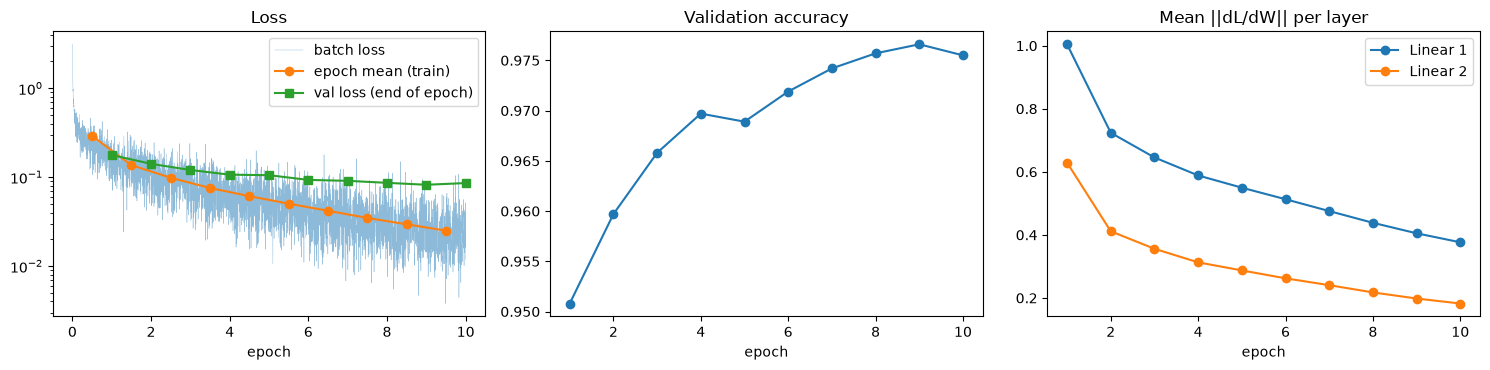

In [140]:
mlp = MLP(
    hidden=(256,),
    activation="relu",
    init="he",
    lr=0.1,
    batch_size=128,
    n_epochs=10,
    seed=0,
)
mlp.fit(X_tr, y_tr, X_va, y_va)
val_table.loc["MLP 256 ReLU (scratch)"] = val_scores(mlp.predict_proba(X_va))
display(val_table)
print("✅ validation accuracy 應 > 0.97（參考：約 0.975）")

ep = np.arange(1, len(mlp.history_["train_loss"]) + 1)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
bl = np.array(mlp.history_["batch_loss"])
steps_per_epoch = len(bl) / len(ep)
axes[0].plot(
    np.arange(len(bl)) / steps_per_epoch, bl, lw=0.3, alpha=0.5, label="batch loss"
)
axes[0].plot(ep - 0.5, mlp.history_["train_loss"], "o-", label="epoch mean (train)")
axes[0].plot(ep, mlp.history_["val_loss"], "s-", label="val loss (end of epoch)")
axes[0].set_yscale("log")
axes[0].set_xlabel("epoch")
axes[0].set_title("Loss")
axes[0].legend()
axes[1].plot(ep, mlp.history_["val_acc"], "o-")
axes[1].set_xlabel("epoch")
axes[1].set_title("Validation accuracy")
g = np.array(mlp.history_["grad_norm"])
for j in range(g.shape[1]):
    axes[2].plot(ep, g[:, j], "o-", label=f"Linear {j + 1}")
axes[2].set_xlabel("epoch")
axes[2].set_title("Mean ||dL/dW|| per layer")
axes[2].legend()
fig.tight_layout()
plt.show()

In [141]:
# forward 與 backward 各花多少時間？（同一個 batch 重複 50 次取平均）
Xb, yb = X_tr[:128], y_tr[:128]
reps = 50
t0 = time.perf_counter()
for _ in range(reps):
    Z = mlp.forward(Xb)
    mlp.loss_fn_.forward(Z, yb)
t_fwd = (time.perf_counter() - t0) / reps
t0 = time.perf_counter()
for _ in range(reps):
    mlp.backward(mlp.loss_fn_.backward())
t_bwd = (time.perf_counter() - t0) / reps
print(
    f"forward：{t_fwd * 1e3:.2f} ms   backward：{t_bwd * 1e3:.2f} ms   backward / forward = {t_bwd / t_fwd:.2f}"
)

# 每一層的矩陣乘法次數與乘加次數（multiply-add，MAC）
n_b = len(Xb)
rows = []
for j, lin in enumerate(mlp.linears_, 1):
    d_in, d_out = lin.params["W"].shape
    rows.append(
        {
            "layer": f"Linear {j} ({d_in}→{d_out})",
            "forward X@W": n_b * d_in * d_out,
            "backward X.T@dout": n_b * d_in * d_out,
            "backward dout@W.T": n_b * d_in * d_out,
        }
    )
display(pd.DataFrame(rows).set_index("layer"))

forward：0.46 ms   backward：0.33 ms   backward / forward = 0.72


,forward X@W,backward X.T@dout,backward dout@W.T
layer,,,
Linear 1 (784→256),25690112,25690112,25690112
Linear 2 (256→10),327680,327680,327680


### TODO 8（問答）

> **(1)** 看學習曲線的左圖。
>
> **(a)** 第 1 個 epoch 的 train loss（epoch 內 batch loss 的平均）和 val loss，哪個比較大？到了後面的 epoch 呢？
>
> **(b)** 第 1 個 epoch 的 train loss 是「邊訓練邊算」的平均：epoch 一開始模型還很爛，結束時已經好很多。這為什麼會讓第 1 個 epoch 的 train loss 看起來比 val loss 還高？（這不代表模型在 validation 上比較好）
>
> **(c)** batch loss（淺色線）為什麼會上下跳？跳動的幅度跟 batch size 有什麼關係？

(a) 第一個 epoch 的 train loss 比 val loss 大，到了後面 train loss 一路走低，val loss 大約卡在 1e-1 左右。

✓。精確數字：第 1 個 epoch train 0.291 > val 0.178；第 2 個 epoch 就反過來（train 0.137 < val 0.141），之後 train 一路降到 0.025，val 停在 0.08–0.09，第 10 個 epoch 還微微回升（0.082 → 0.086）。兩條線的差距逐漸拉開，是開始過擬合的訊號（第 5 節 5B 會看到訓練更久時 val loss 明顯上升）。

(b) 第一個 epoch 的時候資料才第一次看完，權重還在更新中，可能沒那麼快接近最佳解，所以看起來比 val 差。

**補充**：方向對，精確的原因是「兩個數字是在不同時間點的模型上算的」：

- **train loss（epoch 平均）** = 這個 epoch 內 391 個 batch loss 的平均。第一批 batch 是用剛初始化、幾乎亂猜的模型算的（loss 約 $\ln 10 \approx 2.3$），越後面的 batch 模型越好。平均起來，等於在給「整個 epoch 過程中的所有模型」打分數。
- **val loss** = epoch **結束時**，用最後那組權重在 validation 上算一次。
- 第 1 個 epoch 模型進步最多，前段很爛的 batch 把平均拉得很高，所以 train 看起來比 val 差；這不代表模型在 validation 上表現比較好。從第 2 個 epoch 開始，epoch 內的進步變小，這個效應就消失了。
- 若要公平比較，應該在 epoch 結束時用同一組權重分別算 train 與 val 的 loss（第 5 節 5A 的 `train_loss` 就是這樣算的）。

(c) batch loss 會因為看的 batch 的資料有關係，batch_size 如果越小應該會跳動的越厲害，因為每次看到的都是更小一部分的資料，有時候會剛好看到漂亮的有時候會看到比較不漂亮的資料，這時候擾動就會很大。

✓。補充精確說法：batch loss 是 128 筆樣本 loss 的平均，是「整個訓練集平均 loss」的一個抽樣估計。平均 $m$ 個獨立樣本，估計的標準差大約與 $1/\sqrt{m}$ 成正比 → batch 從 128 降到 16，跳動大約變成 $\sqrt{8} \approx 2.8$ 倍。（另一個小因素：每一步更新後模型本身也變了。）

> **(2)** 反向傳播的成本。
>
> **(a)** 讀計時輸出：backward 大約是 forward 的幾倍？
>
> **(b)** 讀表格：每個 Linear 層在 forward 做 1 次矩陣乘法，在 backward 做幾次？所以 backward 的計算量大約是 forward 的幾倍？跟 (a) 一致嗎？
>
> **(c)** 第一個 Linear 層的 `dX`（對輸入影像的梯度）有被任何人用到嗎？如果省掉它，能省多少？（PyTorch 會自動省掉不需要的梯度）
>
> **(d)** 對照：如果不用反向傳播，而是像梯度檢查那樣對每個參數各做一次數值微分，要做幾次 forward？（784→256→10 有幾個參數？）這就是反向傳播在 1986 年的意義。

(a) backward 大約是 forward 的 0.77 倍。

(b) 做同樣次數，計算量是 1 倍，與 (a) 結果不一致。

**修正**：表格每一列有三欄，backward 佔**兩欄**：

- 每個 Linear 層在 forward 做 1 次矩陣乘法（`X @ W`），在 backward 做 **2 次**（`X.T @ dout` 算 $\partial L/\partial W$、`dout @ W.T` 算 $\partial L/\partial X$），每次的乘加次數都一樣（$n \cdot d_{\text{in}} \cdot d_{\text{out}}$）。
- 所以 backward 的計算量約是 forward 的 **2 倍**：forward 共 $25{,}690{,}112 + 327{,}680 \approx 2{,}602$ 萬次乘加，backward 約 $5{,}204$ 萬次。

**為什麼實測只有 0.77 倍（跟理論的 2 倍不一致）**：

- batch 只有 128 筆，每次矩陣乘法只要幾十微秒，這時候時間主要花在**固定開銷**上，而不是乘加運算本身：Python 呼叫函式、建立新陣列、記憶體搬移。
- forward 裡還有 `logsumexp`（scipy 的函式，內部有檢查與額外的陣列操作）和 `exp`，這些開銷不小，但在乘加次數的表格裡完全看不到。
- 結論：**計算量（FLOPs）≠ 實際時間**。batch 很大、矩陣乘法佔主導時，實測比例才會接近 2 倍。可以把 `Xb` 改成 `X_tr[:4096]` 重跑這格，比例應該會往 2 靠近。

(c) 第一層的輸入沒有被用到，我不確定你說的省是指什麼，如果是指儲存的記憶體的話可以省掉 784 個數值。

**修正**：這裡的「省」主要指**計算量**：

- 第一個 Linear 的 `dX` $= \text{dout}\cdot W_1^\top$，是對**輸入影像**的梯度。影像不是參數、不會被更新，前面也沒有其他層需要它，所以這個結果算了也沒人用。
- 省掉它就省下一次 $(128, 256) \times (256, 784)$ 的矩陣乘法 = $128 \times 256 \times 784 \approx 2{,}570$ 萬次乘加。backward 原本約 $5{,}204$ 萬次，省掉之後剩約 $2{,}635$ 萬次，**省下將近一半**，backward 變成大約跟 forward 一樣貴。
- 記憶體也省，但不是 784 個數值：`dX` 的 shape 是 $(128, 784)$，約 10 萬個數值（784 是**一張**影像的大小，batch 有 128 張）。
- PyTorch 會自動判斷：輸入 tensor 沒有 `requires_grad=True`，autograd 就不計算它的梯度。

(d) 要做 784×256×10 個微分。

**修正**：參數量要**相加**，不是相乘 —— 每一層有自己的 $W$、$b$：

| | 參數 | 數量 |
| --- | --- | --- |
| Linear 1 | $W_1$ $(784 \times 256)$、$b_1$ $(256)$ | $200{,}704 + 256 = 200{,}960$ |
| Linear 2 | $W_2$ $(256 \times 10)$、$b_2$ $(10)$ | $2{,}560 + 10 = 2{,}570$ |
| 合計 | | **203,530** |

（$784 \times 256 \times 10$ 是把兩層的維度乘在一起，對應的不是任何東西。）

- 數值微分（中央差分）每個參數要做 **2 次** forward（$+\varepsilon$、$-\varepsilon$）→ 一次梯度要 $2 \times 203{,}530 \approx$ **41 萬次 forward**。
- 反向傳播：1 次 forward ＋ 1 次 backward（約 2 次 forward 的計算量）≈ **3 次 forward 的成本**，而且是精確值。
- 差距約 **13 萬倍**，而且參數越多差距越大（數值微分的成本與參數量成正比，反向傳播不會）。這就是反向傳播在 1986 年的意義：讓「用梯度訓練大量參數」從不可能變成可行。

### 3C. 實驗：非線性、初始化與激活函數、對稱性、學習率

| 實驗 | 問題 |
| --- | --- |
| 1. 拿掉非線性 | 隱藏層沒有激活函數，還比邏輯回歸強嗎？ |
| 2. 訊號在深層網路中的傳遞 | 初始化的標準差、激活函數，如何決定 forward 的訊號與 backward 的梯度會不會消失／爆炸？ |
| 3. 對稱性 | 所有權重都初始化成同一個值會怎樣？ |
| 4. 學習率與 batch size | 太大、太小各會怎樣？ |

In [142]:
# 實驗 1：784 → 256 → 10，但隱藏層「不接激活函數」
lin_mlp = MLP(
    hidden=(256,), activation="identity", init="xavier", lr=0.05, n_epochs=5, seed=0
)
lin_mlp.fit(X_tr, y_tr, X_va, y_va, verbose=False)
val_table.loc["MLP 256 identity (scratch)"] = val_scores(lin_mlp.predict_proba(X_va))
display(val_table)

# 兩個 Linear 合成一個：X W1 + b1 → (X W1 + b1) W2 + b2 = X (W1 W2) + (b1 W2 + b2)
L1, L2 = lin_mlp.linears_
W_eff = L1.params["W"] @ L2.params["W"]  # (784, 10)
b_eff = L1.params["b"] @ L2.params["W"] + L2.params["b"]  # (10,)
Z_net = lin_mlp.forward(X_va[:1000])
Z_eff = X_va[:1000] @ W_eff + b_eff
print(
    "✅ 兩層網路的 logits 與單一線性層 (W_eff, b_eff) 的最大差異：",
    f"{np.abs(Z_net - Z_eff).max():.1e}（float32，應 < 1e-3）",
)
print(
    "W1 的 shape：",
    L1.params["W"].shape,
    "  W_eff 的 shape：",
    W_eff.shape,
    "  W_eff 的 rank：",
    np.linalg.matrix_rank(W_eff),
)

,accuracy,log_loss
Dummy prior,0.1124,2.3012
Softmax LogReg (sklearn),0.9139,0.3207
MLP 256 ReLU (scratch),0.9755,0.0858
MLP 256 identity (scratch),0.9082,0.3187


✅ 兩層網路的 logits 與單一線性層 (W_eff, b_eff) 的最大差異： 2.9e-05（float32，應 < 1e-3）
W1 的 shape： (784, 256)   W_eff 的 shape： (784, 10)   W_eff 的 rank： 10


### TODO 9（問答）實驗 1

> **(1)** 「784 → 256 → 10、沒有激活函數」的網路，validation accuracy 跟 softmax 邏輯回歸比起來如何？跟 ReLU 版的 MLP 比呢？

沒有 activation function 的 validation 正確率比邏輯回歸差，也比 ReLU 版本的 MLP 還差。

✓。數字（驗證時的參考結果，你的執行結果可能差在小數第三位）：沒有激活函數 0.908、softmax 邏輯回歸 0.914、ReLU 版 MLP 0.976。

**補充**：沒有激活函數的版本比邏輯回歸「略差」，不是因為它的能力比較弱 —— (2) 會說明兩者能表示的函數完全一樣。差距來自**最佳化**：邏輯回歸用 lbfgs 求解到接近最佳解，這個網路只用 SGD 訓練了 5 個 epoch，還沒收斂。差 0.6 個百分點，跟 ReLU 版差 6 個百分點，是完全不同等級的差距。

> **(2)** 為什麼沒有激活函數時，多一個 256 維的隱藏層幾乎沒有幫助？用上面 $W_{\text{eff}}$ 的推導說明：這個網路能表示的函數集合，跟哪個模型一模一樣？疊 10 層會不會不一樣？
>
> （補充：雖然函數集合一樣，訓練的「路徑」不同 —— 參數化方式改變了 loss 地形，所以分數可能略有差異，但上限相同。）

這個網路表示的集合跟 softmax 的邏輯斯回歸是同一個意思，疊 10 層可能會更精準一些但不會差太多，還是學到線性的規則，激活函數主要是增添一些非線性的功能讓函數儘量靠近，全用線性的意義就不大了。

**前半正確**：$xW_1W_2 + (b_1W_2 + b_2) = xW_{\text{eff}} + b_{\text{eff}}$，其中 $W_{\text{eff}} = W_1W_2$ 是 $(784, 10)$、$b_{\text{eff}}$ 是 $(10,)$ —— 這正是 softmax 邏輯回歸的形式，所以兩者能表示的函數集合**一模一樣**。

**修正**：「疊 10 層可能會更精準一些」不對。

- 線性函數接線性函數還是線性函數：$xW_1W_2\cdots W_{10} = x\,(W_1W_2\cdots W_{10})$，不論疊幾層，都合成一個 $(784, 10)$ 的矩陣。函數集合完全不變，**上限也完全不變**，不會更精準。
- 實際分數可能有小差異，但來源是訓練路徑（參數化方式改變了 loss 地形、收斂速度不同），不是能力變強。
- 甚至可能**變差**：$W_{\text{eff}}$ 的 rank 不會超過中間最窄那一層的寬度。如果某個隱藏層只有 5 個單元，$W_{\text{eff}}$ 的 rank 最多是 5，能表示的函數反而比邏輯回歸（rank 10）**少**。

**補充**（「激活函數讓函數儘量靠近」的精確說法）：非線性激活函數讓層與層的合成**不會塌縮**成一個矩陣，網路才能表示非線性的函數。理論上（萬能近似定理，universal approximation theorem），只要一個隱藏層夠寬，加上非線性激活函數，就能以任意精度近似任何連續函數（列入待補強）。

> **(3)** 加上 ReLU 之後，「784 → 256 → 10」能表示的函數變成什麼樣子？（提示：ReLU 是分段線性的；每個隱藏單元把輸入空間切成「開／關」兩半）這跟 TODO 2 (2) 的「多張模板」有什麼關係？

函數能表示曲面。

**補充**：方向對，更精確地說，ReLU 網路表示的是**分段線性**（piecewise linear）的函數，用很多平面拼出近似的曲面：

- 每個隱藏單元 $h_k = \text{ReLU}(x \cdot w_k + b_k)$：超平面 $x \cdot w_k + b_k = 0$ 把輸入空間切成兩半，一側「關」（輸出 0），另一側「開」（輸出隨 $x$ 線性增加）。
- 256 個隱藏單元就有 256 個超平面，把 784 維空間切成非常多塊區域。在**每一塊區域內**，哪些單元開、哪些關是固定的，所以網路在那一塊就是一個線性函數；換到另一塊，開關的組合不同，就是另一個線性函數。
- 結果：決策邊界不再是一個平面，而是由許多平面片段拼成的折面，可以彎曲著繞過不同類別。分段越多，越能逼近任意形狀的曲面。

**與 TODO 2 (2)「多張模板」的關係**：

- 每個隱藏單元的 $w_k$ 是一張 784 維的模板，$x \cdot w_k$ 是影像和模板的相似度；ReLU 讓它只在相似度超過門檻 $-b_k$ 時才輸出，像一個「偵測器」。
- 輸出層把被觸發的偵測器加權組合：「帶橫槓的 7 偵測器**或**不帶橫槓的 7 偵測器有反應 → 加分給 7」。同一類可以有好幾張模板分別對準不同寫法，這正是一張模板做不到的事。
- 「開／關」就是在選擇「這張影像現在用哪幾張模板來判斷」—— 對應到上面說的「每一塊區域用不同的線性函數」。

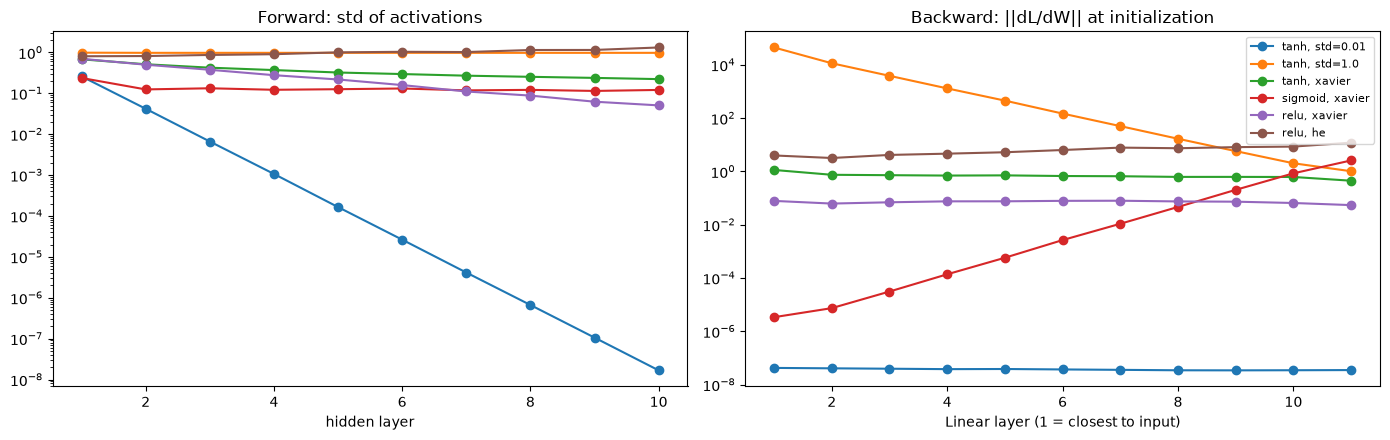

,act std (layer 1),act std (layer 10),||dW|| layer 1,||dW|| layer 11,grad ratio (1 / 11)
"tanh, std=0.01",2.58e-01,1.67e-08,4.20e-08,3.48e-08,1.21e+00
"tanh, std=1.0",9.83e-01,9.74e-01,4.46e+04,1.01e+00,4.41e+04
"tanh, xavier",6.76e-01,2.22e-01,1.13e+00,4.45e-01,2.53e+00
"sigmoid, xavier",2.36e-01,1.21e-01,3.36e-06,2.57e+00,1.31e-06
"relu, xavier",6.97e-01,5.05e-02,7.79e-02,5.41e-02,1.44e+00
"relu, he",8.03e-01,1.32e+00,3.95e+00,1.20e+01,3.31e-01


In [143]:
# 實驗 2：訊號在 10 層網路中的傳遞（只做一次 forward + backward，不訓練）
# 784 → [256] × 10 → 10，用 1,000 張真實影像
DEPTH = 10
X_sig, y_sig = X_tr[:1000].astype(np.float64), y_tr[:1000]
configs = [
    ("tanh", 0.01),
    ("tanh", 1.0),
    ("tanh", "xavier"),
    ("sigmoid", "xavier"),
    ("relu", "xavier"),
    ("relu", "he"),
]

act_std, grad_norm = {}, {}
for act, init in configs:
    net = MLP(
        hidden=(256,) * DEPTH, activation=act, init=init, dtype=np.float64, seed=0
    ).build(784, 10)
    net.loss_and_grads(X_sig, y_sig)
    name = f"{act}, {init if isinstance(init, str) else 'std=' + str(init)}"
    act_std[name] = [
        layer.out.std() for layer in net.layers_ if not isinstance(layer, Linear)
    ]
    grad_norm[name] = [np.linalg.norm(lin.grads["W"]) for lin in net.linears_]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for name in act_std:
    axes[0].plot(range(1, DEPTH + 1), act_std[name], "o-", label=name)
    axes[1].plot(range(1, DEPTH + 2), grad_norm[name], "o-", label=name)
axes[0].set_yscale("log")
axes[0].set_xlabel("hidden layer")
axes[0].set_title("Forward: std of activations")
axes[1].set_yscale("log")
axes[1].set_xlabel("Linear layer (1 = closest to input)")
axes[1].set_title("Backward: ||dL/dW|| at initialization")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

summary = pd.DataFrame(
    {
        "act std (layer 1)": {k: v[0] for k, v in act_std.items()},
        "act std (layer 10)": {k: v[-1] for k, v in act_std.items()},
        "||dW|| layer 1": {k: v[0] for k, v in grad_norm.items()},
        "||dW|| layer 11": {k: v[-1] for k, v in grad_norm.items()},
    }
)
summary["grad ratio (1 / 11)"] = summary["||dW|| layer 1"] / summary["||dW|| layer 11"]
display(summary.style.format("{:.2e}"))

sigmoid val_acc 每個 epoch：[0.1044, 0.1124, 0.1044]
tanh    val_acc 每個 epoch：[0.9429, 0.9567, 0.9609]
relu    val_acc 每個 epoch：[0.9425, 0.9597, 0.9639]


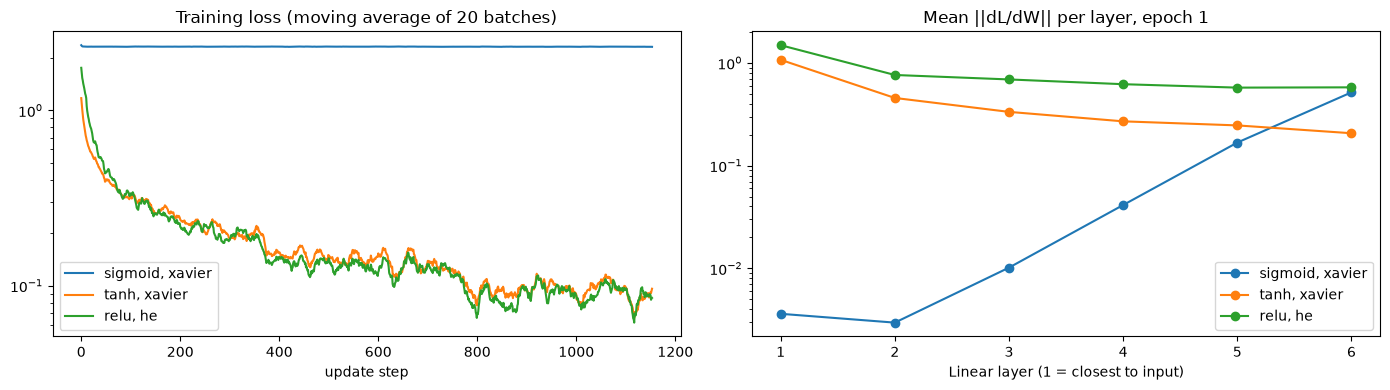

In [144]:
# 實驗 2（續）：實際訓練 5 個隱藏層的網路（784 → [128] × 5 → 10），3 個 epoch
deep_runs = {}
for act, init in [("sigmoid", "xavier"), ("tanh", "xavier"), ("relu", "he")]:
    m = MLP(hidden=(128,) * 5, activation=act, init=init, lr=0.1, n_epochs=3, seed=0)
    m.fit(X_tr, y_tr, X_va, y_va, verbose=False)
    deep_runs[f"{act}, {init}"] = m
    print(f"{act:7s} val_acc 每個 epoch：{m.history_['val_acc']}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for name, m in deep_runs.items():
    bl = np.array(m.history_["batch_loss"])
    axes[0].plot(
        np.convolve(bl, np.ones(20) / 20, mode="valid"), label=name
    )  # 20 步移動平均
    axes[1].plot(range(1, 7), m.history_["grad_norm"][0], "o-", label=name)
axes[0].set_yscale("log")
axes[0].set_xlabel("update step")
axes[0].set_title("Training loss (moving average of 20 batches)")
axes[0].legend()
axes[1].set_yscale("log")
axes[1].set_xlabel("Linear layer (1 = closest to input)")
axes[1].set_title("Mean ||dL/dW|| per layer, epoch 1")
axes[1].legend()
fig.tight_layout()
plt.show()

### TODO 10（問答）實驗 2：梯度消失與初始化

> **(1)** forward：訊號的大小怎麼一層一層變化？
>
> **(a)** 讀左圖與表格：tanh 用 std = 0.01、std = 1.0、Xavier 時，第 10 層激活值的標準差各是多少？
>
> **(b)** 一個 Linear 層的輸出 $z_k = \sum_{j=1}^{\text{fan}_{\text{in}}} h_j W_{jk}$（$h_j$ = 這一層的第 $j$ 個輸入，即前一層激活後的輸出；fan_in = 輸入個數 $d_{\text{in}}$、fan_out = 輸出個數 $d_{\text{out}}$；$\text{Var}$ = 變異數、$E[\cdot]$ = 期望值，這裡是對「所有樣本、所有單元」平均）。假設 $h_j$ 與 $W_{jk}$ 獨立、$W$ 的平均為 0，則 $\text{Var}(z) = \text{fan}_{\text{in}}\cdot\text{Var}(W)\cdot E[h^2]$。tanh 在 0 附近 $\approx$ 恆等函數，所以每過一層，訊號的變異數大約乘上 $\text{fan}_{\text{in}}\cdot\text{Var}(W)$。算算看 std = 0.01、fan_in = 256 時這個倍數是多少？疊 10 層呢？
>
> **(c)** std = 1.0 時倍數是多少？tanh 的輸出被限制在 $(-1, 1)$，訊號「放大」到最後會變成什麼樣子？（提示：看第 10 層的 std 接近多少）
>
> **(d)** 由 (b)：要讓訊號大小一層一層維持不變，$\text{Var}(W)$ 應該取多少？這就是 Xavier 的想法（3A 的 `init_std`）（Xavier 用 $2/(\text{fan}_{\text{in}} + \text{fan}_{\text{out}})$ 是同時照顧 forward 與 backward 的折衷；fan_in = fan_out 時兩者相同）。

(a) 分別為 1.67e-10, 9.74e-1, 2.22e-1

**修正**：第一個是 **1.67e-8**（表格 `act std (layer 10)` 欄：tanh, std=0.01 → 1.674e-08），其他兩個 ✓。

(b) 256 × 0.01² ≈ 0.0256，疊十層的話就是 0.0256¹⁰ ≈ 1.2e-16

✓。補充：0.0256 是**變異數**的倍數，標準差的倍數是 $\sqrt{0.0256} = 0.16$。10 層之後變異數縮成 $1.2\times10^{-16}$、標準差縮成 $0.16^{10} \approx 1.1\times10^{-8}$ —— 跟實測的 $1.67\times10^{-8}$ 同一個數量級。（更精確：第 1 層的 fan_in 是 784，實測 std 0.258；之後 9 層各乘 0.16：$0.258 \times 0.16^9 \approx 1.8\times10^{-8}$，幾乎完全吻合。）

(c) std = 1.0 時為 256 × 1² = 256，看表格的話可以查到大約是 2.22e-1

**修正**：倍數 256 ✓，但 2.22e-1 是 **tanh, xavier** 那一列；tanh, std=1.0 的第 10 層 std 是 **0.974**。

- 每過一層變異數要乘 256（標準差乘 16），如果是線性網路，訊號會爆炸。
- 但 tanh 的輸出被限制在 $(-1, 1)$：輸入 $|z|$ 很大時，$\tanh z$ 幾乎就是 $+1$ 或 $-1$ → 輸出的 std 停在接近 1（0.974），不會無限放大。這叫**飽和**（saturation）。
- 飽和的代價：輸出幾乎只剩正負號（每個單元只是一個「開關」），細節資訊消失；而且飽和區的導數 $1 - \tanh^2 z \approx 0$，梯度很難通過（(3)(c) 會看到另一面）。

(d) Var(W) 乘以 fan_in 要等於 1 的話，Var(W) 必須取 fan_in 的倒數

✓。$\text{Var}(W) = 1/\text{fan}_{\text{in}}$（這個版本叫 LeCun 初始化）。Xavier 用 $2/(\text{fan}_{\text{in}} + \text{fan}_{\text{out}})$：forward 要求 $\text{fan}_{\text{in}}\cdot\text{Var}(W) = 1$，backward（梯度乘 $W^\top$，加總的是 fan_out 項）要求 $\text{fan}_{\text{out}}\cdot\text{Var}(W) = 1$，兩者取平均的折衷；fan_in = fan_out 時三者相同。

> **(2)** ReLU 為什麼要用 He（$\text{Var}(W) = 2/\text{fan}_{\text{in}}$）而不是 Xavier？
>
> **(a)** 讀表格：relu + Xavier 與 relu + He，第 10 層的激活 std 各是多少？
>
> **(b)** ReLU 把一半的輸入（負的）變成 0。如果 $z$ 對稱分布在 0 附近，$E[\text{ReLU}(z)^2]$ 是 $E[z^2]$ 的幾倍？代回 (1)(b) 的公式，說明 He 多出來的那個 2 是在補償什麼。

(a) 分別為 5.05e-2 與 1.32e+0

✓。relu + Xavier：訊號一層層縮小（第 10 層只剩 0.05）；relu + He：維持在 1 附近。

(b) 假設對稱的話那麼 E[ReLU(z)²] = E[(0.5z)²] = 0.25 E[z²] 大約 0.25 倍，所以 He 如果乘以 2，平方下與前面的 0.25 相乘會變回 1

**修正**：ReLU 不是把每個值變成一半（$0.5z$），而是把**一半的樣本**變成 0、另一半**原封不動**：

$$\text{ReLU}(z)^2 = \begin{cases} z^2 & z > 0 \text{（機率 1/2）} \\ 0 & z \le 0 \text{（機率 1/2）} \end{cases} \quad\Longrightarrow\quad E[\text{ReLU}(z)^2] = \frac{1}{2}E[z^2]$$

（$z$ 對稱分布時，$z > 0$ 那一半的 $z^2$ 平均值等於整體的 $E[z^2]$。）

所以是 **1/2 倍**，不是 1/4 倍。代回 (1)(b) 的公式：每過一層 $\text{Var}(z_{\text{下一層}}) = \text{fan}_{\text{in}}\cdot\text{Var}(W)\cdot\frac{1}{2}\text{Var}(z)$。要讓倍數等於 1：

$$\text{fan}_{\text{in}}\cdot\text{Var}(W)\cdot\frac{1}{2} = 1 \quad\Longrightarrow\quad \text{Var}(W) = \frac{2}{\text{fan}_{\text{in}}}$$

He 多出來的那個 2，補償的正是 ReLU 丟掉的那一半訊號。（照你的 1/4 推，要乘 4 才對得回來，與 He 的 2 不符。）

用實驗驗證：relu + Xavier（$\text{fan}_{\text{in}}$ = fan_out = 256 時 $\text{Var}(W) = 1/256$）每層倍數 $= 256 \times \frac{1}{256} \times \frac{1}{2} = 0.5$，標準差每層乘 $\sqrt{0.5} \approx 0.71$，9 層後只剩 $0.71^9 \approx 0.044$ 倍 —— 跟實測第 10 層的 0.05 同一個數量級（第 1 層 fan_in = 784 不同，所以不會完全一樣）。

> **(3)** backward：梯度的消失。
>
> **(a)** 讀表格的最後一欄（第 1 層與第 11 層 $\|\partial L/\partial W\|$ 的比值）：sigmoid + Xavier 是多少？tanh + Xavier 和 relu + He 呢？tanh + std = 1.0 呢？（右圖：它的梯度往輸入方向是變小還是變大？）
>
> **(b)** 反向傳播每經過一個激活層，梯度要逐元素乘上 $f'(z)$（TODO 4）。用 TODO 6 (2)(c) 的答案：sigmoid 每一層最多把梯度縮小成幾分之幾？經過 10 層呢？tanh 在 0 附近的導數是多少？ReLU 呢？
>
> **(c)** tanh + std = 1.0 的梯度反而往輸入方向「爆炸」。反向傳播每經過一個 Linear 層要乘上 $W^{\top}$（`dX = dout @ W.T`）；$W$ 的標準差是 1、fan_out 是 256 時，這一步大約把梯度放大幾倍？雖然大部分單元已經飽和（$f' \approx 0$），只要還有少數沒飽和的單元，梯度就會被一層層放大。所以「梯度消失」與「梯度爆炸」其實是同一件事的兩面：每一層的放大倍數 ≠ 1，乘上很多層之後就是指數級的變化。
>
> **(d)** 看第二張圖（實際訓練 5 個隱藏層）：sigmoid 的 loss 曲線跟另外兩個有什麼不同？用 (a)(b) 解釋：哪幾層學得最慢？
>
> **(e)** 用 (1)–(3) 說明：為什麼 1986 年就有反向傳播，「深」的網路卻要等到 2010 年代才訓練得起來？（ReLU、好的初始化是答案的一部分；BatchNorm、殘差連接會在第三章 CNN 遇到）

(a) 1.31e-06，2.53，3.31e-01，4.41e+4

✓（依序是 sigmoid + Xavier、tanh + Xavier、relu + He、tanh + std=1.0）。tanh + std=1.0 往輸入方向**變大**（爆炸），sigmoid 往輸入方向變小（消失）。

(b) 縮小成 0.25 倍，經過 10 層後會是 0.25¹⁰ ≈ 9.53e-7，tanh 在 0 附近的導數接近 0，ReLU 則要看是從左邊還是右邊接近 0，左邊直接等於 0，右邊的話就是 x 本身

- sigmoid ✓：每層最多乘 0.25，10 層 $\le 0.25^{10} \approx 9.5\times10^{-7}$ —— 跟實測比值 $1.3\times10^{-6}$ 幾乎一樣，梯度消失主要就是 sigmoid 的導數造成的。

**修正**（與 TODO 6 (2)(c) 同一個混淆）：

- tanh 在 0 附近的**函數值**接近 0，但**導數**是 $1 - \tanh^2(0) = 1 - 0 = 1$ → 梯度通過時幾乎不縮小，所以 tanh + Xavier 的比值是 2.53，沒有消失。
- ReLU 的**導數**：$x > 0$ 時是 **1**（不是 $x$ 本身 —— $x$ 是 ReLU 的函數值），$x < 0$ 時是 0。通過的部分原封不動，所以也不會一層層縮小。

(c) 放大 1² × 256 倍，為 256 倍

**補充**：256 是**變異數**的倍數，對應到梯度的大小（標準差、範數）是 $\sqrt{256} = 16$ 倍。

- `dX = dout @ W.T`：每個元素是 256 項 $\text{dout}\cdot W$ 的和，$W$ 的標準差是 1 → 變異數乘 256、大小乘 16。
- 實測整體只放大了 $4.4\times10^4$ 倍（每層約 2.9 倍），比 $16^{10}$ 小很多，因為大部分單元飽和（$f' \approx 0$）把梯度砍掉了；只要每層的淨倍數仍大於 1，10 層之後就是指數級的爆炸。
- 所以「消失」和「爆炸」是同一件事的兩面：每層的倍數（$W$ 的大小 × 激活函數的導數）≠ 1，乘上很多層之後就是指數級的變化。好的初始化就是讓這個倍數盡量接近 1。

(d) sigmoid 的 training loss 幾乎不會動，只有一開始有下沉後續直接變平的，sigmoid 的 grad ratio 是最小的，表示層數越多，傳到後面梯度幾乎消失了，所以在更新權重的時候更新的量很小，所以非常的慢

✓。補充兩點：

- 精確地說，梯度消失的方向是「傳到**前面**（靠近輸入）的層」：backward 從輸出往輸入傳，越靠近輸入的層梯度越小。所以學得最慢的是**最前面幾層**，它們幾乎沒有被更新，後面的層只能拿「幾乎是隨機投影」的特徵去分類。
- 結果：sigmoid 版本 3 個 epoch 的 val accuracy 一直在 0.10 附近（等於亂猜），tanh 和 ReLU 都到 0.96。

(e) 不清楚原因，感覺你都說完了

**補寫**：把 (1)–(3) 串起來：

1. **1986–2000 年代的標準配置**是 sigmoid（或 tanh）＋「小的隨機初始化」。由 (3)(b)，sigmoid 每層至少把梯度縮成 1/4；由 (1)(b)，太小的初始化讓訊號一層層趨近 0（太大則飽和，梯度一樣消失）。網路一深，前面幾層幾乎收不到梯度 —— 淺的網路（1–2 個隱藏層）還能訓練，深的訓練不起來。
2. **沒有原理性的初始化**：Xavier（2010）、He（2015）的推導，就是 (1)(d)、(2)(b) 做的事 —— 讓每層訊號與梯度的變異數維持在 1 附近。在這之前，初始化多半靠經驗調。
3. **ReLU 普及（約 2010–2012）**：正半邊導數恆為 1，梯度不會被一層層縮小，也不會飽和。
4. **其他條件**：GPU 算力、大量資料（ImageNet）在 2010 年前後才到位；之後的 BatchNorm（2015，每層重新標準化）、殘差連接（2015，讓梯度有一條「直通」的路）讓上百層的網路也能訓練（第三章 CNN 會遇到）。

所以反向傳播本身在 1986 年就是對的；缺的是讓「每層倍數接近 1」的工具（激活函數、初始化、正規化、架構），以及足夠的算力與資料。

In [145]:
# 實驗 3：對稱性 —— 所有權重都是 0.01（不隨機）
sym = MLP(hidden=(64,), activation="relu", init="constant", lr=0.1, n_epochs=2, seed=0)
sym.fit(X_tr, y_tr, X_va, y_va, verbose=False)
W1 = sym.linears_[0].params["W"]  # (784, 64)：每一欄是一個隱藏單元的權重
print("constant 初始化：val_acc =", sym.history_["val_acc"][-1])
print("  64 個隱藏單元的權重，彼此之間的最大差異：", np.abs(W1 - W1[:, :1]).max())
print("  第一個 Linear 的 W 的 rank：", np.linalg.matrix_rank(W1))

rnd = MLP(hidden=(64,), activation="relu", init="he", lr=0.1, n_epochs=2, seed=0)
rnd.fit(X_tr, y_tr, X_va, y_va, verbose=False)
print("He 隨機初始化：val_acc =", rnd.history_["val_acc"][-1])

constant 初始化：val_acc = 0.2857
  64 個隱藏單元的權重，彼此之間的最大差異： 0.0
  第一個 Linear 的 W 的 rank： 1
He 隨機初始化：val_acc = 0.9541


### TODO 11（問答）實驗 3：對稱性

> **(1)** constant 初始化訓練 2 個 epoch 後，64 個隱藏單元的權重彼此差多少？第一層 $W$ 的 rank 是多少？validation accuracy 比 softmax 邏輯回歸好還是差？

差異為 0，第一層 W 的 rank 為 1，validation accuracy 比較差。

✓。數字：64 個隱藏單元的權重最大差異 0.0、rank = 1、val accuracy 約 0.29（softmax 邏輯回歸 0.914、同樣結構用 He 隨機初始化 0.954）。

**補充**（為什麼比邏輯回歸還差很多）：64 個一模一樣的單元等於只有 **1 個**隱藏單元，網路實際上是 784 → **1** → 10：整張影像先被壓成**一個數字**，再用這一個數字分 10 類。資訊瓶頸比邏輯回歸（784 → 10，直接用 784 個像素分類）嚴重得多，所以連邏輯回歸都贏不了。rank = 1 就是這件事的直接證據：$W_1$ 的 64 欄全部相同，只張成一個方向。

> **(2)** 為什麼隱藏單元會「一直一模一樣」？
>
> **(a)** 初始時所有隱藏單元的權重相同 → forward 時它們的輸出 $h_k$ 有什麼關係？
>
> **(b)** 第二個 Linear 的 $W_2$ 也全部是 0.01 → backward 時傳回每個隱藏單元的梯度 $\partial L/\partial h_k$ 有什麼關係？（提示：`dX = dout @ W.T`，$W_2$ 的每一列都一樣）
>
> **(c)** 所以每個隱藏單元的 $W_1$ 欄位收到的梯度一樣、更新一樣 → 下一步仍然一樣。64 個單元實際上等於幾個？
>
> **(d)** 隨機初始化在這裡的角色是什麼？（「打破對稱」）如果全部初始化成 0 呢？（提示：ReLU(0) = 0、ReLU′(0) = 0）

(a) 權重相同，矩陣乘法過後還是就只是權重的常數倍數，h_k 也只是縮放關係

**修正**：不是倍數或縮放關係，而是**完全相等**。第 $k$ 個隱藏單元的輸出

$$h_k = \text{ReLU}\Big(\sum_j x_j W_{1,jk} + b_{1,k}\Big)$$

所有單元的 $W_{1,jk}$（第 $k$ 欄）和 $b_{1,k}$ 都一樣，所以對同一張影像，64 個 $h_k$ 是**同一個數字**：$h_1 = h_2 = \cdots = h_{64}$。

(b) 就一樣啊，變成倍數關係

**修正**：同樣是**完全相等**，不是倍數。

$$\frac{\partial L}{\partial h_k} = \sum_{m=1}^{10} \frac{\partial L}{\partial Z_m}\, W_{2,km}$$

$W_2$ 全部是 0.01，第 $k$ 列 $(W_{2,k1}, \dots, W_{2,k,10})$ 對每個 $k$ 都一樣，所以 64 個隱藏單元收到的梯度 $\partial L/\partial h_k$ 也完全相同。

(c) 所以做 64 次等同於做 1 次

✓（說法可以更精確）：64 個單元實際上等於 **1 個**。完整的推理是一個「一直維持下去」的循環：

1. 某一步開始時，所有單元的權重相同（第一步是因為初始化）；
2. → forward 輸出相同（(a)）；
3. → backward 收到的梯度相同（(b)），而且 ReLU 的 mask 也相同，所以傳到 $z_k$ 的梯度相同；
4. → $W_1$ 每一欄的梯度 $\partial L/\partial W_{1,:,k} = X^\top\,\partial L/\partial z_k$ 相同，$W_2$ 每一列的梯度也相同 → 更新量相同；
5. → 更新後權重仍然相同，回到 1。

所以不論訓練多久，它們永遠一模一樣（數學上的歸納法）。

(d) 隨機初始化是為了不要有一個全部都一樣的初始值導致更新後跟沒更新一樣，初始化成 0 的話第一次做 forward 矩陣運算後不就全是 0 了嗎，後面直接做不下去，沒有意義

**前半補充**：不是「更新後跟沒更新一樣」—— constant 初始化時參數**有更新**，只是每個單元更新得一模一樣。隨機初始化的作用是**打破對稱**（symmetry breaking）：讓每個單元一開始就不同，收到不同的梯度，才會各自學到不同的特徵。（bias 可以初始化成 0，因為 $W$ 已經是隨機的，對稱性已經被打破。）

**後半修正**：初始化成 0 時，運算其實做得下去，只是幾乎學不到東西。逐步看（$W_1 = 0$、$W_2 = 0$、$b = 0$）：

- forward：$z_1 = XW_1 + b_1 = 0$ → $h_1 = \text{ReLU}(0) = 0$ → $Z = h_1W_2 + b_2 = b_2$。loss 算得出來（每張影像都輸出同一組分數 $b_2$）。
- backward：
  - $\partial L/\partial W_2 = h_1^\top\,\text{dZ} = 0$（因為 $h_1 = 0$）；
  - $\partial L/\partial h_1 = \text{dZ}\,W_2^\top = 0$（因為 $W_2 = 0$）→ 再乘 $\text{ReLU}'(0) = 0$ → $\partial L/\partial W_1 = 0$、$\partial L/\partial b_1 = 0$；
  - 只有 $\partial L/\partial b_2 = \sum_i \text{dZ}_i$ 不是 0。
- 結果：只有最後一層的 bias $b_2$ 會被更新，網路學到的只是「每一類出現的比例」，跟 Dummy prior 一樣（accuracy 約 0.11）。

（換成 tanh 也救不了：雖然 $\tanh'(0) = 1$，但 $W_2 = 0$ 讓 $\partial L/\partial h_1 = 0$，前面的梯度一樣全部是 0。）

**補充（複習用：「完全相等」比的是誰）**

「完全相等」比的是**同一個網路裡、同一層的隱藏單元彼此之間**，不是兩個不同的網路。縮小的例子：輸入 3 個像素 $x = (x_1, x_2, x_3)$，隱藏層 4 個單元，$W_1$ 是 $(3, 4)$，每一**欄**是一個單元的權重。

網路 A：全部權重 = 2

$$W_1 = \begin{pmatrix} 2&2&2&2\\ 2&2&2&2\\ 2&2&2&2 \end{pmatrix}
\quad\Rightarrow\quad
h_k = \text{ReLU}(2x_1 + 2x_2 + 2x_3) \;\text{ 對 } k = 1,2,3,4 \text{ 都一樣}$$

網路 B：全部權重 = 1 → $h_k = \text{ReLU}(x_1 + x_2 + x_3)$，對 $k = 1, 2, 3, 4$ 也都一樣。

| 比較的對象 | 關係 |
| --- | --- |
| 網路 A 的 $h_1$ vs 網路 A 的 $h_2$ | **完全相等**（同一欄權重）← 對稱性問題指的是這個 |
| 網路 A 的 $h_1$ vs 網路 B 的 $h_1$ | 兩倍（不同網路，與對稱性無關） |

全部是 2 還是全部是 1，只決定那個數字的大小；同一個網路裡的 4 個單元算出同一個數字，等於只有 1 個單元。

**與「共線」的關係**：

- 共線：各欄是同一個方向的倍數，例如 $(1,1,1)$ 和 $(2,2,2)$；constant 初始化時各欄**完全相同**，是共線的特例（倍數都是 1）。
- 兩種情況 $W_1$ 的 rank 都是 1：所有欄只張出一個方向，整張影像只被投影到一個數字上。實驗輸出的 rank = 1 量的就是這件事。

**延伸：一半初始化成 2、一半成 1 呢？**

- 兩群單元的輸出不同（差 2 倍），但 $W_2$ 的每一列仍然相同 → 傳回每個單元的梯度一樣 → 每一欄每一步都加上**同樣的更新量**。
- 所以兩群之間的差別永遠只是初始的那一點點，不會長出新的方向，學不出不同的特徵。
- 要讓每個隱藏單元各自學到不同的特徵，各欄一開始就要指向**不同的方向** —— 這就是隨機初始化在做的事。

,final train_loss,val_acc
lr,,
0.001,0.619146,0.8462
0.010,0.264022,0.9281
0.100,0.098422,0.9658
0.500,0.071908,0.9631
2.000,2.023956,0.1900


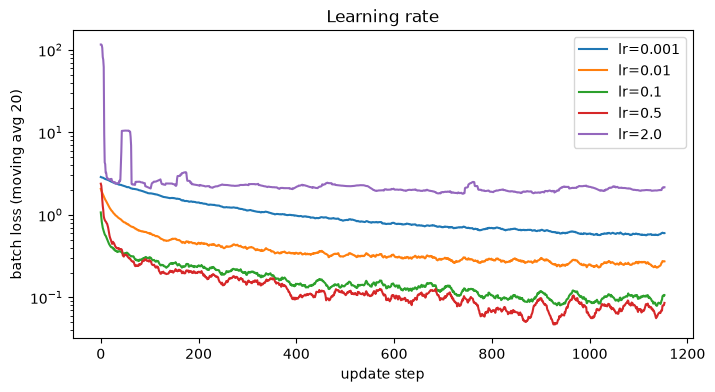

In [146]:
# 實驗 4a：學習率（784 → 256 → 10，ReLU，batch 128，3 epochs）
lr_runs = {}
with np.errstate(over="ignore", invalid="ignore"):
    for lr in [0.001, 0.01, 0.1, 0.5, 2.0]:
        m = MLP(hidden=(256,), lr=lr, n_epochs=3, seed=0).fit(
            X_tr, y_tr, X_va, y_va, verbose=False
        )
        lr_runs[lr] = m
display(
    pd.DataFrame(
        {
            lr: {
                "final train_loss": m.history_["train_loss"][-1],
                "val_acc": (
                    m.history_["val_acc"][-1] if m.history_["val_acc"] else np.nan
                ),
            }
            for lr, m in lr_runs.items()
        }
    ).T.rename_axis("lr")
)

fig, ax = plt.subplots(figsize=(8, 4))
for lr, m in lr_runs.items():
    bl = np.array(m.history_["batch_loss"], dtype=float)
    ax.plot(np.convolve(bl, np.ones(20) / 20, mode="valid"), label=f"lr={lr}")
ax.set_yscale("log")
ax.set_xlabel("update step")
ax.set_ylabel("batch loss (moving avg 20)")
ax.set_title("Learning rate")
ax.legend()
plt.show()

In [147]:
# 實驗 4b：batch size（固定 3 個 epoch、lr = 0.1）
bs_rows = []
for bs in [16, 128, 1024]:
    t0 = time.perf_counter()
    m = MLP(hidden=(256,), lr=0.1, batch_size=bs, n_epochs=3, seed=0).fit(
        X_tr, y_tr, X_va, y_va, verbose=False
    )
    bs_rows.append(
        {
            "batch_size": bs,
            "updates": len(m.history_["batch_loss"]),
            "seconds": round(time.perf_counter() - t0, 1),
            "val_loss": m.history_["val_loss"][-1],
            "val_acc": m.history_["val_acc"][-1],
        }
    )
# 加碼：batch 1024，但學習率放大 8 倍
m = MLP(hidden=(256,), lr=0.8, batch_size=1024, n_epochs=3, seed=0).fit(
    X_tr, y_tr, X_va, y_va, verbose=False
)
bs_rows.append(
    {
        "batch_size": "1024 (lr=0.8)",
        "updates": len(m.history_["batch_loss"]),
        "seconds": np.nan,
        "val_loss": m.history_["val_loss"][-1],
        "val_acc": m.history_["val_acc"][-1],
    }
)
display(pd.DataFrame(bs_rows))

,batch_size,updates,seconds,val_loss,val_acc
0,16,9375,2.0,0.1039,0.9701
1,128,1173,0.6,0.1204,0.9658
2,1024,147,0.4,0.2405,0.9316
3,1024 (lr=0.8),147,NaN,0.3075,0.9013


### TODO 12（問答）實驗 4：學習率與 batch size

> **(1)** 學習率。
>
> **(a)** 讀表格與圖：哪個 lr 太小（3 個 epoch 後還在慢慢降）？哪個 lr 太大？太大的表現是什麼（發散成 nan，還是震盪、卡在很高的 loss）？
>
> **(b)** 對照第一章第二節（線性回歸 $\text{lr} > 2/\lambda_{\max}$ 時 loss 發散；$\lambda_{\max}$ = loss 的 Hessian（二階導數矩陣）的最大特徵值，也就是最陡方向的曲率，跟 3B weight decay 的 $\lambda$ 是不同的東西）與第三節（邏輯回歸「耐」大學習率）：神經網路的 loss 不是凸函數，曲率也隨位置改變。所以「最大可用的學習率」還能用一個公式事先算出來嗎？實務上怎麼找？

(a) lr = 2.0 太大了，他會卡在很高的 loss 下不去

✓。補充：

- **太小的也要看**：lr = 0.001 在 3 個 epoch 後 train loss 還有 0.62、val acc 只有 0.846，曲線還在慢慢往下 —— 方向對，但步伐太小、走不到。lr = 0.01 也偏慢（0.928）。0.1 與 0.5 最好（0.966、0.963）。
- **太大的表現是「卡住」而不是 nan**：lr = 2.0 的 train loss 停在 2.02（亂猜是 $\ln 10 \approx 2.30$），val acc 0.19。原因通常是 **ReLU 死掉**（dead ReLU）：一步走太大，把某些隱藏單元的 $w_k$、$b_k$ 推到「對所有影像 $z_k < 0$」的位置 → 輸出永遠是 0、ReLU 導數永遠是 0 → 這個單元再也收不到梯度，永遠關著。大部分單元死掉後，網路就卡在接近亂猜的地方。
- 沒有變成 nan，是因為交叉熵的梯度 $(P - Y)/n$ 每個元素都在 $(-1, 1)$ 之間，梯度有上界（同第一章第三節邏輯回歸「耐」大學習率的理由），不會像線性回歸那樣指數爆炸。

(b) 神經網路沒辦法寫成一個矩陣找 lambda_max lambda_min，實務上可能可以用網格搜索，先跑跑看幾個 epoch 有沒有下去，沒有下去的 lr 就直接捨棄掉

✓。補充精確說法與實務做法：

- 神經網路的 loss 不是二次函數，Hessian（曲率）**隨位置改變**，而且不保證正定（非凸）。即使在某一點算出 $\lambda_{\max}$，走幾步之後曲率就變了，所以沒有一個能事先算好、全程適用的上限。（可以在訓練中用 Hessian-向量乘積的冪次法估計當下的 $\lambda_{\max}$，但這是研究工具，不是日常做法。）
- 實務做法：
  1. **log 尺度掃描**：例如 $10^{-4}, 10^{-3}, \dots, 1$，每個只跑少量 epoch（就是你說的做法，也是實驗 4a 做的事）。
  2. **LR range test**：只跑一次訓練，每一步把 lr 乘上一個固定倍數（指數增加），畫 loss 對 lr 的曲線；loss 開始暴衝的 lr 就是上限，實際取它的 1/3～1/10。
  3. **學習率排程**：開頭先用小 lr 暖身（warmup），之後逐漸降低（衰減），比固定一個 lr 穩定。
  4. Adam 等自適應方法對 lr 比較不敏感（第三章 CNN 會比較）。

> **(2)** batch size。
>
> **(a)** 同樣 3 個 epoch，batch 16、128、1024 各做了幾次更新？各花多少時間？val accuracy 如何？
>
> **(b)** batch 越大，每次更新的梯度越準（雜訊越小），為什麼固定 epoch 數時大 batch 反而比較差？（提示：看更新次數）
>
> **(c)** batch 1024 把學習率放大 8 倍（= 1024 / 128）之後怎麼樣？這是常見的「linear scaling rule」：batch 放大 $k$ 倍，梯度的雜訊變小，可以走大一點的步伐。它在什麼情況下會失效？（提示：(1) 的「太大的學習率」）
>
> **(d)** batch 16 每個 epoch 比 batch 128 慢很多，但總計算量（乘加次數）是一樣的。慢在哪裡？（提示：NumPy／GPU 一次做一個大矩陣乘法 vs 做很多個小的）

(a) 9375、1173、147 次更新，分別花了 1.9、0.5、0.3 秒，val_acc 是 batch_size 16 最好，再來是 128，最後才是 1024

✓。數字（val acc 用驗證時的參考結果）：batch 16 → 0.971、128 → 0.966、1024 → 0.932。

(b) 固定 epoch 數的情況下，資料用小 batch 可以更新較多次權重

✓。補充：batch 1024 的梯度雖然比較準，但 3 個 epoch 只走了 147 步；batch 16 走了 9,375 步。訓練初期離最佳解還很遠，「多走幾步」比「每一步方向更準」重要得多。另外，小 batch 的梯度雜訊也有一點正則化的效果（讓模型不容易卡在只適合訓練集的尖銳谷底），列入待補強。

(c) 不確定什麼時候會失效，這個不是用試出來的嗎？

**補寫**：最後確實要試，但 linear scaling rule 有道理可循，知道道理才知道「該在哪裡試」：

- **它在說什麼**：batch 放大 $k$ 倍，走 1 步、學習率 $k \cdot \text{lr}$，大約等於用小 batch 走 $k$ 步、每步學習率 $\text{lr}$ —— 前提是這 $k$ 小步之間梯度變化不大（$k$ 個小 batch 梯度的平均 ≈ 一個大 batch 的梯度）。
- **什麼時候失效**：
  1. **$k \cdot \text{lr}$ 超過穩定上限**：學習率太大就會震盪、ReLU 死掉（(1) 的 lr = 2.0）。放大學習率不能超過曲率允許的範圍，所以 batch 不能無限放大。
  2. **訓練初期**：梯度變化很快，「$k$ 小步 ≈ 1 大步」的前提不成立 → 所以大 batch 訓練通常要搭配 warmup。
  3. **batch 已經很大**：超過某個「臨界 batch size」之後，梯度雜訊不再是限制，再放大 batch 也換不到更大的步伐。
- **本次實驗就是失效的例子**：batch 1024 把 lr 從 0.1 放大到 0.8，val acc 從 0.932 **降**到 0.926，沒有追上 batch 128 的 0.966。lr = 0.8 已經接近 (1) 看到的不穩定區（0.5 還好、2.0 就壞了），而且只有 147 步，前提 2 也不成立。

(d) 慢在計算次數，每次資料少可能算得快，可是累積次數一多會超過資料多但算得慢

**修正**：三種 batch size 的**總計算量（乘加次數）一樣**（都是把 50,000 筆走 3 遍），所以不是計算次數的問題，慢在：

- **固定開銷 × 呼叫次數**：每次更新都要經過 Python 迴圈、函式呼叫、建立新陣列、記錄 loss 等固定成本。batch 16 要做 9,375 次，batch 128 只要 1,173 次 —— 次數差 8 倍，固定開銷也差 8 倍。（與 TODO 8 (2)「計算量 ≠ 實際時間」是同一件事。）
- **硬體用不滿**：$(16, 784) \times (784, 256)$ 這種小矩陣乘法，CPU 的多核心與向量指令（GPU 更明顯）吃不飽，大部分時間花在搬資料而不是算；大矩陣才能讓硬體滿載。所以同樣的乘加次數，切成很多個小矩陣做就是比較慢。
- 實務上 batch size 的選擇因此是取捨：太小 → 硬體用不滿、每個 epoch 很慢；太大 → 每個 epoch 更新次數少、可能需要更多 epoch 或更大的學習率（(c) 的限制）。

---
## 4. 套件實作：PyTorch

PyTorch 的三個核心物件，跟 3B 的手寫 MLP 一一對應：

| 手寫 NumPy | PyTorch | 說明 |
| --- | --- | --- |
| `Linear`、`ReLU`、… 的 `forward` | `nn.Linear`、`nn.ReLU`、`nn.Sequential` | `nn.Linear` 的權重存成 $(d_{\text{out}}, d_{\text{in}})$，算 `X @ W.T + b`（**轉置**，跟我們相反） |
| 每一層存 cache ＋ 手寫 `backward` | **autograd**：forward 時自動記錄計算圖，`loss.backward()` 沿圖倒著套鏈鎖律 | 每個參數的梯度存在 `param.grad` |
| `SoftmaxCrossEntropy` | `nn.functional.cross_entropy`（輸入 logits，內部做 log-softmax） | 一樣是「平均」交叉熵 |
| `MLP.step()` | `torch.optim.SGD(params, lr, weight_decay)` 的 `step()` | weight decay 的定義相同：梯度加上 $\lambda W$ |

**核對方式**：把 3B 訓練好的權重複製進 PyTorch 模型，在 float64 下比對 logits、loss、每個參數的梯度 —— 應該一致到 ~1e-12。
（Apple 的 MPS 不支援 float64，所以核對在 CPU 上做；之後的訓練才用 MPS。）

#### 前置複習：PyTorch 的基本物件

| 物件／操作 | 說明 | 對照 NumPy／手寫版 |
| --- | --- | --- |
| `torch.Tensor` | 跟 `np.ndarray` 一樣是多維陣列，多了「在哪個裝置上」與「要不要追蹤梯度」 | `np.ndarray` |
| `torch.from_numpy(a)`／`t.numpy()` | numpy ↔ tensor；兩者**共用同一塊記憶體**，改一邊另一邊也會變 | — |
| dtype | PyTorch 預設 float32，NumPy 預設 float64；標籤要 `torch.long`（int64） | `astype` |
| `t.to(device)` | 搬到 CPU／MPS／GPU；運算的雙方必須在同一個裝置上；MPS 不支援 float64 | — |
| `nn.Parameter` | 「要學的 tensor」，會自動 `requires_grad=True` | `params["W"]` |
| `p.grad` | backward 後存在參數身上的梯度；預設**累加**，不是覆蓋 | `grads["W"]` |
| `nn.Module` | 層／模型的基底類別；只寫 `forward`，呼叫 `net(x)` 就會執行 `forward(x)` | `Layer` |
| `nn.Sequential(a, b, c)` | 依序串起來的模型；`net[0]` 取第一層 | `layers_` |
| `nn.Linear(d_in, d_out)` | `.weight` shape 是 $(d_{\text{out}}, d_{\text{in}})$（跟我們的 $W$ 轉置）、`.bias` 是 $(d_{\text{out}},)$ | `Linear` |
| `torch.no_grad()` | 這段程式不記錄計算圖（預測、複製參數時用），省記憶體 | — |
| `opt = torch.optim.SGD(net.parameters(), lr=...)` | 優化器：`opt.zero_grad()` 清梯度、`opt.step()` 更新參數 | `MLP.step` |

結構圖：

```
net = nn.Sequential(Linear, ReLU, Linear)
├── net[0]：nn.Linear(784, 256)
│   ├── .weight：Parameter (256, 784)   .weight.grad：同 shape（backward 後才有）
│   └── .bias  ：Parameter (256,)       .bias.grad
├── net[1]：nn.ReLU()                   （沒有參數）
└── net[2]：nn.Linear(256, 10)
```

#### 最小例子：TODO 13（把 NumPy 權重複製進 `nn.Linear`）

手寫版 $W$ 是 $(d_\text{in}, d_\text{out}) = (3, 2)$，`nn.Linear(3, 2).weight` 卻是 $(2, 3)$。

1. **正確答案**：用 NumPy 算 `X @ W + b`，這是複製成功之後 `tl(X)` 應該輸出的值。
2. **積木**：`torch.from_numpy` 與 `.T` 的 shape、dtype；兩個常見錯誤（`tl.weight = ...`、在 `no_grad` 外面 `copy_`）實際會出什麼錯。
3. **留給你**：在 `torch.no_grad()` 裡寫兩行 `copy_`。

In [ ]:
# 最小例子：TODO 13（把 NumPy 權重複製進 nn.Linear）
import numpy as np
import torch
from torch import nn

W_mini = np.array([[1.0, 10.0], [2.0, 20.0], [3.0, 30.0]])  # 手寫版 (d_in=3, d_out=2)
b_mini = np.array([0.5, -0.5])
X_mini = np.array([[1.0, 1.0, 1.0]])  # (n=1, 3)
tl_mini = nn.Linear(3, 2)

# ---- 1. 正確答案：NumPy 的 forward ----
print("正確答案 X @ W + b =", X_mini @ W_mini + b_mini)

# ---- 2. 積木 ----
print("\ntl.weight                   ", tuple(tl_mini.weight.shape), tl_mini.weight.dtype, "← (d_out, d_in)")
print("torch.from_numpy(W)         ", tuple(torch.from_numpy(W_mini).shape), torch.from_numpy(W_mini).dtype)
print("torch.from_numpy(W.T)       ", tuple(torch.from_numpy(W_mini.T).shape), "← shape 對上了；dtype 不同沒關係，copy_ 會自動轉型")
try:
    tl_mini.weight = torch.from_numpy(W_mini.T)
except TypeError as err:
    print("錯誤示範 tl.weight = ...    ：TypeError", err)
try:
    tl_mini.weight.copy_(torch.from_numpy(W_mini.T))
except RuntimeError as err:
    print("錯誤示範 no_grad 外面 copy_ ：RuntimeError", str(err)[:80], "…")

# ---- 3. 留給你 ----
# 問題：在 with torch.no_grad(): 裡面，用 copy_ 把 W（記得轉置）和 b 寫進 tl_mini.weight、tl_mini.bias。
#       寫完後 tl_mini(torch.from_numpy(X_mini).float()) 應等於上面的正確答案。

In [148]:
import torch
from torch import nn
from ml_dl_llm.utils import count_parameters, get_device, set_seed

device = get_device()


def make_mlp(
    hidden: tuple[int, ...] = (256,),
    activation: Activation = "relu",
    d_in: int = 784,
    n_classes: int = 10,
) -> nn.Sequential:
    """跟手寫 MLP 同結構的 PyTorch 模型：[Linear, 激活, ..., Linear]。權重用 PyTorch 預設的初始化。"""
    act = {
        "relu": nn.ReLU,
        "sigmoid": nn.Sigmoid,
        "tanh": nn.Tanh,
        "identity": nn.Identity,
    }[activation]
    layers: list[nn.Module] = []
    prev = d_in
    for h in hidden:
        layers += [nn.Linear(prev, h), act()]
        prev = h
    layers.append(nn.Linear(prev, n_classes))  # 最後加一個全連階層輸出類別預測機率
    return nn.Sequential(*layers)


def load_from_numpy(net: nn.Sequential, model: MLP) -> nn.Sequential:
    """把手寫 MLP 的權重複製進結構相同的 PyTorch 模型（就地修改 net），回傳 net。"""
    torch_linears = [m for m in net if isinstance(m, nn.Linear)]
    with torch.no_grad():  # 複製參數不是運算的一部分，不要記錄進計算圖
        for tl, nl in zip(torch_linears, model.linears_, strict=True):
            # TODO 13（程式）：兩行，把手寫 Linear 的參數複製進對應的 nn.Linear
            #   手上的變數（zip 把兩邊的 Linear 一對一配好）：
            #     nl.params["W"]：numpy，shape (d_in, d_out)        ← 手寫版的權重
            #     nl.params["b"]：numpy，shape (d_out,)
            #     tl.weight     ：torch Parameter，shape (d_out, d_in) ← 跟手寫版轉置
            #     tl.bias       ：torch Parameter，shape (d_out,)
            #   步驟：numpy → tensor 用 torch.from_numpy(...)；W 要先轉置（.T）；
            #        再用 tl.weight.copy_(...)、tl.bias.copy_(...) 就地覆寫（方法名結尾的 _ = 就地修改）
            #   常見錯誤：寫 tl.weight = ...（換掉整個 Parameter 物件，而不是改它的數值）
            tl.weight.copy_(torch.from_numpy(nl.params["W"].T))
            tl.bias.copy_(torch.from_numpy(nl.params["b"]))
    return net


# 把 3B 訓練好的 mlp 轉成 float64 版本，再複製進 float64 的 PyTorch 模型
mlp64 = MLP(hidden=mlp.hidden, activation=mlp.activation, dtype=np.float64).build(
    784, 10
)
for a, b in zip(mlp64.linears_, mlp.linears_):
    a.params = {k: v.astype(np.float64) for k, v in b.params.items()}
net64 = load_from_numpy(make_mlp(mlp.hidden, mlp.activation).double(), mlp64)

Xb, yb = X_va[:256].astype(np.float64), y_va[:256]
loss_np = mlp64.loss_and_grads(Xb, yb)  # 手寫：forward + backward
logits_np = mlp64.forward(Xb)

logits_t = net64(torch.from_numpy(Xb))  # PyTorch：forward（同時記錄計算圖）
loss_t = nn.functional.cross_entropy(logits_t, torch.from_numpy(yb))
loss_t.backward()  # autograd：沿計算圖反向傳播，梯度存進每個參數的 .grad

print(
    "✅ logits 最大差異：",
    np.abs(logits_t.detach().numpy() - logits_np).max(),
    "（應 < 1e-12）",
)
print("✅ loss 差異      ：", abs(loss_t.item() - loss_np), "（應 < 1e-12）")
for j, (tl, nl) in enumerate(
    zip([m for m in net64 if isinstance(m, nn.Linear)], mlp64.linears_), 1
):
    print(
        f"✅ Linear {j}：dW 差異 {np.abs(tl.weight.grad.numpy().T - nl.grads['W']).max():.1e}、"
        f"db 差異 {np.abs(tl.bias.grad.numpy() - nl.grads['b']).max():.1e}（應 < 1e-12）"
    )

使用裝置：mps
✅ logits 最大差異： 5.329070518200751e-15 （應 < 1e-12）
✅ loss 差異      ： 4.163336342344337e-17 （應 < 1e-12）
✅ Linear 1：dW 差異 3.9e-17、db 差異 1.7e-17（應 < 1e-12）
✅ Linear 2：dW 差異 1.4e-16、db 差異 1.8e-17（應 < 1e-12）


#### 用 PyTorch 訓練

訓練迴圈跟 `MLP.fit` 是同一個結構（打亂 → 切 batch → forward → backward → 更新）。
資料一次搬到裝置（MPS／GPU）上，用 `torch.randperm` 切 batch —— 跟手寫版一樣，也比 `DataLoader` 逐筆取資料快得多
（`DataLoader` 會在 LeNet 那章搭配影像 transform 使用）。

`train_torch` 同時做 **early stopping 的紀錄**：記下 validation loss 最低的 epoch 與當時的權重，第 5 節調參會用到。

#### 最小例子：TODO 14（PyTorch 的一次更新）

一個 `nn.Linear(2, 3)`（權重固定成好認的數字）、2 筆樣本、$\text{lr} = 0.1$。

1. **正確答案**：用 NumPy 照手寫版的公式算一次更新：$Z = XW^\top + b$、$\partial L/\partial Z = (P - Y)/n$、$\partial L/\partial W = (\partial L/\partial Z)^\top X$（PyTorch 的 $W$ 是轉置的）、$W \leftarrow W - \text{lr}\cdot\partial L/\partial W$。
2. **積木**：把四個方法一個一個單獨呼叫，看每一步之後 `.grad` 與權重的變化；特別是**不清梯度時 `.grad` 會累加**。
3. **留給你**：依正確順序寫四行，更新後的權重應等於 NumPy 的答案。

In [ ]:
# 最小例子：TODO 14（PyTorch 的一次更新）
import numpy as np
import torch
from torch import nn

W0_mini = np.array([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]])  # (d_out=3, d_in=2)，PyTorch 的擺法
b0_mini = np.zeros(3)
X_mini = np.array([[1.0, 2.0], [0.0, 1.0]])  # (n=2, 2)
y_mini = np.array([2, 0])
lr_mini = 0.1


def make_net_mini() -> nn.Linear:
    net = nn.Linear(2, 3)
    with torch.no_grad():
        net.weight.copy_(torch.from_numpy(W0_mini))
        net.bias.copy_(torch.from_numpy(b0_mini))
    return net


# ---- 1. 正確答案：NumPy 照手寫版公式 ----
Z_mini = X_mini @ W0_mini.T + b0_mini
P_mini = np.exp(Z_mini) / np.exp(Z_mini).sum(axis=1, keepdims=True)
dZ_mini = P_mini.copy()
dZ_mini[np.arange(2), y_mini] -= 1
dZ_mini /= 2
dW_mini = dZ_mini.T @ X_mini  # (3, 2)，跟 PyTorch 的 weight 同擺法
W_new_mini = W0_mini - lr_mini * dW_mini
print("正確答案：loss =", round(float(-np.log(P_mini[np.arange(2), y_mini]).mean()), 4))
print("          更新後的 weight =\n", W_new_mini.round(4))

# ---- 2. 積木：一個一個單獨呼叫 ----
net_mini = make_net_mini()
opt_mini = torch.optim.SGD(net_mini.parameters(), lr=lr_mini)
loss_fn_mini = nn.CrossEntropyLoss()
xb_mini = torch.as_tensor(X_mini, dtype=torch.float32)
yb_mini = torch.as_tensor(y_mini, dtype=torch.long)

print("\n一開始 weight.grad            ：", net_mini.weight.grad)
loss_mini = loss_fn_mini(net_mini(xb_mini), yb_mini)
print("loss_fn(net(xb), yb)          ：", round(loss_mini.item(), 4), "← 跟 NumPy 的 loss 一樣")
loss_mini.backward()
print("backward 之後 weight.grad     ：\n", net_mini.weight.grad.numpy().round(4), "← 等於 NumPy 的 dW；權重還沒變")
loss_fn_mini(net_mini(xb_mini), yb_mini).backward()  # 不清梯度，再 backward 一次
print("沒有 zero_grad 又 backward 一次：\n", net_mini.weight.grad.numpy().round(4), "← 變成兩倍：.grad 是累加的")
opt_mini.zero_grad()
print("zero_grad 之後 weight.grad    ：", net_mini.weight.grad, "← 清掉了（預設設成 None）")

# ---- 3. 留給你 ----
# 問題：用 make_net_mini() 建一個新的網路與 opt，依「清梯度 → forward 算 loss → backward → 更新」寫四行，
#       執行完 net.weight 應等於 W_new_mini。試試看把 opt.step() 放在 loss.backward() 之前會怎樣？

參數量： 203530
epoch  1  train_loss 0.3473  val_loss 0.2145  val_acc 0.9383  (0.3s)
epoch  2  train_loss 0.1630  val_loss 0.1593  val_acc 0.9537  (0.3s)
epoch  3  train_loss 0.1160  val_loss 0.1306  val_acc 0.9635  (0.3s)
epoch  4  train_loss 0.0899  val_loss 0.1146  val_acc 0.9685  (0.3s)
epoch  5  train_loss 0.0732  val_loss 0.0982  val_acc 0.9726  (0.3s)
epoch  6  train_loss 0.0601  val_loss 0.0904  val_acc 0.9736  (0.3s)
epoch  7  train_loss 0.0513  val_loss 0.0922  val_acc 0.9722  (0.3s)
epoch  8  train_loss 0.0438  val_loss 0.0847  val_acc 0.9770  (0.3s)
epoch  9  train_loss 0.0375  val_loss 0.0842  val_acc 0.9760  (0.3s)
epoch 10  train_loss 0.0324  val_loss 0.0869  val_acc 0.9753  (0.3s)


,accuracy,log_loss
Dummy prior,0.1124,2.3012
Softmax LogReg (sklearn),0.9139,0.3207
MLP 256 ReLU (scratch),0.9755,0.0858
MLP 256 identity (scratch),0.9082,0.3187
MLP 256 ReLU (PyTorch),0.9753,0.0869


✅ PyTorch 版 validation accuracy 應與手寫版相差 < 0.005（初始化與打亂順序不同，不會完全一樣）


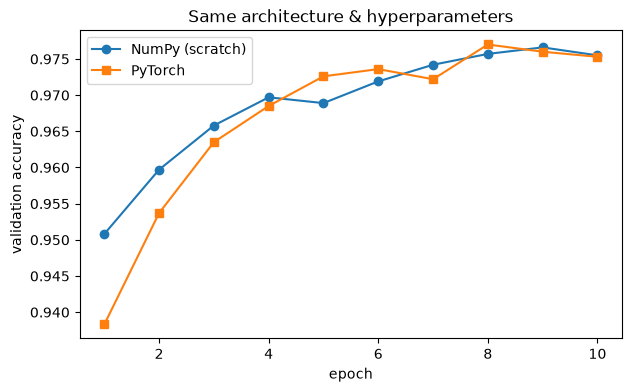

In [149]:
@torch.no_grad()
def predict_proba_torch(
    net: nn.Module, X: np.ndarray, batch_size: int = 10_000
) -> np.ndarray:
    """X (n, 784) → (n, 10) 的類別機率（float64 numpy）。"""
    net.eval()
    out = []
    for s in range(0, len(X), batch_size):
        xb = torch.as_tensor(X[s : s + batch_size], dtype=torch.float32, device=device)
        logits = net(xb).cpu().double()  # MPS 不支援 float64，先搬回 CPU 再轉
        out.append(torch.log_softmax(logits, dim=1).exp().numpy())
    return np.vstack(out)


def train_torch(
    net: nn.Module,
    X_train: np.ndarray,
    y_train: np.ndarray,
    X_val: np.ndarray | None = None,
    y_val: np.ndarray | None = None,
    *,
    lr: float = 0.1,
    batch_size: int = 128,
    n_epochs: int = 10,
    weight_decay: float = 0.0,
    seed: int = 0,
    restore_best: bool = False,
    verbose: bool = True,
) -> dict:
    """mini-batch SGD 訓練 net（就地修改）。

    回傳 history：
    - "train_loss"：每個 epoch 內 batch loss 的平均（同手寫版，「邊訓練邊算」）
    - "val_loss"、"val_acc"：每個 epoch 結束時的 validation 交叉熵與 accuracy
    - "seconds"：每個 epoch 花的秒數
    - "best_epoch"、"best_val_loss"：validation loss 最低的 epoch（從 1 起算）與其值
    restore_best=True：訓練完把權重換回 best_epoch 時的權重（early stopping）。
    """
    g = torch.Generator().manual_seed(seed)  # 打亂順序用的亂數，與初始化分開
    net.to(device)  # 把網路搬進GPU
    Xt = torch.as_tensor(X_train, dtype=torch.float32, device=device)
    yt = torch.as_tensor(y_train, dtype=torch.long, device=device)
    opt = torch.optim.SGD(net.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.CrossEntropyLoss()
    hist: dict = {"train_loss": [], "val_loss": [], "val_acc": [], "seconds": []}
    best_loss, best_epoch, best_state = np.inf, 0, None
    n = len(Xt)

    for epoch in range(n_epochs):
        net.train()
        t0 = time.perf_counter()
        perm = torch.randperm(n, generator=g).to(device)
        total = torch.zeros(
            (), device=device
        )  # 累加在裝置上，避免每個 batch 都 .item()（會強制同步、很慢）
        for start in range(0, n, batch_size):
            idx = perm[start : start + batch_size]
            xb, yb = Xt[idx], yt[idx]
            # TODO 14（程式）：一次更新的四行，對照手寫版的三個階段（3B 的表）
            #   手上的變數：
            #     xb (batch, 784) float32
            #     yb (batch,) long
            #     net（nn.Sequential）
            #     loss_fn（nn.CrossEntropyLoss：吃 logits 與整數標籤，回傳平均交叉熵）
            #     opt（SGD）
            #   1. 清掉上一次的梯度（opt 的方法；為什麼要清見 TODO 15 (2)）
            #   2. forward 並算 loss，存成變數 loss       ← 對應 MLP.forward + loss_fn_.forward
            #   3. 反向傳播：對 loss 呼叫一個方法         ← 對應 MLP.backward，梯度存進每個參數的 .grad
            #   4. 更新參數（opt 的方法）                 ← 對應 MLP.step
            #   常見錯誤：順序不能換（先 step 再 backward，用的是上一個 batch 的梯度）；
            #           net(xb) 輸出的是 logits，不要自己先做 softmax（CrossEntropyLoss 內部會做）
            opt.zero_grad() # 清空梯度
            loss = loss_fn(net(xb), yb)
            loss.backward()
            opt.step()
            total += loss.detach() * len(idx)
        train_loss = total.item() / n
        hist["train_loss"].append(train_loss)
        msg = f"epoch {epoch + 1:2d}  train_loss {train_loss:.4f}"
        if not np.isfinite(train_loss):
            if verbose:
                print(msg + "  → 發散，停止訓練")
            break
        if X_val is not None:
            s = val_scores(predict_proba_torch(net, X_val), y_val)
            hist["val_loss"].append(s["log_loss"])
            hist["val_acc"].append(s["accuracy"])
            msg += f"  val_loss {s['log_loss']:.4f}  val_acc {s['accuracy']:.4f}"
            if s["log_loss"] < best_loss:
                best_loss, best_epoch = s["log_loss"], epoch + 1
                best_state = {
                    k: v.detach().clone() for k, v in net.state_dict().items()
                }
        hist["seconds"].append(time.perf_counter() - t0)
        if verbose:
            print(msg + f"  ({hist['seconds'][-1]:.1f}s)")

    hist["best_epoch"], hist["best_val_loss"] = best_epoch, best_loss
    if restore_best and best_state is not None:
        net.load_state_dict(best_state)
    return hist


set_seed(0)
net_default = make_mlp((256,), "relu")
print("參數量：", count_parameters(net_default))
hist_default = train_torch(
    net_default, X_tr, y_tr, X_va, y_va, lr=0.1, batch_size=128, n_epochs=10
)
val_table.loc["MLP 256 ReLU (PyTorch)"] = val_scores(
    predict_proba_torch(net_default, X_va)
)
display(val_table)
print(
    "✅ PyTorch 版 validation accuracy 應與手寫版相差 < 0.005（初始化與打亂順序不同，不會完全一樣）"
)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, 11), mlp.history_["val_acc"], "o-", label="NumPy (scratch)")
ax.plot(range(1, 11), hist_default["val_acc"], "s-", label="PyTorch")
ax.set_xlabel("epoch")
ax.set_ylabel("validation accuracy")
ax.set_title("Same architecture & hyperparameters")
ax.legend()
plt.show()

### TODO 15（問答）

> **(1)** autograd 做了什麼？
>
> **(a)** 3B 的手寫版，每一層在 `forward` 時存了什麼（`Linear` 存 `X`、`ReLU` 存 `mask`……）？為什麼一定要存？
>
> **(b)** PyTorch 沒有要我們寫 backward。它在 forward 時記錄了什麼，才能在 `loss.backward()` 時倒著算回來？（提示：每個運算的輸出 tensor 都有一個 `grad_fn`；試試 `print(logits_t.grad_fn, logits_t.grad_fn.next_functions)`）
>
> **(c)** 用一句話對照：`MLP.backward` 的那個 for 迴圈 ↔ PyTorch 的哪個呼叫？`Linear.backward` 裡的三行公式 ↔ PyTorch 裡的什麼？

(a) 每一層存了 forward 後的輸出，這個輸出在反向傳播的時候會用到

**修正**：存的不一定是「輸出」，而是「backward 算局部導數時需要的東西」，每一層不同：

| 層 | 存什麼 | 為什麼 |
| --- | --- | --- |
| `Linear` | **輸入** `self.X` | $\partial L/\partial W = X^\top\cdot\text{dout}$ 需要輸入 $X$ |
| `ReLU` | `self.mask = X > 0`（由**輸入**算出） | 導數取決於輸入的正負 |
| `Sigmoid`、`Tanh` | **輸出** `self.out` | 導數可以用輸出表示（$\sigma(1-\sigma)$、$1-\tanh^2$） |

為什麼一定要存：局部導數的數值取決於 forward 時的值，backward 是在 forward **之後**才執行的；不存就得重新算一次 forward（或根本拿不到）。

(b) 他在 forward 的時候紀錄了 forward(X)

**補充**：PyTorch 記錄的是一張**計算圖**（computational graph）：

- 每做一次運算（矩陣乘法、加 bias、ReLU……），輸出的 tensor 就帶著一個 `grad_fn`：指向「這個運算的 backward 函數」，例如 `AddmmBackward0`（矩陣乘法＋加 bias）、`ReluBackward0`。
- `grad_fn.next_functions` 指向產生它的輸入的那些運算 —— 一路串回最前面的參數，形成一張圖。
- 每個 `grad_fn` 也存了自己 backward 需要的 tensor（`ReluBackward0` 存 ReLU 的結果、`AddmmBackward0` 存輸入與權重）—— 這就是 PyTorch 版的 cache，對應 (a) 的表。
- 試試 `print(logits_t.grad_fn, logits_t.grad_fn.next_functions)`，可以看到 `AddmmBackward0` 後面接著 `ReluBackward0`。

(c) MLP.backward 的迴圈等於 pytorch 裡面的 loss.backward()；Linear.backward 裡面的三行等同 opt.step()

- 第一句 ✓：`loss.backward()` 沿計算圖從 loss 倒著走過每個 `grad_fn`，就是 `MLP.backward` 的 for 迴圈。
- **修正**第二句：`Linear.backward` 的三行公式對應的是 **`AddmmBackward0` 這類運算的 backward 函數**（PyTorch 內建的局部導數公式，在 `loss.backward()` 執行過程中被呼叫）。`opt.step()` 對應的是 **`MLP.step()`**（用梯度更新參數），不是 backward。

| 手寫 | PyTorch |
| --- | --- |
| `MLP.backward` 的 for 迴圈 | `loss.backward()`（沿計算圖倒著走） |
| `Linear.backward` 的三行公式 | 各運算的 `grad_fn`（如 `AddmmBackward0`）的內建導數公式 |
| `MLP.step()` | `opt.step()` |
| 每次 `loss_and_grads` 覆寫 `grads` | 需要自己 `opt.zero_grad()`（因為 `.grad` 會累加，見 (2)） |

> **(2)** 為什麼每次更新前要 `opt.zero_grad()`？
>
> **(a)** 實驗：在新的一格執行下面的程式（不清梯度、連續 backward 兩次），`dW` 會變成原來的幾倍？
>
> ```python
> net64.zero_grad()
> for _ in range(2):
>     loss = nn.functional.cross_entropy(net64(torch.from_numpy(Xb)), torch.from_numpy(yb))
>     loss.backward()                     # 每次重新 forward，才有新的計算圖可以 backward
> print(np.linalg.norm(net64[0].weight.grad.numpy()) / np.linalg.norm(mlp64.linears_[0].grads["W"]))  # 梯度大小的比值
> ```
>
> （注意：同一個 `loss` 不能 backward 兩次 —— PyTorch 預設在 backward 後釋放計算圖以節省記憶體，第二次會報錯；要重新 forward，或第一次用 `backward(retain_graph=True)`。）
>
> **(b)** PyTorch 對 `.grad` 的預設行為是「累加」而不是「覆蓋」。用 3A 推導小技巧 3（同一個參數被用好幾次，梯度相加）說明為什麼 autograd 必須這樣設計。
>
> **(c)** 累加的行為有什麼實際用途？（提示：GPU 記憶體只放得下 batch 32，但想要 batch 128 的效果）

(a) 程式碼裡面沒找到 loss_t.backward()

**修正與說明**：`loss_t.backward()` 在第 4 節第一格（「核對」那格）的倒數幾行。但原本的題目有問題：同一個 `loss_t` 不能 backward 兩次（計算圖在第一次 backward 後就被釋放，第二次會報錯）—— 題目已改成每次重新 forward 的版本。答案：不清梯度、backward 兩次後，`dW` 變成原來的 **2 倍**（印出的比值是 2.0），因為第二次的梯度被**加**到第一次的上面。

(b) 梯度用累加的話，訓練越多次應該梯度會增加越快，避免學習太慢以及梯度消失的問題

**修正**：累加不是為了讓學習變快。真正的原因：

- **一個參數可能在計算圖裡被用到好幾次**（3A 推導小技巧 3、前置複習的多變數鏈鎖律）：例如 RNN 在每個時間步都用同一個 $W$、同一個 tensor 在 forward 裡被用了兩次。這時 $\partial L/\partial W$ 是**每一條路徑的貢獻相加**。autograd 沿圖往回走時，每條路徑的梯度抵達這個參數，就**加進** `.grad`；如果是「覆蓋」，就只會留下最後一條路徑，梯度是錯的。
- 代價：`.grad` 不會在每個 batch 自動歸零。不呼叫 `zero_grad()` 的話，這個 batch 的梯度會加上之前所有 batch 的梯度 —— 方向混進舊的、過時的梯度，大小也越來越大（等於學習率不斷變大），訓練會變得不穩定甚至發散，不是「學得更快」。所以每次更新前一定要 `opt.zero_grad()`。

(c) 同 (b) 一樣

**補寫**：實際用途是 **gradient accumulation**（梯度累積），用小 batch 模擬大 batch：

- GPU 記憶體只放得下 batch 32，但想要 batch 128 的梯度：連續做 4 次 forward + backward（每次 batch 32，loss 除以 4），**中間不清梯度**，讓 4 次的梯度累加在 `.grad` 裡，最後才 `opt.step()` 一次、`opt.zero_grad()` 一次。
- 結果等於 batch 128 的平均梯度（loss 除以 4，是因為每個 loss 本身已經是 32 筆的平均）。訓練大模型時常用這招。

> **(3)** 同樣的結構與超參數，PyTorch 版和手寫版的 validation accuracy 很接近但不完全一樣。列出至少兩個原因。（提示：看 PyTorch `nn.Linear` 的預設初始化，它的標準差跟 He 比起來如何？）

batch 的時候對於資料的分割不同應該是會導致結果略有差異，源碼裡面 nn.Linear 初始化的時候用了 kaiming uniform 做初始化

✓ 兩個原因都對，補充精確說法：

1. **初始化不同**：`nn.Linear` 用 `kaiming_uniform_(a=√5)`，實際效果是從 $U\big(-\tfrac{1}{\sqrt{\text{fan}_{\text{in}}}}, \tfrac{1}{\sqrt{\text{fan}_{\text{in}}}}\big)$ 抽樣，標準差 $= \dfrac{1}{\sqrt{3\,\text{fan}_{\text{in}}}} \approx \dfrac{0.58}{\sqrt{\text{fan}_{\text{in}}}}$；我們的 He 是 $\sqrt{2/\text{fan}_{\text{in}}} \approx \dfrac{1.41}{\sqrt{\text{fan}_{\text{in}}}}$ —— PyTorch 預設大約**小 2.4 倍**。bias 也不同：PyTorch 用同樣範圍的均勻分布，我們初始化成 0。（名字雖然叫 kaiming，參數 `a=√5` 讓它其實不是 He 初始化。）
2. **打亂順序不同**（「資料的分割不同」的精確說法）：手寫版用 NumPy 的 `rng.permutation`、PyTorch 版用 `torch.randperm`，即使 seed 相同，兩邊的亂數產生器不同 → 每個 batch 裡是哪些樣本不同 → 每一步的梯度不同。
3. **浮點數運算細節**：都是 float32，但 PyTorch 在 MPS（GPU）上、NumPy 在 CPU 上，加法的順序不同，捨入誤差不同；這些微小差異經過幾千步訓練會被放大。

實測：手寫版 0.9755、PyTorch 版 0.9753 —— 差 0.0002，遠小於 TODO 2 (1) 算的 validation 標準誤（約 0.0015），兩者其實分不出優劣。

---
## 5. 調參

全程只用 train／validation（測試集鎖住），依 README「調參流程」。MLP 的超參數：

| 類別 | 超參數 | 本節怎麼處理 |
| --- | --- | --- |
| 容量 | 隱藏層寬度、層數 | 5A：寬度的 validation curve（層數在 3C 實驗 2 看過） |
| 容量／正則化 | **訓練多少個 epoch** | 5B：early stopping —— 訓練越久，有效容量越大 |
| 正則化 | `weight_decay` | 5C：與學習率做 2D 搜尋 |
| 最佳化 | `lr`、`batch_size` | 5C 搜尋 lr；batch 固定 128（3C 實驗 4） |

**與第一章不同**：

- 不用 `GridSearchCV`：每個設定直接在固定的 validation set 上評估（TODO 2 (1)）。
- 「平均 ± 標準差」的來源從 fold 換成 **seed**：同一個設定換不同的初始化與打亂順序，分數也會變。比較兩個設定前，先知道 seed 造成的雜訊有多大。
- **選模型用 validation loss**（交叉熵），accuracy 一起列出來參考（第一章第三節 TODO 17 (1)：accuracy 只看猜對沒有、不看信心，解析度粗、不同設定常常平手；交叉熵會反映機率的信心，比較得出差異）。

整節在 M4 Pro（MPS）上約 5–10 分鐘。

,params,train_loss,val_loss,train_acc,val_acc,best_epoch,best_val_loss,sec/epoch
width,,,,,,,,
16,12730,0.1181,0.1761,0.9643,0.9494,15,0.1761,0.2533
32,25450,0.0601,0.1291,0.9814,0.9633,13,0.1205,0.2634
64,50890,0.0299,0.0924,0.9939,0.9731,12,0.0888,0.2480
128,101770,0.0190,0.0799,0.9969,0.9770,11,0.0799,0.2502
256,203530,0.0167,0.0759,0.9978,0.9783,14,0.0756,0.2477
512,407050,0.0129,0.0700,0.9990,0.9805,15,0.0700,0.2592
1024,814090,0.0110,0.0694,0.9992,0.9803,15,0.0694,0.2828


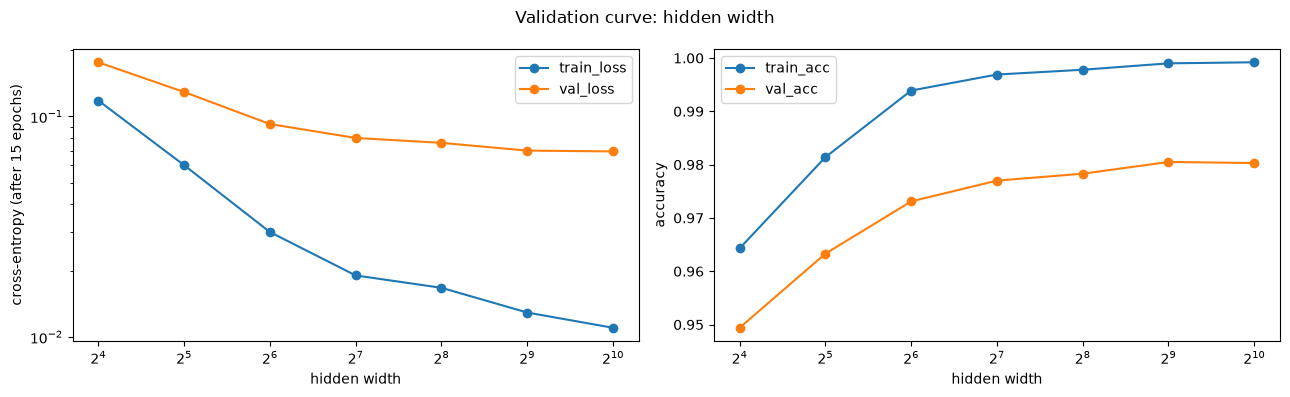

In [150]:
# 5A. 隱藏層寬度的 validation curve（一層隱藏層、lr = 0.1、15 epochs）
X_tr_eval, y_tr_eval = (
    X_tr[:10_000],
    y_tr[:10_000],
)  # 訓練集分數用其中 10,000 筆估計，省時間
width_rows = []
for width in [16, 32, 64, 128, 256, 512, 1024]:
    set_seed(0)
    net = make_mlp((width,), "relu")
    h = train_torch(net, X_tr, y_tr, X_va, y_va, lr=0.1, n_epochs=15, verbose=False)
    tr = val_scores(predict_proba_torch(net, X_tr_eval), y_tr_eval)
    width_rows.append(
        {
            "width": width,
            "params": count_parameters(net),
            "train_loss": tr["log_loss"],
            "val_loss": h["val_loss"][-1],
            "train_acc": tr["accuracy"],
            "val_acc": h["val_acc"][-1],
            "best_epoch": h["best_epoch"],
            "best_val_loss": h["best_val_loss"],
            "sec/epoch": np.mean(h["seconds"]),
        }
    )
width_df = pd.DataFrame(width_rows).set_index("width")
display(width_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for col in ["train_loss", "val_loss"]:
    axes[0].plot(width_df.index, width_df[col], "o-", label=col)
axes[0].set_yscale("log")
axes[0].set_ylabel("cross-entropy (after 15 epochs)")
for col in ["train_acc", "val_acc"]:
    axes[1].plot(width_df.index, width_df[col], "o-", label=col)
axes[1].set_ylabel("accuracy")
for ax in axes:
    ax.set_xscale("log", base=2)
    ax.set_xlabel("hidden width")
    ax.legend()
fig.suptitle("Validation curve: hidden width")
fig.tight_layout()
plt.show()

val loss 最低在第 15 個 epoch：0.0694；第 40 個 epoch：0.0743
val acc：最低 val loss 那個 epoch = 0.9803；第 40 個 epoch = 0.9811；最高 = 0.9811


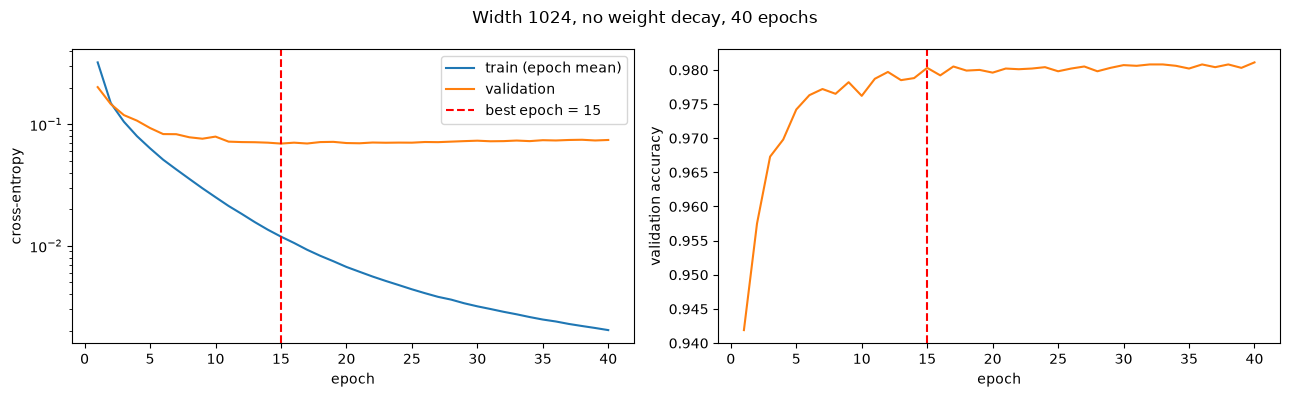

In [151]:
# 5B. 訓練久一點會怎樣？寬度 1024、不加 weight decay、40 epochs
set_seed(0)
net_long = make_mlp((1024,), "relu")
hist_long = train_torch(net_long, X_tr, y_tr, X_va, y_va, lr=0.1, n_epochs=40, verbose=False)
print(f"val loss 最低在第 {hist_long['best_epoch']} 個 epoch：{hist_long['best_val_loss']:.4f}；"
      f"第 40 個 epoch：{hist_long['val_loss'][-1]:.4f}")
print(f"val acc：最低 val loss 那個 epoch = {hist_long['val_acc'][hist_long['best_epoch'] - 1]:.4f}；"
      f"第 40 個 epoch = {hist_long['val_acc'][-1]:.4f}；最高 = {max(hist_long['val_acc']):.4f}")

ep = np.arange(1, len(hist_long["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(ep, hist_long["train_loss"], label="train (epoch mean)")
axes[0].plot(ep, hist_long["val_loss"], label="validation")
axes[0].axvline(hist_long["best_epoch"], color="r", ls="--", label=f"best epoch = {hist_long['best_epoch']}")
axes[0].set_yscale("log")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("cross-entropy")
axes[0].legend()
axes[1].plot(ep, hist_long["val_acc"], color="C1")
axes[1].axvline(hist_long["best_epoch"], color="r", ls="--")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("validation accuracy")
fig.suptitle("Width 1024, no weight decay, 40 epochs")
fig.tight_layout()
plt.show()

### TODO 16（問答）容量：寬度與訓練時間

> **(1)** 寬度的 validation curve（5A）。
>
> **(a)** 讀表格：寬度 16 → 1024，train loss 和 val loss 各怎麼變？val accuracy 從多少到多少？參數量從多少到多少？
>
> **(b)** 第一章的 validation curve（例如 KNN 的 $k$、決策樹深度）在容量大到某個程度後 val 會「反轉變差」。這裡寬度變大，val 有明顯變差嗎？
>
> **(c)** 寬度 1024 的參數量比訓練樣本數（50,000）還多很多，照第一章的直覺應該嚴重過擬合。從表格看，train 與 val 的差距（val loss − train loss，以及 train acc − val acc）在寬度 16 和 1024 時各是多少？差距有隨寬度明顯變大嗎？（提示：只訓練了 15 個 epoch、用的是 SGD。這個現象跟「SGD 本身就帶有隱式正則化」與「過參數化」有關，列入待補強，不必展開）

(a) train loss 與 val_loss 都在下降，但是 val loss 逐漸平緩，train loss 還在一直下降；train acc 與 val acc 都在上升，但是都會進入平台期；參數量從 12730 到 814090

✓。數字（寬度 16 → 1024）：train loss 0.118 → 0.011、val loss 0.176 → 0.069；train acc 0.964 → 0.999、val acc 0.949 → 0.980（512 之後持平：0.9805 vs 0.9803）；參數量 12,730 → 814,090（64 倍）。

(b) 沒有明顯變差，但也沒有變得更好

✓。精確一點：寬度 16 → 512 是**一路變好**（val acc +3.1 個百分點），512 → 1024 才持平（val loss 0.0700 vs 0.0694，差距在雜訊範圍內）。與第一章不同的是：容量變大後 val **沒有反轉變差**。

(c) 不清楚你的問題，你說的差距是指 acc 還是 loss

**補寫**（題目已改寫清楚，兩種差距都看）：

| 寬度 | 參數量 | val loss − train loss | train acc − val acc |
| --- | --- | --- | --- |
| 16 | 12,730 | 0.176 − 0.118 = **0.058** | 0.964 − 0.949 = **1.5** 個百分點 |
| 1024 | 814,090 | 0.069 − 0.011 = **0.058** | 0.999 − 0.980 = **1.9** 個百分點 |

- 參數量增加 64 倍，loss 的差距幾乎沒變、acc 的差距只多 0.4 個百分點，而 val 本身還變好了 → **沒有嚴重過擬合**。
- 第一章的直覺（參數比資料多 → 一定過擬合）在這裡不成立，原因（列入待補強，不在這裡展開）：
  - **只訓練 15 個 epoch**：模型還沒有把訓練集「背」到極致（(2) 會看到訓練更久時 val loss 確實開始上升）。
  - **SGD 本身帶有隱式正則化**：從小的初始權重出發、帶雜訊的小步更新，傾向找到比較「平滑」的解，而不是剛好穿過每個訓練點的複雜解。
  - **過參數化**：現代神經網路常常參數遠多於資料卻推廣得很好（double descent 現象）。

> **(2)** 訓練時間也是容量（5B）。
>
> **(a)** train loss 在 40 個 epoch 內怎麼變？val loss 呢？最低點在第幾個 epoch？
>
> **(b)** val loss 在最低點之後開始上升，但 val accuracy 幾乎沒變差（甚至還在微升）。這兩者怎麼可能同時發生？（對照第一章第三節 TODO 15 (2)：C 很大時 log loss 被少數「很有把握地錯」主導）
>
> **(c)** **early stopping**：在 val loss 最低時停下來、用那時的權重。為什麼「少訓練幾個 epoch」可以看成一種正則化？（提示：從小的初始權重出發，訓練越久，$\|W\|$ 通常越大；對照 L2 限制 $\|w\|$）
>
> **(d)** 用 val loss 決定停在哪個 epoch，是在「用 validation 做決定」。(i) 那 early stopping 選出的 epoch 數（這裡是 15），跟學習率、寬度一樣算是「超參數」嗎？(ii) 最後報告模型成績時，可以直接報「第 15 個 epoch 的 val loss 0.0694」嗎？為什麼？（提示：0.0694 是從 40 個 epoch 中挑出「最低」的那一個；README 的資料切分原則）

(a) train loss 在 40 個 epochs 裡面一直下降，val loss 則大約 10～15 個 epoch 後就一直維持，最低點應該是在第 15 個 epoch

✓。val loss 最低在第 15 個 epoch（0.0694），之後慢慢上升，到第 40 個 epoch 是 0.0743；train loss 則一路下降。

(b) acc 差不多，但是輸出錯誤的機率如果很接近 1，那 loss 就不會有很劇烈的增加

**修正**：方向對（accuracy 和 loss 看的東西不同），但效果說反了：

- 交叉熵每一筆的 loss 是 $-\log p_{\text{正確類別}}$。模型對某筆**錯誤**的答案越有把握（給錯的類別機率接近 1 → 給正確類別的機率接近 0），這一筆的 loss 就**越大**，而且沒有上限（$-\log 0.001 \approx 6.9$、$-\log 10^{-6} \approx 13.8$）。
- 訓練越久，模型對**所有**預測都越來越有把握：猜對的那些，loss 再小一點點（本來就接近 0，降不了多少）；猜錯的那少數幾筆，loss 大幅上升。val loss 被這幾筆「很有把握地錯」主導而上升。
- accuracy 只看猜對沒有：那幾筆本來就是錯的，變得更有把握地錯，accuracy 不變；所以 val acc 持平（甚至微升到 0.9811），val loss 卻上升。
- 與第一章第三節 TODO 15 (2) 同一件事：C 很大（正則化弱）時，log loss 被少數有把握地錯的樣本主導。

(c) 多訓練的話 W 通常越大，作為懲罰項的一部分 W 越大懲罰就會越重

**修正**：5B 沒有加任何懲罰項（`weight_decay = 0`），所以不是「懲罰變重」。early stopping 的作用是**限制 $W$ 能長多大**：

- 從很小的初始權重出發，每一步 SGD 都在改 $W$；訓練越久，$W$ 離初始值越遠、$\|W\|$ 通常越大，模型輸出的機率也越極端（越有把握）。
- 在第 $t$ 個 epoch 停下來，等於限制「$W$ 最多只能離初始值走這麼遠」—— 跟 L2 正則化限制 $\|W\|$ 的效果類似，只是 L2 是在 loss 裡加懲罰項，early stopping 是直接不讓它繼續走。
- 所以訓練的 epoch 數本身就是一種「容量」：訓練越久，有效容量越大。（對線性模型可以證明：梯度下降早停，大致等價於 L2 正則化、強度約與 $1/(\text{lr}\cdot t)$ 成正比；列入待補強。）

(d) 不清楚問題

**補寫**（題目已改寫清楚）：

- **(i) 是超參數**：epoch 數是「看 validation 的結果才決定」的設定，跟學習率、寬度一樣。所以第 6 節在完整訓練集 refit 時，直接用這個選出來的 epoch 數（`best_epoch`）。
- **(ii) 不能直接報 val loss 0.0694 當最終成績**：
  - 0.0694 是從 40 個 epoch 的 val loss 中**挑最低的那一個**。就算每個 epoch 的真實表現都一樣，40 個帶雜訊的數字取最小值也會偏低 → 這個數字**偏樂觀**。
  - README 資料切分原則：只要根據某組資料的分數做過選擇，它就不再是公正的評估。validation 已經用來選 epoch、選寬度、選學習率了。
  - 最終成績要用**從來沒參與任何決定**的測試集，而且只看一次（第 6 節）。

lr=0.03  wd=0.0     best_epoch=20  best_val_loss=0.0870  val_acc@best=0.9755
lr=0.03  wd=0.0001  best_epoch=20  best_val_loss=0.0874  val_acc@best=0.9756
lr=0.03  wd=0.001   best_epoch=20  best_val_loss=0.0919  val_acc@best=0.9747
lr=0.1   wd=0.0     best_epoch=15  best_val_loss=0.0700  val_acc@best=0.9805
lr=0.1   wd=0.0001  best_epoch=15  best_val_loss=0.0699  val_acc@best=0.9800
lr=0.1   wd=0.001   best_epoch=17  best_val_loss=0.0714  val_acc@best=0.9807
lr=0.3   wd=0.0     best_epoch=11  best_val_loss=0.0709  val_acc@best=0.9824
lr=0.3   wd=0.0001  best_epoch=15  best_val_loss=0.0668  val_acc@best=0.9827
lr=0.3   wd=0.001   best_epoch=11  best_val_loss=0.0670  val_acc@best=0.9812


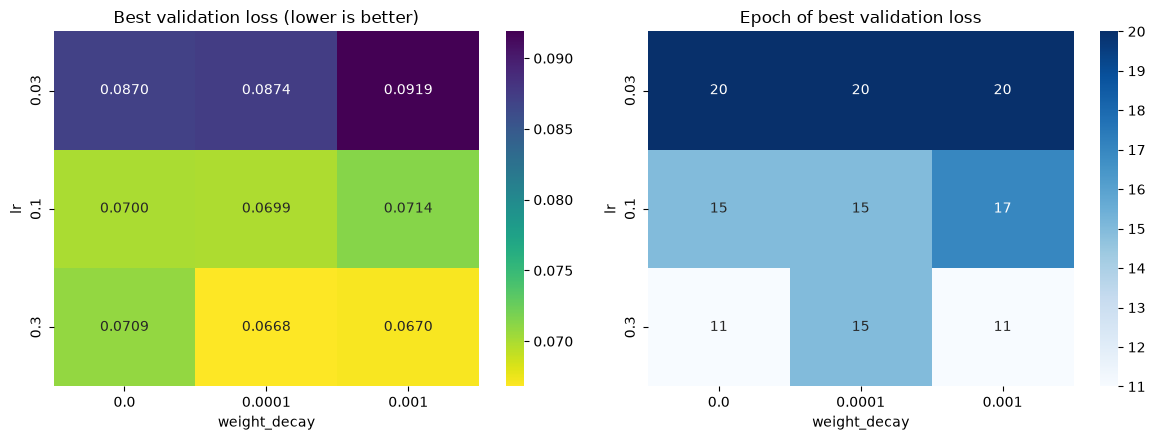

最佳設定： {'lr': 0.3, 'weight_decay': 0.0001, 'best_epoch': 15.0, 'best_val_loss': 0.0668, 'val_acc@best': 0.9827, 'val_loss@20': 0.0681}


In [152]:
# 5C. 2D 搜尋：lr × weight_decay（寬度 512、20 epochs，各設定取 val loss 最低的 epoch）
WIDTH, MAX_EPOCHS = 512, 20
grid_rows = []
for lr in [0.03, 0.1, 0.3]:
    for wd in [0.0, 1e-4, 1e-3]:
        set_seed(0)
        net = make_mlp((WIDTH,), "relu")
        h = train_torch(
            net,
            X_tr,
            y_tr,
            X_va,
            y_va,
            lr=lr,
            weight_decay=wd,
            n_epochs=MAX_EPOCHS,
            verbose=False,
        )
        be = h["best_epoch"]
        grid_rows.append(
            {
                "lr": lr,
                "weight_decay": wd,
                "best_epoch": be,
                "best_val_loss": h["best_val_loss"],
                "val_acc@best": h["val_acc"][be - 1],
                "val_loss@20": h["val_loss"][-1],
            }
        )
        print(
            f"lr={lr:<5} wd={wd:<7} best_epoch={be:2d}  best_val_loss={h['best_val_loss']:.4f}  "
            f"val_acc@best={h['val_acc'][be - 1]:.4f}"
        )
grid = pd.DataFrame(grid_rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.heatmap(
    grid.pivot(index="lr", columns="weight_decay", values="best_val_loss"),
    annot=True,
    fmt=".4f",
    cmap="viridis_r",
    ax=axes[0],
)
axes[0].set_title("Best validation loss (lower is better)")
sns.heatmap(
    grid.pivot(index="lr", columns="weight_decay", values="best_epoch"),
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[1],
)
axes[1].set_title("Epoch of best validation loss")
fig.tight_layout()
plt.show()

best_cfg = grid.loc[grid["best_val_loss"].idxmin()]
print("最佳設定：", best_cfg.to_dict())

In [153]:
# seed 造成的雜訊：最佳設定換 3 個 seed 重跑
seed_rows = []
for seed in [0, 1, 2]:
    set_seed(seed)
    net = make_mlp((WIDTH,), "relu")
    h = train_torch(
        net,
        X_tr,
        y_tr,
        X_va,
        y_va,
        lr=float(best_cfg["lr"]),
        weight_decay=float(best_cfg["weight_decay"]),
        n_epochs=MAX_EPOCHS,
        seed=seed,
        verbose=False,
    )
    seed_rows.append(
        {
            "seed": seed,
            "best_epoch": h["best_epoch"],
            "best_val_loss": h["best_val_loss"],
            "val_acc@best": h["val_acc"][h["best_epoch"] - 1],
        }
    )
seeds_df = pd.DataFrame(seed_rows).set_index("seed")
display(seeds_df)
print("平均 ± 標準差：")
display(seeds_df.agg(["mean", "std"]).round(4))

,best_epoch,best_val_loss,val_acc@best
seed,,,
0,15,0.0668,0.9827
1,11,0.0657,0.9819
2,9,0.0659,0.9815


平均 ± 標準差：


,best_epoch,best_val_loss,val_acc@best
mean,11.6667,0.0661,0.9820
std,3.0551,0.0006,0.0006


,epochs,train_loss,val_loss,train_acc,val_acc
train_size,,,,,
1000,978,0.0375,0.3629,0.9980,0.8938
3000,326,0.0543,0.2473,0.9900,0.9269
10000,99,0.0170,0.1432,0.9989,0.9585
25000,40,0.0073,0.0930,0.9996,0.9753
50000,20,0.0028,0.0668,1.0000,0.9827


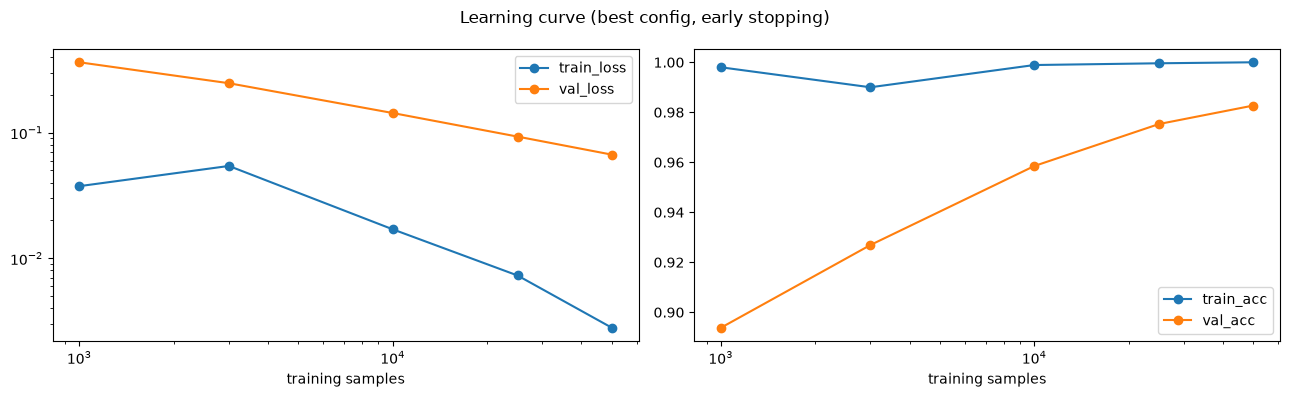

In [154]:
# 5D. 學習曲線：最佳設定，訓練資料取 1,000 ～ 50,000 筆
# 小資料集的 epoch 很短，所以固定「總更新次數」（≈ 20 epochs × 391 次），而不是固定 epoch 數
budget = MAX_EPOCHS * int(np.ceil(len(X_tr) / 128))
lc_rows = []
for size in [1_000, 3_000, 10_000, 25_000, 50_000]:
    epochs = int(np.ceil(budget / np.ceil(size / 128)))
    set_seed(0)
    net = make_mlp((WIDTH,), "relu")
    h = train_torch(
        net,
        X_tr[:size],
        y_tr[:size],
        X_va,
        y_va,
        lr=float(best_cfg["lr"]),
        weight_decay=float(best_cfg["weight_decay"]),
        n_epochs=epochs,
        restore_best=True,
        verbose=False,
    )
    tr = val_scores(
        predict_proba_torch(net, X_tr[: min(size, 10_000)]), y_tr[: min(size, 10_000)]
    )
    lc_rows.append(
        {
            "train_size": size,
            "epochs": epochs,
            "train_loss": tr["log_loss"],
            "val_loss": h["best_val_loss"],
            "train_acc": tr["accuracy"],
            "val_acc": h["val_acc"][h["best_epoch"] - 1],
        }
    )
lc = pd.DataFrame(lc_rows).set_index("train_size")
display(lc.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for col in ["train_loss", "val_loss"]:
    axes[0].plot(lc.index, lc[col], "o-", label=col)
axes[0].set_yscale("log")
for col in ["train_acc", "val_acc"]:
    axes[1].plot(lc.index, lc[col], "o-", label=col)
for ax in axes:
    ax.set_xscale("log")
    ax.set_xlabel("training samples")
    ax.legend()
fig.suptitle("Learning curve (best config, early stopping)")
fig.tight_layout()
plt.show()

### TODO 17（問答）搜尋、seed 雜訊、學習曲線

> **(1)** 2D 搜尋（5C）。
>
> **(a)** 讀 heatmap：哪個設定的 best val loss 最低？weight decay = 1e-3 時，best epoch 比不加 weight decay 時早還是晚？
>
> **(b)** 學習率和最佳 epoch 數有什麼關係？為什麼？（提示：lr 小，每一步走得少）
>
> **(c)** 讀 seed 那格：同一個設定換 3 個 seed，best val loss 的**標準差**（表格 `std` 那一列）是多少？這個標準差代表「只換亂數、設定完全不變」時分數會晃動多少。heatmap 裡排名前幾的設定彼此之間的差距，有大於這個標準差嗎？依 README 的 one-standard-error rule（與最佳差距小於一個標準差的候選中，選最簡單的），該怎麼選？

(a) weight_decay = 0.0001、lr = 0.3 的時候 val loss 最低；比較晚

- 最佳設定 ✓：lr = 0.3、weight_decay = 1e-4，best val loss 0.0668。
- **修正**「比較晚」：看 best epoch 那張 heatmap，weight decay = 1e-3 與不加相比 —— lr = 0.1 時是 17 vs 15（晚）、lr = 0.3 時是 11 vs 11（一樣）、lr = 0.03 時都是 20（見 (b)）。**沒有一致的方向**：在這個範圍內，weight decay 對最佳 epoch 的影響很小，比 seed 造成的波動（下面 (c)：同一設定的 best epoch 在 9～15 之間跳動）還小。題目原本預期「weight decay 讓最佳 epoch 提早」，這份資料沒有呈現出來。

(b) 學習率較小，走到最佳的 epochs 的數目要比較多，因為要更新比較多次才會到

✓。lr = 0.03 → 20、lr = 0.1 → 15～17、lr = 0.3 → 11～15。

**補充一個要注意的地方**：lr = 0.03 的三個設定 best epoch 全部是 **20 = 最大 epoch 數**，代表 val loss 到最後一個 epoch 都還在下降 —— 它不是「最佳在第 20 個 epoch」，而是「還沒走到最佳就被截斷了」。所以 lr = 0.03 的 best val loss（0.087）低估了它的潛力，跟其他學習率比較並不公平。搜尋時如果最佳值落在範圍的**邊界**（epoch 上限、網格的最大或最小值），就表示範圍不夠，應該把範圍再往外延伸。

(c) 換了 seed 後 best val loss 為 0.0657，heatmap 裡面最好的 val loss 為 0.0668，差距大約 0.0011，你是說大於哪個標準差？

**補寫**（題目已改寫清楚）：

- 0.0657 和 0.0668 是**同一個設定**換不同 seed 的結果，這 0.0011 的差距本身就是 seed 造成的雜訊。題目要的標準差是 seed 表格 `std` 那一列：3 個 seed 的 best val loss 是 0.0668、0.0657、0.0659 → **標準差 0.0006**。意思是：設定完全不變、只換亂數，分數大約會晃動 ±0.0006。（只有 3 個 seed，這個標準差本身也只是粗略估計。）
- heatmap 前幾名與最佳（0.0668）的差距：

| 設定 | best val loss | 與最佳的差距 | 跟 seed 標準差 0.0006 比 |
| --- | --- | --- | --- |
| lr 0.3、wd 1e-4（最佳） | 0.0668 | — | — |
| lr 0.3、wd 1e-3 | 0.0670 | 0.0002 | **小於** 1 個標準差 → 分不出優劣 |
| lr 0.1、wd 1e-4 | 0.0699 | 0.0031 | 約 5 個標準差 → 真的比較差 |
| lr 0.3、wd 0 | 0.0709 | 0.0041 | 約 7 個標準差 → 真的比較差 |

- **one-standard-error rule**：在「與最佳差距小於 1 個標準差」的候選中（門檻 0.0668 + 0.0006 = 0.0674，只有 wd 1e-4 和 wd 1e-3 兩個），選**最簡單**的。weight decay 越大 = 正則化越強 = 模型越簡單 → 選 **lr 0.3、wd 1e-3**。
- 結論：學習率 0.3 比 0.1 好是真的（差距遠大於雜訊）；但 wd 1e-4 和 1e-3 之間的差異只是雜訊，不能說 1e-4「比較好」。第 6 節程式直接用 validation 最佳（wd 1e-4），依 1-SE rule 改用 1e-3 也一樣合理。

> **(2)** 學習曲線（5D）。
>
> **(a)** 讀表格：1,000 筆時 val accuracy 多少？50,000 筆時呢？從 25,000 → 50,000 還在進步嗎？
>
> **(b)** 最後一點的 train 與 val 差距大不大？依第一章的判讀方式（train 與 val 差距大 → 過擬合，加資料或加強正則化有幫助；兩者都不夠好、差距小 → 欠擬合，要加模型容量），下一步該「加資料」還是「加模型容量」？
>
> **(c)** 對照第一章 KNN：Digits 只有 1,437 筆就到 98%。MNIST 的 MLP 要多少筆才達到類似的 val accuracy？（兩份資料的解析度與難度不同，只做粗略比較）

(a) 1000 筆的時候 val acc 為 0.89 左右，50000 筆的時候大約可以到 0.98，中間持續進步

✓。

(b) 最後的 train val 的 loss 比一開始大，accuracy 越來越小

**修正與補寫**：這題要看的是「**最後一點**（50,000 筆）train 和 val 之間的差距」，以及「val 是不是還在進步」，再用第一章的規則判斷下一步：

- **典型的形狀**：資料很少時（1,000 筆），模型可以把訓練集幾乎背下來 → train acc 接近 1.0、train loss 很小，val 卻差很多（0.89）→ **差距很大 = 過擬合**。資料越多，越難把每一筆都背下來 → train loss 會**上升**一點、train acc 略降；但模型學到的規則越通用 → val 一路變好 → 兩條線往中間靠攏、差距縮小。你說的「train 的 loss 比一開始大、accuracy 變小」是這個形狀的**一半**（train 那條線），另一半是 val 那條線往上（loss 往下）。
- **判讀**：
  - 25,000 → 50,000 筆，val 仍在進步，而且 train 與 val 之間還有差距 → 目前的瓶頸主要是**資料量（變異／過擬合）**，再加資料還會有幫助。
  - 加模型容量的效果有限：5A 已經看到寬度 512 之後 val 持平。
  - 所以下一步優先「加資料」（MNIST 無法再加真實資料時，可以用**資料增強**：輕微平移、旋轉產生新的訓練影像，第三章 CNN 會做）或加強正則化，而不是把網路做得更大。

（你的 5D 那格存檔時沒有輸出，以上是依你描述的數字與典型形狀判讀；重跑那格可以對照表格裡最後一列的 train／val 數字確認。）

(c) 要到萬筆以上才會達到差不多的 val accuracy

✓。KNN 在 Digits 上 1,437 筆就到 0.98，MLP 在 MNIST 上要上萬筆才到類似水準。兩者不能直接比較，但差距的原因值得記下來：

- **資料本身**：Digits 是 8×8 = 64 個像素、灰階只有 0–16，影像已經被大幅模糊和縮小，寫法差異被抹平很多；MNIST 是 28×28 = 784 個像素，保留了更多寫法細節與變化 → 任務更難，需要更多例子才能涵蓋各種寫法。
- **模型**：MLP 寬度 512 有約 40 萬個參數，要靠資料把它們「定下來」；KNN 沒有參數要學，直接拿訓練樣本比距離，資料少時反而有優勢（但預測時要跟全部訓練資料比，資料一多就很慢）。

---
## 6. 測試集評估

依 README：用最佳超參數在**完整訓練集**（60,000 筆 = train + validation）refit，epoch 數用 5C 找到的 best epoch，測試集只評估一次。
其他模型（Dummy、邏輯回歸、手寫 MLP、PyTorch 預設 MLP）用的是只在 50,000 筆上訓練的版本，當參照點。

,accuracy,precision,recall,f1,roc_auc,log_loss
Dummy prior,0.1135,0.0114,0.1000,0.0204,0.5000,2.3010
Softmax LogReg (sklearn),0.9207,0.9198,0.9194,0.9195,0.9927,0.3112
MLP 256 ReLU (scratch),0.9782,0.9783,0.9780,0.9781,0.9996,0.0752
MLP 256 ReLU (PyTorch),0.9770,0.9772,0.9769,0.9770,0.9996,0.0738
MLP 512 ReLU tuned (PyTorch),0.9843,0.9843,0.9843,0.9843,0.9998,0.0529


,model,accuracy,time,precision,recall,f1,roc_auc,log_loss,params,notes
0,MLP 512 ReLU tuned (PyTorch),0.9843,2026-10-26 23:00,0.9843,0.9843,0.9843,0.9998,0.0529,"{""width"": 512, ""lr"": 0.3, ""weight_decay"": 0.00...",NaN
1,MLP 256 ReLU (scratch),0.9782,2026-10-26 23:00,0.9783,0.9780,0.9781,0.9996,0.0752,"{""hidden"": 256, ""lr"": 0.1, ""epochs"": 10}",NaN
2,MLP 256 ReLU (PyTorch),0.9770,2026-10-26 23:00,0.9772,0.9769,0.9770,0.9996,0.0738,"{""hidden"": 256, ""lr"": 0.1, ""epochs"": 10}",NaN
3,Softmax LogReg (sklearn),0.9207,2026-10-26 23:00,0.9198,0.9194,0.9195,0.9927,0.3112,"{""C"": 1.0}",NaN
4,Dummy prior,0.1135,2026-10-26 23:00,0.0114,0.1000,0.0204,0.5000,2.3010,NaN,NaN


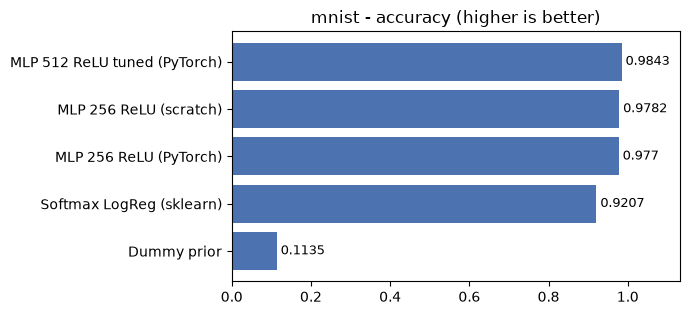

In [155]:
from ml_dl_llm.metrics import classification_metrics
from ml_dl_llm.results import compare, log_result

BENCH = "mnist"
final_params = {
    "width": WIDTH,
    "lr": float(best_cfg["lr"]),
    "weight_decay": float(best_cfg["weight_decay"]),
    "epochs": int(best_cfg["best_epoch"]),
}

set_seed(0)
net_final = make_mlp((WIDTH,), "relu")
train_torch(
    net_final,
    X_full,
    y_full,
    lr=final_params["lr"],
    weight_decay=final_params["weight_decay"],
    n_epochs=final_params["epochs"],
    verbose=False,
)

# 名稱: (測試集機率 (10000, 10), 要記下的參數)
eval_models = {
    "Dummy prior": (dummy.predict_proba(X_test), {}),
    "Softmax LogReg (sklearn)": (softmax_lr.predict_proba(X_test), {"C": 1.0}),
    "MLP 256 ReLU (scratch)": (
        mlp.predict_proba(X_test),
        {"hidden": 256, "lr": mlp.lr, "epochs": mlp.n_epochs},
    ),
    "MLP 256 ReLU (PyTorch)": (
        predict_proba_torch(net_default, X_test),
        {"hidden": 256, "lr": 0.1, "epochs": 10},
    ),
    f"MLP {WIDTH} ReLU tuned (PyTorch)": (
        predict_proba_torch(net_final, X_test),
        final_params,
    ),
}

test_scores = {}
for name, (prob, params) in eval_models.items():
    m = classification_metrics(y_test, prob.argmax(axis=1), prob)
    m["log_loss"] = round(log_loss(y_test, prob, labels=np.arange(10)), 4)
    test_scores[name] = m
    log_result(BENCH, name, m, **params)

display(pd.DataFrame(test_scores).T)
compare(BENCH, "accuracy")

---
## 7. 診斷

看最終模型錯在哪裡：混淆矩陣、最「有把握地錯」的影像、第一層學到的特徵，
最後用一個**打亂像素**的實驗檢查 MLP 到底有沒有用到「影像」的結構。

測試集錯誤：157 / 10000


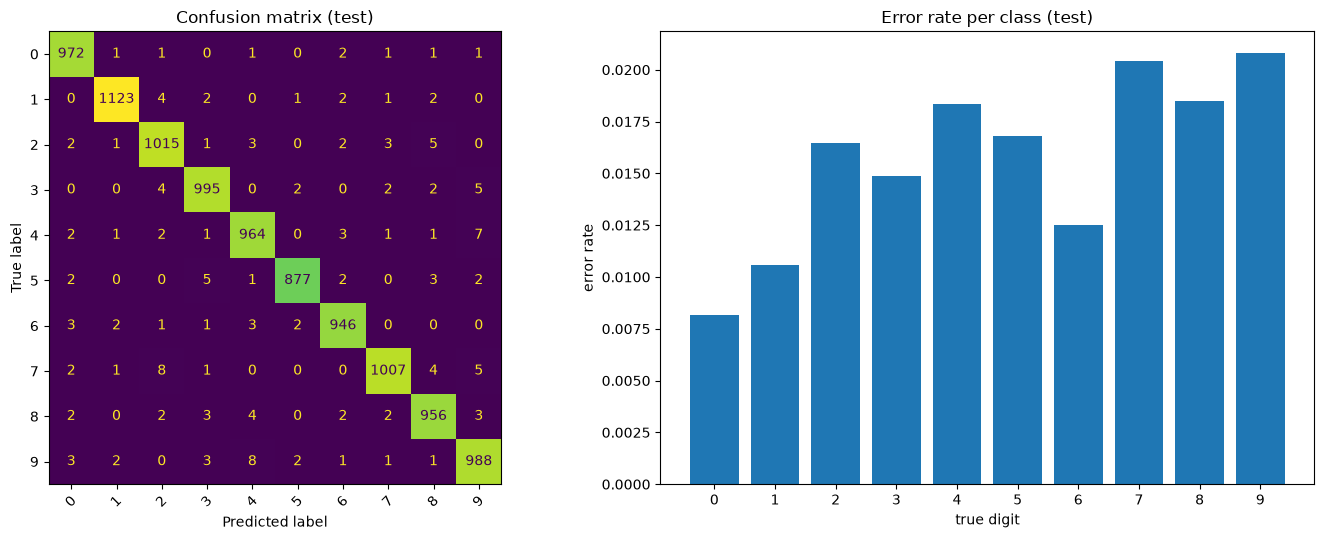

最常見的錯誤（真實, 預測）： {(np.int64(7), np.int64(2)): 8, (np.int64(9), np.int64(4)): 8, (np.int64(4), np.int64(9)): 7, (np.int64(5), np.int64(3)): 5, (np.int64(7), np.int64(9)): 5, (np.int64(2), np.int64(8)): 5}


In [156]:
from ml_dl_llm.metrics import plot_confusion_matrix

prob_te = predict_proba_torch(net_final, X_test)
pred_te = prob_te.argmax(axis=1)
wrong = np.flatnonzero(pred_te != y_test)
print(f"測試集錯誤：{len(wrong)} / {len(y_test)}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
plot_confusion_matrix(y_test, pred_te, ax=axes[0])
axes[0].set_title("Confusion matrix (test)")
per_class = pd.Series([(pred_te[y_test == k] == k).mean() for k in range(10)])
axes[1].bar(range(10), 1 - per_class)
axes[1].set_xticks(range(10))
axes[1].set_xlabel("true digit")
axes[1].set_ylabel("error rate")
axes[1].set_title("Error rate per class (test)")
fig.tight_layout()
plt.show()

pairs = pd.Series(list(zip(y_test[wrong], pred_te[wrong]))).value_counts()
print("最常見的錯誤（真實, 預測）：", pairs.head(6).to_dict())

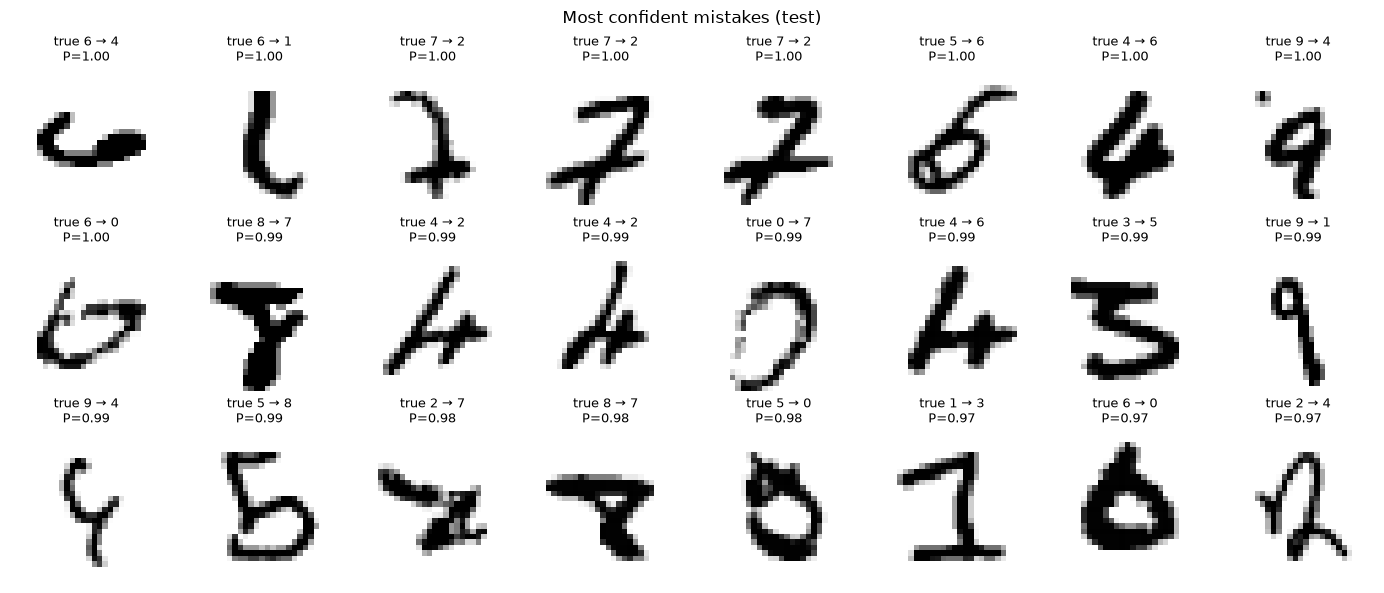

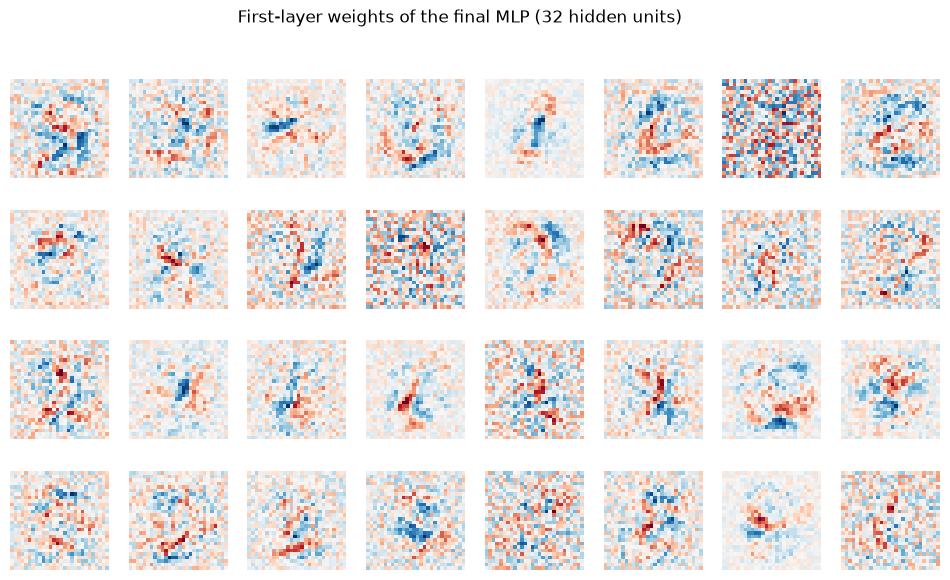

In [157]:
# 最「有把握地錯」的 24 張：模型給錯誤答案的機率最高
conf_wrong = wrong[np.argsort(-prob_te[wrong].max(axis=1))][:24]
fig, axes = plt.subplots(3, 8, figsize=(14, 6))
for ax, i in zip(axes.ravel(), conf_wrong):
    ax.imshow(X_test_u8[i].reshape(28, 28), cmap="gray_r")
    ax.set_title(
        f"true {y_test[i]} → {pred_te[i]}\nP={prob_te[i].max():.2f}", fontsize=9
    )
    ax.axis("off")
fig.suptitle("Most confident mistakes (test)")
fig.tight_layout()
plt.show()

# 第一層學到的權重：前 32 個隱藏單元，每個畫成 28×28
W1_final = net_final[0].weight.detach().cpu().numpy()  # (WIDTH, 784)
fig, axes = plt.subplots(4, 8, figsize=(12, 6.5))
for ax, w in zip(axes.ravel(), W1_final[:32]):
    lim = np.abs(w).max()
    ax.imshow(w.reshape(28, 28), cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.axis("off")
fig.suptitle("First-layer weights of the final MLP (32 hidden units)")
plt.show()

原始像素  ：val_acc = 0.9827  val_loss = 0.0668
打亂像素後：val_acc = 0.9820  val_loss = 0.0648


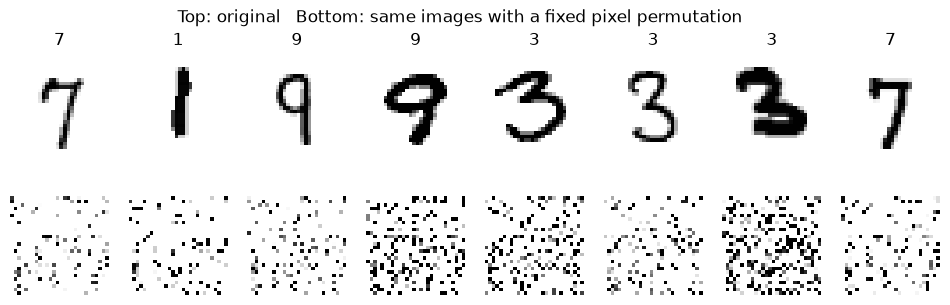

In [158]:
# 打亂像素：對每一張影像套用「同一個」固定的像素排列，再用最佳設定訓練
perm_px = np.random.default_rng(0).permutation(784)
set_seed(0)
net_perm = make_mlp((WIDTH,), "relu")
h_perm = train_torch(
    net_perm,
    X_tr[:, perm_px],
    y_tr,
    X_va[:, perm_px],
    y_va,
    lr=final_params["lr"],
    weight_decay=final_params["weight_decay"],
    n_epochs=final_params["epochs"],
    verbose=False,
)
set_seed(0)
net_orig = make_mlp((WIDTH,), "relu")
h_orig = train_torch(
    net_orig,
    X_tr,
    y_tr,
    X_va,
    y_va,
    lr=final_params["lr"],
    weight_decay=final_params["weight_decay"],
    n_epochs=final_params["epochs"],
    verbose=False,
)
print(
    f"原始像素  ：val_acc = {h_orig['val_acc'][-1]:.4f}  val_loss = {h_orig['val_loss'][-1]:.4f}"
)
print(
    f"打亂像素後：val_acc = {h_perm['val_acc'][-1]:.4f}  val_loss = {h_perm['val_loss'][-1]:.4f}"
)

fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for j in range(8):
    axes[0, j].imshow(X_tr[j].reshape(28, 28), cmap="gray_r")
    axes[1, j].imshow(X_tr[j, perm_px].reshape(28, 28), cmap="gray_r")
    axes[0, j].set_title(str(y_tr[j]))
for ax in axes.ravel():
    ax.axis("off")
fig.suptitle("Top: original   Bottom: same images with a fixed pixel permutation")
plt.show()

### TODO 18（問答）本章總結

> **(1)** 混淆矩陣。
>
> **(a)** 錯誤最多的是哪幾對（真實 → 預測）？哪個數字的錯誤率最高、哪個最低？
>
> **(b)** 對照 TODO 1 (4) 依「類別平均影像距離」做的預測：哪些猜中了、哪些沒有？平均影像的距離為什麼不能完全預測模型的混淆？（提示：平均影像抹掉了什麼？）

(a) 錯誤最多的是 (2, 7)、(4, 9) 這兩組數字，看 error rate 的話 0 最少錯，錯最多的是 9

✓。精確數字（測試集共 157 筆錯誤，「真實 → 預測」）：9 → 4（8 筆）與 4 → 9（7 筆）合計 15 筆，是錯最多的一對；接著是 7 → 2（8 筆）、5 → 3、7 → 9、2 → 8（各 5 筆）。注意方向：是「真實 7 被判成 2」，不是 2 被判成 7。

(b) (4, 9) 猜對了，但是 (2, 7) 這一組沒有出現在我們的預判裡面

✓。完整對照 TODO 1 (4) 的預測（4–9、7–9、5–8、3–5、3–8）：

- 猜中：**4–9**（最多）、**7–9**（5 筆）、**3–5**（5 → 3，5 筆）。
- 沒猜中：**7 → 2**（8 筆），以及 2 → 8。

**補充（為什麼平均影像的距離預測不了 7 → 2）**：平均影像是把每一類的所有寫法**平均掉**，代表的是「典型」的長相；典型的 2（底部有一橫）和典型的 7（上方一橫、右邊一斜線）差很多。但錯誤發生在**不典型**的寫法：底部往右勾、或中間帶一橫的 7，跟 2 的形狀很像。平均影像看不到這些「少數寫法很像另一類」的尾巴，混淆矩陣看的正是這些尾巴。

> **(2)** 最「有把握地錯」的 24 張。
>
> **(a)** 這 24 張中，你自己看得出正確答案的大約有幾張？有沒有看起來像標錯（label noise）或連人都會猶豫的？
>
> **(b)** 依 (a)：剩下的錯誤，主要是模型的問題、還是資料本身的模糊？這對「測試集 accuracy 的天花板」有什麼意義？

(a) 都能看出是什麼數字，看起來沒有標錯

✓（以你看到的 24 張為準）。補充：MNIST 確實存在少量標錯的樣本 —— 有研究用自動方法檢查，測試集中約有十幾張標籤可疑。它們不一定出現在這 24 張裡，但「最有把握地錯」的樣本是最值得懷疑標籤的地方。

(b) 因為筆畫很醜，甚至是左轉 90 度放，所以被誤判成別的數字，這是資料面的問題

**補充**：一部分是資料面，一部分其實是**模型**的限制：

- **真的模糊的**（連人都會猶豫、筆畫殘缺）→ 資料面的問題，任何模型都很難救。
- **旋轉、平移、粗細不同但人看得出來的** → 這是 MLP 的限制：MLP 沒有內建「平移或旋轉後還是同一個東西」的概念（(3) 會解釋），只能靠訓練資料裡剛好有類似的例子。資料增強（訓練時隨機旋轉、平移影像）或 CNN 可以改善這一類。
- **天花板**：人類與最好的模型在 MNIST 測試集上約 99.8%，也就是真正無法辨識的大約只有 20 張；我們的模型錯 157 張（98.43%）→ 大部分錯誤其實是「模型可以改進」的，不是資料本身的極限。

> **(3)** 打亂像素的實驗。
>
> **(a)** 打亂前後的 validation accuracy 各是多少？差多少？（打亂後的影像，人類還認得出來嗎？）
>
> **(b)** 為什麼 MLP 幾乎不受影響？（提示：第一層是 $z = xW + b$。把 $x$ 的元素換順序，等於把 $W$ 的哪個維度換順序？MLP 能表示的函數集合變了嗎？）
>
> **(c)** 由 (b)：MLP 完全不知道「哪些像素相鄰」。這代表什麼？例如同一個筆畫往右平移 2 個像素，對 MLP 來說是「相似的輸入」嗎？它要怎麼學會這件事？
>
> **(d)** 對照 LeNet-5（本章第 5 課）的兩個設計：**局部連接**（每個單元只看一小塊相鄰像素）與**權重共享**（同一個濾波器滑過整張圖）。它們分別在解決 (c) 的哪個問題？

(a) 我找不到打亂像素後的實驗在哪

**說明**：在第 7 節的**第三格程式**（「最有把握地錯的 24 張」那格的下一格，開頭是 `# 打亂像素`），你的 notebook 裡這格還沒執行，執行約需 1–2 分鐘。

驗證時用手寫 NumPy MLP（寬度 512、lr 0.1、10 epochs）跑同一個實驗的結果：**原始像素 val acc 0.9765、打亂像素後 0.9767** —— 完全沒有變差。打亂後的影像在人眼看來只是一堆雜訊（下排的圖），人類完全認不出來，MLP 卻一樣準。

(b) flatten 後換順序只是 columns 的位置變了，可是原本的模型本來就沒有記憶位置在哪裡，所以對 MLP 來說 column 移位沒什麼差別

✓。數學上的精確說法：第一層 $z = xW_1 + b_1$。把輸入 $x$ 的元素換順序（第 $j$ 個像素搬到第 $\pi(j)$ 個位置），只要把 $W_1$ 的**列**也照同樣方式換順序，輸出 $z$ 完全不變。所以「打亂像素的 MLP」和「原本的 MLP」能表示的函數集合一模一樣；權重又是隨機初始化、每一列地位平等，訓練起來在統計上也完全等價。MLP 把 784 個像素當成 784 個**沒有順序的獨立特徵**。

(c) 不知道像素相鄰表示模型完全沒有相對位置的概念，跟前面加州房價的問題一樣，平移兩個像素對 MLP 來說是不是相似的輸入，應該不是，所以這需要做資料增強或是讓模型可以提取局部特徵

✓ 完全正確，而且「跟加州房價一樣」這個類比很好：MLP 處理影像的方式，跟處理表格資料（每一欄是一個特徵、欄的順序沒有意義）完全一樣。補充「為什麼平移後不相似」：

- 一個筆畫往右平移 2 個像素，有墨水的像素幾乎**換了一批**。在 784 維空間裡，原本與平移後的兩個向量重疊很少（內積很小）→ 對 MLP 而言是兩個差很多的輸入。
- 所以 MLP 必須從資料中**分別**學會「筆畫在這裡」和「筆畫在旁邊 2 格」—— 每個位置都要重學一次，需要大量資料（也是 TODO 17 (2)(c) 要上萬筆的原因之一）。
- 兩個解法正是你說的：**資料增強**（直接把平移版本餵給模型）、或**改變模型結構**讓它天生會提取局部特徵（(d)）。

(d) LeNet-5 還沒做，你直接先講吧

**補寫（預告 LeNet-5）**：CNN 用兩個設計把「影像的結構」直接寫進模型：

- **局部連接**（local connectivity）：每個單元只看一小塊相鄰的像素（例如 5×5），而不是全部 784 個 → 模型**知道哪些像素相鄰**，可以專心學「這一小塊裡有沒有一段斜線、一個轉角」這類局部特徵。解決 (c) 的「沒有相鄰概念」。
- **權重共享**（weight sharing）：同一組 5×5 的權重（濾波器）**滑過整張圖**，在每個位置做同樣的計算 → 「斜線偵測器」只要學一次，就能在任何位置偵測到斜線。筆畫平移 2 格，偵測器的反應也只是跟著平移 2 格（平移等變性，translation equivariance）。解決 (c) 的「每個位置都要重學」。
- 再加上**池化**（pooling，取一小塊的最大值或平均）→ 對小幅平移不敏感。
- 附帶好處：參數量大幅減少（一個 5×5 濾波器只有 25 個權重，不論影像多大）。
- 預期：把 (a) 的打亂實驗套到 CNN 上，準確率會**明顯下降** —— 因為 CNN 依賴「相鄰」這個資訊，打亂後就失去了。這正好與 MLP 形成對照。

> **(4)** 看第一層權重的 32 張圖，和 TODO 2 (2) softmax 邏輯回歸的 10 張模板比較：MLP 的隱藏單元像「完整數字的模板」嗎？還是比較像局部的筆畫、邊緣、區塊？這跟 TODO 9 (3)「多張模板組合」的說法一致嗎？

是完整的數字模板，局部的筆畫邊緣區塊其實還是有些特徵沒有被模型學習

**修正**：仔細看會發現第一層的權重圖**幾乎像雜訊**，既不是完整的數字模板，也看不太出筆畫。原因與正確的看法：

- 權重 = 隨機初始化 $W_0$ ＋ 訓練學到的改變 $\Delta W$。驗證時測量：訓練 10 個 epoch 後 $\|W - W_0\| / \|W_0\| \approx 0.22$ —— 權重只離初始值走了約 22%，圖上看到的主要是**初始化的雜訊**。
- 把學到的部分 $\Delta W = W - W_0$ 單獨畫出來（驗證時做的），會看到**局部的筆畫片段、斑塊、數字的一部分**（某個轉角、一段弧、上半部的一橫），通常集中在影像中央 —— **不是完整的數字**。
- 這跟 softmax 邏輯回歸的 10 張模板（每張都像一個完整、模糊的數字）不同：MLP 的每個隱藏單元只負責一個**局部特徵或部分寫法**，輸出層再把這些「零件」組合成數字的判斷 —— 這就是 TODO 9 (3)「多張模板組合」的實際樣子。
- 想自己看 $\Delta W$：在訓練前存下 `W0 = net[0].weight.detach().clone()`，訓練後畫 `net[0].weight.detach() - W0`（列入待補強）。

---
## 8. 本章小結

### 方法與結果

MNIST（train 50,000／validation 10,000／test 10,000；最終模型在 train + validation 共 60,000 筆上 refit）。validation 為各模型訓練時的 validation accuracy；test 只評估一次。

| 方法 | 做法 | 關鍵性質 | val acc | test acc | test log loss |
| --- | --- | --- | --- | --- | --- |
| Dummy prior | 輸出類別比例 | log loss = $\ln 10 \approx 2.30$ | 0.112 | 0.114 | 2.301 |
| Softmax 邏輯回歸（sklearn） | 一層線性 + softmax | 每類一張模板 | 0.914 | 0.921 | 0.311 |
| MLP 784–256–10，無激活（手寫） | 兩個 Linear 直接相接 | 合成一個 $W_{\text{eff}} = W_1W_2$，等同邏輯回歸 | 0.908 | — | — |
| MLP 784–256–10，ReLU（手寫 NumPy） | 每層 forward／backward，SGD lr 0.1、10 epochs | 梯度檢查誤差 ~1e-10；與 autograd 差 ~1e-16 | 0.976 | 0.978 | 0.075 |
| MLP 784–256–10，ReLU（PyTorch） | autograd ＋ `optim.SGD`，同超參數 | 預設初始化比 He 小約 2.4 倍 | 0.975 | 0.977 | 0.074 |
| MLP 784–512–10，ReLU（調參後，PyTorch） | lr 0.3、weight decay 1e-4、15 epochs，refit 60,000 筆 | 寬度、lr × wd 搜尋；seed 標準差 0.0006 | 0.983 | **0.984** | **0.053** |

- 測試集錯 157 筆：最多的是 4 ↔ 9（15 筆）、7 → 2（8 筆）。
- 打亂像素（每張影像同一個固定排列）後，MLP 的準確率完全不變（驗證：0.9765 → 0.9767）→ MLP 沒有用到像素相鄰的資訊。

### 核心觀念

1. **MLP = Linear ＋ 非線性激活的合成**。沒有激活函數時，多層 Linear 合成一個矩陣（$W_{\text{eff}} = W_1W_2\cdots$），不論多深都等同邏輯回歸；ReLU 讓網路成為分段線性函數，每個隱藏單元像「模板＋門檻」的偵測器，輸出層把偵測器組合起來（同一類可以有多張模板）。
2. **反向傳播 = 鏈鎖律，每一層只管自己**：`backward(dout)` 收到 $\partial L/\partial\,\text{out}$，乘上自己的局部導數，回傳 $\partial L/\partial X$ 給前一層；$L$ 的完整式子不需要知道。Linear：$\partial L/\partial W = X^\top\cdot\text{dout}$、$\partial L/\partial b = \text{dout}$ 沿 batch 加總、$\partial L/\partial X = \text{dout}\cdot W^\top$；激活函數：$\text{dout}\odot f'(z)$。加總哪個下標，看「這個變數被誰用到」。
3. **softmax ＋ 交叉熵的梯度是 $(P - Y)/n$**：$\log$ 抵消 $\exp$，只剩「預測 − 答案」；二元時就是邏輯回歸的 $\sigma(z) - y$。合在一起算避開了 $K\times K$ 的 Jacobian（$O(K^2) \to O(K)$）與 $-1/p_y$ 的溢位。
4. **一次更新分三個階段**：forward（存 cache）→ backward（算出**所有**梯度，參數不變）→ 更新（所有參數一起）。所有梯度必須在同一組參數上算，不能邊傳邊更新；更新的順序不影響結果。
5. **梯度檢查**：中央差分 $\frac{f(x+\varepsilon)-f(x-\varepsilon)}{2\varepsilon}$ 與解析梯度比相對誤差（float64，< 1e-7）。數值微分每個參數要 2 次 forward（203,530 個參數 → 約 41 萬次），反向傳播約 3 次 forward 的成本 —— 這是反向傳播的意義。
6. **計算量 ≠ 時間**：backward 的乘加次數約是 forward 的 2 倍（每層兩次矩陣乘法），第一層的 $\partial L/\partial X$ 不需要算；但小 batch 時固定開銷（函式呼叫、建陣列）佔主導，實測比例可能遠小於 2。
7. **初始化**：權重必須隨機以**打破對稱**（相同的權重 → 相同的輸出、梯度、更新，64 個單元等於 1 個，rank = 1）。尺度：$\text{Var}(z) = \text{fan}_{\text{in}}\cdot\text{Var}(W)\cdot E[h^2]$，要讓每層倍數為 1 → $\text{Var}(W) \approx 1/\text{fan}_{\text{in}}$（Xavier 取 $2/(\text{fan}_{\text{in}}+\text{fan}_{\text{out}})$）；ReLU 把一半的樣本變成 0（$E[\text{ReLU}(z)^2] = \frac12 E[z^2]$），所以 He 用 $2/\text{fan}_{\text{in}}$。全部初始化成 0 時只有最後一層的 bias 學得到。
8. **梯度消失與爆炸是同一件事**：每層的倍數（權重大小 × 激活函數的導數）≠ 1，乘上很多層就是指數級變化。sigmoid 的導數最大 0.25（10 層後 ≤ $10^{-6}$，與實測吻合）；tanh 在 0 附近、ReLU 在正半邊的導數都是 1；太大的權重讓 tanh 飽和、梯度往輸入方向爆炸。
9. **學習率**：太小 → 慢；太大 → ReLU 死掉、卡在接近亂猜（交叉熵的梯度有界，不會變 nan）。非凸、曲率隨位置變，無法事先算出上限 → log 尺度掃描、LR range test、warmup 與衰減。
10. **batch size**：固定 epoch 時，小 batch 更新次數多、通常較好；batch loss 的雜訊約與 $1/\sqrt{m}$ 成正比。linear scaling rule（batch × $k$、lr × $k$）在 lr 超過穩定上限、訓練初期、或 batch 超過臨界值時失效（本章實驗即是）。總乘加次數相同，但小 batch 固定開銷多、硬體用不滿。
11. **PyTorch autograd**：forward 時記錄計算圖（每個 tensor 的 `grad_fn` 指向該運算的 backward，並存下需要的值 = cache）；`loss.backward()` 沿圖倒著走 = `MLP.backward` 的迴圈；`opt.step()` = `MLP.step`。`.grad` 會**累加**（同一參數多條路徑的梯度要相加），所以每次更新前要 `zero_grad()`；不自動清是為了 gradient accumulation 等需要跨多次 backward 的做法。`nn.Linear` 的權重存成 $(d_{\text{out}}, d_{\text{in}})$，預設初始化不是 He。
12. **驗證方式**：資料夠大時用固定的 validation set（$n = 10{,}000$，標準誤 0.14–0.27%），5-fold 的成本是 5 倍；深度學習的「平均 ± 標準差」來自換 seed。差距小於 seed 標準差的設定分不出優劣（one-standard-error rule）；最佳值落在搜尋範圍邊界時要擴大範圍。
13. **容量與 early stopping**：寬度 16 → 1024（參數 64 倍）val 沒有反轉變差、train／val 差距幾乎不變（SGD 的隱式正則化、過參數化）。訓練時間也是容量：val loss 在最低點後上升而 val acc 持平（少數「有把握地錯」主導 log loss）；early stopping 限制 $W$ 離初始值的距離，效果類似 L2。用 validation 選出的 epoch 數是超參數，被選中的 val 分數偏樂觀，最終成績看測試集。
14. **診斷**：學習曲線（小資料時 train ≈ 1.0、val 差很多；資料越多差距越小、val 仍在進步）→ 下一步加資料或資料增強，而不是加大網路。MLP 對像素順序完全不敏感（打亂後準確率不變），把影像當成沒有順序的表格特徵，必須從資料中分別學會每個位置 → CNN 的局部連接與權重共享（LeNet-5）。第一層權重 ≈ 初始化雜訊 ＋ 學到的局部筆畫片段（$\Delta W$），不是完整的數字模板。

### 待補強（之後回來可以學）

**理論**
- ☐ 萬能近似定理（universal approximation theorem）：一個夠寬的隱藏層能近似任何連續函數，以及「深」相對於「寬」的優勢
- ☐ 過參數化與 double descent；SGD 的隱式正則化；flat vs sharp minima 與 batch size 對推廣的影響
- ☐ 線性模型上 early stopping ≈ L2 正則化的推導
- ☐ 指數族分布與 canonical link：為什麼 MSE、交叉熵的梯度都是「預測 − 答案」
- ☐ 不可微程式的自動微分（nonsmooth AD、Clarke 次微分、conservative fields）

**最佳化**
- ☐ Momentum、Adam 等自適應方法（第三章 CNN 會在 CIFAR-10 上比較）
- ☐ 學習率排程：warmup、cosine decay、LR range test 實作
- ☐ 臨界 batch size（critical batch size）與 linear scaling rule 的界線
- ☐ 用 Hessian-向量乘積與冪次法估計訓練中的最大曲率

**訓練技巧**
- ☐ BatchNorm、Dropout、殘差連接（第三章）
- ☐ 資料增強：在 MNIST 上隨機平移、旋轉，觀察能修正多少「有把握地錯」的樣本
- ☐ 梯度裁剪（gradient clipping，RNN 那章）

**數值與工程**
- ☐ `torch.autograd.Function` 自訂 backward 與 `torch.autograd.gradcheck`
- ☐ Gradient checkpointing（用重算換記憶體）、gradient accumulation 實作
- ☐ `DataLoader` 與影像 transform 的效能（LeNet-5 那章）
- ☐ float32 vs float64、MPS 的限制（不支援 float64）

**評估與分析**
- ☐ 在同一個測試集上比較兩個分類器的統計檢定（McNemar 檢定）
- ☐ MNIST 的標籤錯誤（以自動方法找出可疑標籤）
- ☐ MLP 輸出機率的校準（calibration），與邏輯回歸比較
- ☐ 視覺化學到的權重 $\Delta W = W - W_0$（訓練前存下初始權重）